<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-06/lab-026-beta-vae.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 026 <br>
<hr/>

# Lab 026 — Disentangled representations and the β-VAE

This notebook continues the story of Lab 024 and asks what the coordinates of a latent space *mean*. The story has six steps, each motivated by the one before. An autoencoder compresses images into a few numbers, but it puts no probability distribution on them: its codes form islands with holes in between, and a random latent vector decodes to garbage, so the autoencoder cannot be sampled. A variational autoencoder (VAE) repairs this by modelling the distribution: the encoder gives each image a cloud of latent vectors, a loss term pulls all clouds onto the prior $\mathcal N(0,I)$, and new images are generated by drawing $\mathbf z\sim\mathcal N(0,I)$ and decoding. Once the latent vectors follow a well-behaved distribution, we can ask what each coordinate does, and in a plain VAE the answer is disappointing: moving one coordinate changes several features of the image at once. The goal is therefore a code in which one coordinate carries one distinct, independent feature, a **disentangled** representation. The **β-VAE** pursues it with a single change to the loss, a weight $\beta>1$ on the Kullback–Leibler (KL) term, which pushes the coordinates towards independence at the price of the reconstruction quality. Finally we compare this with conditioning on a known factor, as in the conditional VAE (cVAE) of Labs 024 and 025, use the β-VAE to interpret spin configurations, and state the limits of the whole idea.

Section 1 retraces the first four steps on MNIST, with small models trained here, and Section 2 develops the β-weighted loss carefully: from the evidence lower bound (ELBO), through the trade-off between *rate* (the information in the code) and *distortion* (the reconstruction error), to a free-energy reading in which $\beta$ is a temperature, and a decomposition of the rate whose middle term, the *total correlation* (TC), measures how dependent the latent coordinates are. The remaining sections use four data sets, each for its own purpose. On MNIST (Section 3) we watch the loss at work: a sweep over $\beta$ shows the rate–distortion trade-off, the blur growing with $\beta$, latent coordinates switching off, and the effect on samples. MNIST has no list of true factors, so disentangling cannot be measured there; dSprites (Section 4), a synthetic set of sprite images ("disentanglement testing sprites") generated from five known factors, lets us measure it with the mutual information gap (MIG), a score between 0 and 1 that says how much more one latent coordinate knows about each factor than any other coordinate (defined in Section 4.2). CelebA (CelebFaces Attributes, Section 5), a set of celebrity photographs annotated with 40 binary attributes, is the visual story: faces, their traversals and the arithmetic "with glasses minus without glasses". Section 6 turns to physics and uses the β-VAE as an interpretability tool on Monte Carlo snapshots of the Ising and $J_1$–$J_2$ models. Section 7 compares discovering factors with conditioning on them.

The implementation uses JAX with `flax.nnx` and `optax` and runs on the CPU. Trained parameters are stored in `checkpoints/`, so a second run of the notebook loads them instead of training again; the first run takes about 45 (most of it for the CelebA model of Section 5) minutes on 8 CPU cores. Figures for the Lecture 6 slides are saved to `../beamer/figures/gen_bvae_*.png`, at the size at which they appear on the slides, and the numbers quoted there to `../beamer/figures/numbers_lab026.json`.

> **How to run this notebook in Google Colab**
> 1. Upload the notebook (*File → Upload notebook*). The first code cell sets `JAX_PLATFORMS=cpu`; with a GPU runtime you can delete that line.
> 2. `jax`, `flax`, `optax`, `matplotlib` and `pyarrow` are pre-installed in Colab.
> 3. The data are read from `data/`: MNIST from `data/MNIST_raw/` (as in Lab 024), dSprites from `data/dsprites/`, the CelebA subset from `data/celeba/celeba32.npz`, and the spin snapshots of Lab 025 from `data/ising_L30.npz` and `data/j1j2_L32.npz`. MNIST, dSprites and CelebA are downloaded if missing (CelebA: about 2 GB of raw data, from which a 100 MB file is made once).
> 4. Run the cells in order.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import gzip, io, json, time, urllib.request
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, FancyArrowPatch

import jax, jax.numpy as jnp
import optax
import flax
from flax import nnx

# style of figures shown only in the notebook
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# style of figures for the slides: drawn at their size on the slide (inches), so 10-12 pt here is 10-12 pt there
SLIDE = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
         "legend.fontsize": 10, "figure.titlesize": 12, "lines.linewidth": 1.5, "figure.dpi": 150}
FULL, WIDE, HALF = 5.5, 4.4, 2.7          # slide widths: \textwidth, 0.8\textwidth, 0.49\textwidth
UJBlue, UJNavy, DSOrange, UJGray, Green = "#005CA7", "#002B5C", "#D35A05", "#5A6270", "#2E8B57"

OUT, DATA, CKPT = "../beamer/figures", "data", "checkpoints"
for d in (OUT, DATA, CKPT):
    os.makedirs(d, exist_ok=True)
def save(fig, name):
    '''Slide figure: drawn at its slide width; only empty margins are cropped, so the text can only get larger on the slide.'''
    fig.savefig(f"{OUT}/gen_bvae_{name}.png", dpi=250, bbox_inches="tight", pad_inches=0.02)

nums = {}                                 # numbers quoted on the slides
t_start = time.time()
print("JAX", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__)
print("devices:", jax.devices())

JAX 0.11.0 | flax 0.12.8 | optax 0.2.6


devices: [CpuDevice(id=0)]


<hr/>
## 1. From autoencoders to disentangled codes

### 1.1 Data, networks and training

We work first with MNIST, $28\times28$ grey-scale digits, $60\,000$ for training and $10\,000$ for testing [Y. LeCun *et al.*, Proc. IEEE **86**, 2278 (1998), [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791)]. The images are kept as `uint8` arrays, $(n,784)$, and divided by 255 inside each loss, one minibatch at a time; this keeps the memory small for the larger data sets of later sections.

In [2]:
MNIST_DIR = f"{DATA}/MNIST_raw"
MNIST_FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
if not all(os.path.exists(f"{MNIST_DIR}/{f}") for f in MNIST_FILES):
    os.makedirs(MNIST_DIR, exist_ok=True)
    for f in MNIST_FILES:
        urllib.request.urlretrieve(f"https://storage.googleapis.com/cvdf-datasets/mnist/{f}", f"{MNIST_DIR}/{f}")

def read_idx(path):
    with gzip.open(path, "rb") as fh:
        data = fh.read()
    ndim = data[3]
    shape = np.frombuffer(data[4:4 + 4 * ndim], dtype=">i4")
    return np.frombuffer(data[4 + 4 * ndim:], dtype=np.uint8).reshape(shape)

Xtr_m = jnp.asarray(read_idx(f"{MNIST_DIR}/{MNIST_FILES[0]}").reshape(-1, 784))   # (60000, 784) uint8
ytr = read_idx(f"{MNIST_DIR}/{MNIST_FILES[1]}").astype(np.int32)
Xte_m = jnp.asarray(read_idx(f"{MNIST_DIR}/{MNIST_FILES[2]}").reshape(-1, 784))   # (10000, 784) uint8
yte = read_idx(f"{MNIST_DIR}/{MNIST_FILES[3]}").astype(np.int32)
to_unit = lambda x: x.astype(jnp.float32) / 255.0                                  # uint8 -> [0, 1]
print("MNIST train", Xtr_m.shape, "test", Xte_m.shape)

MNIST train (60000, 784) test (10000, 784)


All models of this notebook are trained by the same function, the one of Lab 024: `nnx.split` separates a model into its structure and its parameters, so that the loss becomes a pure function of the parameters, a minibatch and a random key; `optax.adam` updates the parameters; and one epoch is one jit-compiled `jax.lax.scan` over the minibatches. Training is the slow part of the notebook, so `fit` first looks for stored parameters in `checkpoints/<name>.npz`. If they exist it loads them, together with the training history and the training time; otherwise it trains and stores them.

In [3]:
def train(model, loss_fn, data, epochs, seed, batch_size=128, lr=1e-3, log_every=5):
    '''Adam; one jit-compiled lax.scan per epoch. data: tuple of arrays with the same first dimension.'''
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.adam(lr)
    opt_state = tx.init(params)
    n = data[0].shape[0]
    n_batches = n // batch_size

    def batch_loss(params, batch, key):
        return loss_fn(nnx.merge(graphdef, params, rest), batch, key)

    @jax.jit
    def train_epoch(params, opt_state, data, key):
        k_perm, k_steps = jax.random.split(key)
        idx = jax.random.permutation(k_perm, n)[: n_batches * batch_size].reshape(n_batches, batch_size)
        keys = jax.random.split(k_steps, n_batches)
        def step(carry, inp):
            params, opt_state = carry
            batch_idx, k = inp
            batch = tuple(a[batch_idx] for a in data)
            (loss, aux), grads = jax.value_and_grad(batch_loss, has_aux=True)(params, batch, k)
            updates, opt_state = tx.update(grads, opt_state, params)
            return (optax.apply_updates(params, updates), opt_state), aux
        (params, opt_state), aux = jax.lax.scan(step, (params, opt_state), (idx, keys))
        return params, opt_state, jax.tree.map(jnp.mean, aux)

    key, history, t0 = jax.random.key(seed), [], time.time()
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, opt_state, aux = train_epoch(params, opt_state, data, sub)
        history.append({k: float(v) for k, v in aux.items()})
        if ep == 0 or (ep + 1) % log_every == 0 or ep + 1 == epochs:
            print(f"  epoch {ep + 1:3d}: " + "  ".join(f"{k} {v:.3f}" for k, v in history[-1].items())
                  + f"   ({time.time() - t0:5.1f} s)")
    nnx.update(model, params)
    return model, {k: [h[k] for h in history] for k in history[0]}

def fit(name, model, loss_fn, data, epochs, seed, **kw):
    '''Load checkpoints/<name>.npz if it exists, otherwise train and store. Returns (model, history dict).'''
    path, hpath = f"{CKPT}/{name}.npz", f"{CKPT}/{name}.json"
    _, params, _ = nnx.split(model, nnx.Param, ...)
    leaves, treedef = jax.tree_util.tree_flatten(params)
    if os.path.exists(path) and os.path.exists(hpath):
        f = np.load(path)
        new = [jnp.asarray(f[f"p{i}"]) for i in range(len(leaves))]
        assert all(a.shape == b.shape for a, b in zip(new, leaves)), "checkpoint does not match the model"
        nnx.update(model, jax.tree_util.tree_unflatten(treedef, new))
        hist = json.load(open(hpath))
        print(f"{name}: loaded from {path} (trained for {hist['epochs']} epochs in {hist['seconds']:.0f} s)")
        return model, hist
    print(f"{name}: training")
    t0 = time.time()
    model, hist = train(model, loss_fn, data, epochs, seed, **kw)
    hist.update(seconds=time.time() - t0, epochs=epochs)
    _, params, _ = nnx.split(model, nnx.Param, ...)
    np.savez(path, **{f"p{i}": np.asarray(l) for i, l in enumerate(jax.tree_util.tree_leaves(params))})
    json.dump(hist, open(hpath, "w"))
    return model, hist

def in_chunks(fn, *arrays, chunk=2000):
    '''Apply fn to chunks of the arrays and concatenate (keeps the memory small).'''
    outs = [fn(*(a[i:i + chunk] for a in arrays)) for i in range(0, arrays[0].shape[0], chunk)]
    return jax.tree.map(lambda *xs: np.concatenate([np.asarray(x) for x in xs]), *outs)

def n_params(model):
    return sum(p.size for p in jax.tree_util.tree_leaves(nnx.state(model, nnx.Param)))

Two quantities appear in every loss of this notebook, and we define them carefully once.

The **binary cross-entropy (BCE)** measures how well predicted pixel probabilities $\hat x_j\in(0,1)$ explain observed pixel values $x_j\in[0,1]$, $j=1,\dots,D$:
$$\mathrm{BCE}(\mathbf x,\hat{\mathbf x})=-\sum_{j=1}^{D}\big[x_j\log\hat x_j+(1-x_j)\log(1-\hat x_j)\big].$$
For black-and-white pixels it is exactly $-\log p_\theta(\mathbf x|\mathbf z)$, minus the log-probability that independent Bernoulli pixels with probabilities $\hat x_j$ produce the image $\mathbf x$; each pixel contributes $-\log\hat x_j$ if it is white and $-\log(1-\hat x_j)$ if it is black. It is measured in nats (natural logarithm). It is 0 only for a perfect and fully confident prediction, it grows without bound for a confident wrong prediction, and a decoder that answers $\hat x_j=\tfrac12$ everywhere pays $D\log2$ nats per image (543 nats for MNIST). For grey values $x_j$ between 0 and 1 the formula is still a valid reconstruction error, smallest at $\hat x_j=x_j$, but its minimum is then above zero. We use it as the **distortion**: the reconstruction error of the VAE.

The **Kullback–Leibler (KL) divergence** measures how different a distribution $q$ is from a reference distribution $p$,
$$\begin{aligned}\mathrm{KL}(q\,\|\,p)&=\mathbb E_{\mathbf z\sim q}\Big[\log\frac{q(\mathbf z)}{p(\mathbf z)}\Big]\\&=\int q(\mathbf z)\log\frac{q(\mathbf z)}{p(\mathbf z)}\,d\mathbf z\;\ge0 ,\end{aligned}$$
with equality only for $q=p$ (Lab 024 proves this with Jensen's inequality). It is the average, over samples of $q$, of how much more probable each sample is under $q$ than under $p$, in nats; it is not symmetric in $q$ and $p$. Between the encoder's cloud $\mathcal N(\mu,\sigma^2)$ and the prior $\mathcal N(0,1)$ it has the closed form $\tfrac12(\mu^2+\sigma^2-\ln\sigma^2-1)$ (Lab 024), and for a diagonal Gaussian in $d$ dimensions it is the sum of $d$ such terms, one per coordinate. It is zero only when the cloud *is* the prior, $\mu=0$, $\sigma=1$, i.e. when the code says nothing about the image; we use it as the **rate**, the price of the information the code carries.

In code we need, besides these two, the logarithm of a Gaussian density and the reparametrisation $\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon$ with $\boldsymbol\varepsilon\sim\mathcal N(0,I)$, which makes the random draw of $\mathbf z$ differentiable with respect to $\boldsymbol\mu$ and $\boldsymbol\sigma$ (Lab 024).

The networks are those of Lab 024. The autoencoder `DenseAE` maps $\mathbf x$: $(B,784)\to(B,256)\to(B,64)\to\mathbf z$: $(B,d)$ and back, with a sigmoid output, trained on the mean squared error (MSE) between image and reconstruction, $\mathrm{MSE}=\frac1D\sum_{j=1}^D(x_j-\hat x_j)^2$, the average squared pixel difference, which is 0 for a perfect reconstruction. The VAE `DenseVAE` maps $\mathbf x$: $(B,D)\to(B,400)\to(B,200)$ and then, through two separate linear heads, to $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, each $(B,d)$; the decoder maps $\mathbf z$: $(B,d)\to(B,200)\to(B,400)\to$ logits $(B,D)$, the Bernoulli pixel probabilities being $\sigma(\text{logits})$. The same class, with other sizes, serves dSprites and the spin models later. `bvae_loss(beta)` returns the β-weighted loss of Section 2, $\mathrm{BCE}+\beta\,\mathrm{KL}$ per image, with the BCE as reconstruction error; for $\beta=1$ it is the VAE loss of Lab 024.

In [4]:
def kl_per_dim(mu, logvar):
    '''KL( N(mu, sigma^2) || N(0, 1) ) for every latent coordinate; sigma^2 = exp(logvar). Same shape as mu.'''
    return 0.5 * (mu ** 2 + jnp.exp(logvar) - logvar - 1)

def log_normal(z, mu, logvar):
    '''log N(z; mu, sigma^2), elementwise.'''
    return -0.5 * (jnp.log(2 * jnp.pi) + logvar + (z - mu) ** 2 / jnp.exp(logvar))

def reparametrise(mu, logvar, key):
    '''z = mu + sigma * eps, eps ~ N(0, I).'''
    return mu + jnp.exp(0.5 * logvar) * jax.random.normal(key, mu.shape)


class DenseAE(nnx.Module):
    '''Autoencoder: x (B, 784) -> 256 -> 64 -> z (B, d) -> 64 -> 256 -> sigmoid (B, 784).'''
    def __init__(self, d, *, rngs):
        self.enc = nnx.List([nnx.Linear(784, 256, rngs=rngs), nnx.Linear(256, 64, rngs=rngs), nnx.Linear(64, d, rngs=rngs)])
        self.dec = nnx.List([nnx.Linear(d, 64, rngs=rngs), nnx.Linear(64, 256, rngs=rngs), nnx.Linear(256, 784, rngs=rngs)])
    def encode(self, x):
        for layer in self.enc[:-1]: x = nnx.relu(layer(x))
        return self.enc[-1](x)
    def decode(self, z):
        for layer in self.dec[:-1]: z = nnx.relu(layer(z))
        return nnx.sigmoid(self.dec[-1](z))

def ae_loss(model, batch, key):
    x = to_unit(batch[0])
    mse = jnp.mean((model.decode(model.encode(x)) - x) ** 2)
    return mse, {"mse": mse}

class DenseVAE(nnx.Module):
    '''Dense VAE with Bernoulli pixels.
    encoder: x (B, D) -> h1 -> h2 -> mu (B, d), logvar (B, d);   decoder: z (B, d) -> h2 -> h1 -> logits (B, D)'''
    def __init__(self, D, d, hidden=(400, 200), *, rngs):
        h1, h2 = hidden
        self.enc = nnx.List([nnx.Linear(D, h1, rngs=rngs), nnx.Linear(h1, h2, rngs=rngs)])
        self.mu = nnx.Linear(h2, d, rngs=rngs)
        self.logvar = nnx.Linear(h2, d, rngs=rngs)
        self.dec = nnx.List([nnx.Linear(d, h2, rngs=rngs), nnx.Linear(h2, h1, rngs=rngs), nnx.Linear(h1, D, rngs=rngs)])
    def encode(self, x):
        h = x.reshape(x.shape[0], -1)
        for layer in self.enc:
            h = nnx.relu(layer(h))
        return self.mu(h), self.logvar(h)
    def decode(self, z):
        h = z
        for layer in self.dec[:-1]:
            h = nnx.relu(layer(h))
        return self.dec[-1](h)

def bvae_loss(beta):
    '''L_beta = BCE reconstruction + beta * KL, per image, averaged over the minibatch; batch = (x_uint8,).'''
    def loss_fn(model, batch, key):
        x = to_unit(batch[0])
        mu, logvar = model.encode(x)                                        # (B, d) each
        z = reparametrise(mu, logvar, key)                                  # (B, d)
        logits = model.decode(z).reshape(x.shape)
        rec = optax.sigmoid_binary_cross_entropy(logits, x).reshape(x.shape[0], -1).sum(-1).mean()   # distortion
        kl = kl_per_dim(mu, logvar).sum(-1).mean()                          # rate
        return rec + beta * kl, {"loss": rec + beta * kl, "D": rec, "R": kl}
    return loss_fn

enc_fn = nnx.jit(lambda m, x: m.encode(x))                       # (mu, logvar)
dec_fn = nnx.jit(lambda m, z: jax.nn.sigmoid(m.decode(z)))       # decoder mean: pixel probabilities

@nnx.jit
def rate_distortion(model, x_u8, key):
    '''Per image: distortion D (BCE with one z ~ q(z|x)), rate R (closed-form KL), and KL per coordinate.'''
    x = to_unit(x_u8)
    mu, lv = model.encode(x)
    logits = model.decode(reparametrise(mu, lv, key)).reshape(x.shape)
    D = optax.sigmoid_binary_cross_entropy(logits, x).reshape(x.shape[0], -1).sum(-1)
    kl = kl_per_dim(mu, lv)
    return D, kl.sum(-1), kl

D_LATENT = 10
_m = DenseVAE(784, D_LATENT, rngs=nnx.Rngs(0))
_mu, _lv = _m.encode(to_unit(Xtr_m[:5]))
assert _mu.shape == _lv.shape == (5, D_LATENT) and _m.decode(_mu).shape == (5, 784)
print("parameters of the MNIST VAE with d = 10:", n_params(_m))
print(nnx.tabulate(_m, to_unit(Xtr_m[:2]), method="encode", depth=2))

parameters of the MNIST VAE with d = 10: 795204


                                 DenseVAE Summary                                  
┏━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path   ┃ type     ┃ inputs         ┃ outputs         ┃ Param                    ┃
┡━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encode │ DenseVAE │ float32[2,784] │ - float32[2,10] │ 795,204 (3.2 MB)         │
│        │          │                │ - float32[2,10] │                          │
├────────┼──────────┼────────────────┼─────────────────┼──────────────────────────┤
│ enc/0  │ Linear   │ float32[2,784] │ float32[2,400]  │ bias: float32[400]       │
│        │          │                │                 │ kernel: float32[784,400] │
│        │          │                │                 │                          │
│        │          │                │                 │ 314,000 (1.3 MB)         │
├────────┼──────────┼────────────────┼─────────────────┼──────────────────────────┤
│ enc/1  │ Linear   │ float32[2,400] │ float32[2,200]  │ bias: float32[200]       │
│        │          │                │                 │ kernel: float32[400,200] │
│        │          │                │                 │                          │
│        │          │                │                 │ 80,200 (320.8 KB)        │
├────────┼──────────┼────────────────┼─────────────────┼──────────────────────────┤
│ mu     │ Linear   │ float32[2,200] │ float32[2,10]   │ bias: float32[10]        │
│        │          │                │                 │ kernel: float32[200,10]  │
│        │          │                │                 │                          │
│        │          │                │                 │ 2,010 (8.0 KB)           │
├────────┼──────────┼────────────────┼─────────────────┼──────────────────────────┤
│ logvar │ Linear   │ float32[2,200] │ float32[2,10]   │ bias: float32[10]        │
│        │          │                │                 │ kernel: float32[200,10]  │
│        │          │                │                 │                          │
│        │          │                │                 │ 2,010 (8.0 KB)           │
├────────┼──────────┼────────────────┼─────────────────┼──────────────────────────┤
│        │          │                │           Total │ 795,204 (3.2 MB)         │
└────────┴──────────┴────────────────┴─────────────────┴──────────────────────────┘
                                                                                   
                        Total Parameters: 795,204 (3.2 MB)                         

The table printed by `nnx.tabulate` is the library's view of the encoder: every layer with its input and output shapes and its parameters. The drawing below shows the whole VAE as a graph, with circles for units and lines for weights. The encoder narrows from the image to the two heads $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, both connected to the last hidden layer; the dotted lines from the heads to $\mathbf z$ carry no weights, they are the reparametrisation $\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon$; the decoder widens back to the image. Wide layers are drawn with a few circles and a vertical ellipsis. Counting the weights and biases of the drawn layers, $784\cdot400+400+400\cdot200+200+2(200\cdot10+10)+10\cdot200+200+200\cdot400+400+400\cdot784+784$, reproduces the parameter count printed above. For the convolutional network of Section 5 the function `draw_conv_vae` draws every layer as a block of feature maps, with height proportional to the image size and depth growing with the number of channels.

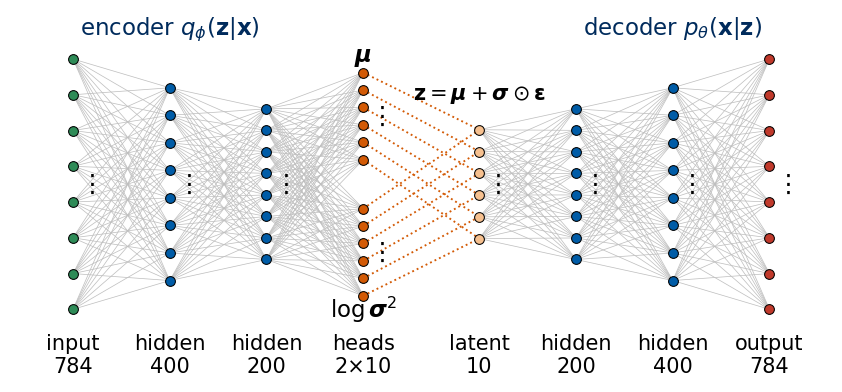

In [5]:
def draw_dense_vae(enc_sizes, d, dec_sizes, ax, max_nodes=8, title=""):
    '''Draw a dense VAE as nodes and edges.
    enc_sizes: widths of the encoder layers, starting with the input, e.g. [784, 400, 200]
    d:         latent dimension (the two heads mu, log sigma^2 and the sample z have d units each)
    dec_sizes: widths of the decoder layers after z, ending with the output, e.g. [200, 400, 784]'''
    n_max = max(enc_sizes + dec_sizes)
    def ypos(n, yc=0.0, half=None, cap=max_nodes):
        '''Vertical positions of the drawn units of a layer of width n: at most `cap` circles, centred at yc;
        the drawn height grows like sqrt(n), so wide layers look wide and the encoder visibly narrows.'''
        half = 0.45 + 1.85 * np.sqrt(n / n_max) if half is None else half
        return yc + np.linspace(-half, half, min(n, cap))
    def nodes(x, ys, n, color):
        '''Draw the circles of one layer; a vertical ellipsis marks units that are not drawn.'''
        ax.scatter(np.full(len(ys), x), ys, s=22, color=color, edgecolor="k", lw=0.5, zorder=3)
        if n > len(ys):
            ax.text(x + 0.2, ys.mean(), "⋮", fontsize=12, ha="center", va="center", zorder=4)
    def edges(x0, y0, x1, y1, **kw):
        '''All-to-all lines between two drawn layers: one line per drawn weight of a dense layer.'''
        for a in y0:
            for b in y1:
                ax.plot([x0, x1], [a, b], **({"color": "0.75", "lw": 0.35, "zorder": 1} | kw))
    def label(x, text, n):
        ax.text(x, -2.75, f"{text}\n{n}", ha="center", va="top", fontsize=10)
    # encoder: input and hidden layers, narrowing towards the latent space
    x, prev = 0.0, None
    for i, n in enumerate(enc_sizes):
        ys = ypos(n)
        nodes(x, ys, n, Green if i == 0 else UJBlue); label(x, "input" if i == 0 else "hidden", n)
        if prev is not None: edges(x - 1, prev, x, ys)
        prev, x = ys, x + 1
    # the two heads mu and log sigma^2, both fed by the last hidden layer
    mu_y, lv_y = ypos(d, 1.25, 0.8, 6), ypos(d, -1.25, 0.8, 6)
    for ys, txt, yt in [(mu_y, "$\\boldsymbol{\\mu}$", 2.25), (lv_y, "$\\log\\boldsymbol{\\sigma}^2$", -2.45)]:
        nodes(x, ys, d, DSOrange); edges(x - 1, prev, x, ys); ax.text(x, yt, txt, ha="center", fontsize=11)
    label(x, "heads", f"2×{d}")
    # the latent sample z = mu + sigma * eps: no weights, dotted one-to-one links
    zx, z_y = x + 1.2, ypos(d, 0.0, 1.0, 6)
    nodes(zx, z_y, d, "#F6C08F"); label(zx, "latent", d)
    for a, b, c in zip(mu_y, lv_y, z_y):
        ax.plot([x, zx], [a, c], ls=":", color=DSOrange, lw=0.9); ax.plot([x, zx], [b, c], ls=":", color=DSOrange, lw=0.9)
    ax.text(zx, 1.55, "$\\mathbf{z}=\\boldsymbol{\\mu}+\\boldsymbol{\\sigma}\\odot\\boldsymbol{\\varepsilon}$", ha="center", fontsize=10)
    # decoder: widening back to the image
    prev, x = z_y, zx + 1
    for i, n in enumerate(dec_sizes):
        last = i == len(dec_sizes) - 1
        ys = ypos(n)
        nodes(x, ys, n, "#C0392B" if last else UJBlue); label(x, "output" if last else "hidden", n)
        edges(x - 1, prev, x, ys)
        prev, x = ys, x + 1
    ax.text((len(enc_sizes) - 1) / 2, 2.75, "encoder $q_\\phi(\\mathbf{z}|\\mathbf{x})$", ha="center", fontsize=11, color=UJNavy)
    ax.text(zx + (len(dec_sizes) + 1) / 2, 2.75, "decoder $p_\\theta(\\mathbf{x}|\\mathbf{z})$", ha="center", fontsize=11, color=UJNavy)
    ax.set_xlim(-0.6, x - 0.4); ax.set_ylim(-3.5, 3.1); ax.axis("off")
    if title: ax.set_title(title)

def draw_conv_vae(enc, d, dec, ax, title=""):
    '''Draw a convolutional VAE as a chain of feature-map blocks (coordinates in inches of the slide figure).
    enc, dec: lists of (H, C, op) = spatial size H = W, channels C, and the operation that produced the block
              (the op of the first encoder block is ignored); the latent vector of size d sits between them.
    Sizes H x W x C are written above each block, the operations below the arrows.'''
    x, dpt = 0.0, 0.07                                       # running position, depth offset of the 3D effect
    def block(x, H, C, color):
        '''A pseudo-3D box: front face of height ~ H and width ~ log C; returns the right edge.'''
        h, w = 0.25 + 0.85 * H / 32, 0.12 + 0.055 * np.log2(C + 1)
        ax.add_patch(Rectangle((x, -h / 2), w, h, facecolor=color, edgecolor="k", lw=0.6, zorder=2))
        ax.add_patch(Polygon([[x, h / 2], [x + dpt, h / 2 + dpt], [x + w + dpt, h / 2 + dpt], [x + w, h / 2]],
                             facecolor=color, edgecolor="k", lw=0.6, alpha=0.6, zorder=1))
        ax.add_patch(Polygon([[x + w, -h / 2], [x + w + dpt, -h / 2 + dpt], [x + w + dpt, h / 2 + dpt], [x + w, h / 2]],
                             facecolor=color, edgecolor="k", lw=0.6, alpha=0.4, zorder=1))
        ax.text(x + (w + dpt) / 2, 0.62, f"{H}×{H}\n×{C}", ha="center", va="bottom", fontsize=10)
        return x + w + dpt
    def arrow(x0, length, text):
        '''Arrow to the next block, with the operation written below the blocks.'''
        ax.add_patch(FancyArrowPatch((x0 + 0.02, 0), (x0 + length - 0.02, 0), arrowstyle="-|>", mutation_scale=8, color="k", lw=0.8))
        ax.text(x0 + length / 2, -0.62, text, ha="center", va="top", fontsize=10)
        return x0 + length
    L = 0.24                                                 # arrow length
    for i, (H, C, op) in enumerate(enc):                     # encoder: image -> strided convolutions
        if i > 0: x = arrow(x, L, op)
        x = block(x, H, C, Green if i == 0 else UJBlue)
    x = arrow(x, L, "dense\n→ μ, σ")                          # dense layer and the two heads
    zs = np.linspace(-0.4, 0.4, 7)                           # latent vector: a column of circles
    ax.scatter(np.full(7, x + 0.2), zs, s=14, color="#F6C08F", edgecolor="k", lw=0.5, zorder=3)
    ax.text(x + 0.2, 0.62, f"$\\mathbf{{z}}$\n{d}", ha="center", va="bottom", fontsize=10)
    x += 0.4
    for i, (H, C, op) in enumerate(dec):                     # decoder: dense -> (upsample x2, 3x3 conv) blocks
        x = arrow(x, L, op)
        x = block(x, H, C, "#C0392B" if i == len(dec) - 1 else UJBlue)
    ax.set_xlim(-0.05, x + 0.05); ax.set_ylim(-1.05, 1.05); ax.set_aspect("equal"); ax.axis("off")
    if title: ax.set_title(title)


with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(FULL, 2.5), layout="constrained")
    draw_dense_vae([784, 400, 200], D_LATENT, [200, 400, 784], ax)
    save(fig, "arch_dense"); plt.show()
count = 784*400 + 400 + 400*200 + 200 + 2*(200*10 + 10) + 10*200 + 200 + 200*400 + 400 + 400*784 + 784
assert count == n_params(_m)

Two more tools display images. `show_rows` pastes rows of images into one picture with a label to the left of each row, and `traversal_rows` produces a latent traversal: it decodes a code $\boldsymbol\mu$ with one coordinate $z_k$ replaced by each of a list of values while all other coordinates stay fixed.

In [6]:
def show_rows(rows, labels, ax, shape=(28, 28), cmap="gray_r", gap=1, fontsize=10):
    '''Paste rows of images (list of (n, ...) arrays) into one picture, with labels on the left.'''
    H, W = shape[:2]
    n = max(len(r) for r in rows)
    bg = 0.0 if (cmap == "gray_r" and len(shape) == 2) else 1.0   # white gaps between the images
    big = np.full(((H + gap) * len(rows), (W + gap) * n) + shape[2:], bg)
    for i, r in enumerate(rows):
        for j, im in enumerate(r):
            big[i * (H + gap):i * (H + gap) + H, j * (W + gap):j * (W + gap) + W] = np.asarray(im).reshape(shape)
    ax.imshow(big, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([(H + gap) * (i + 0.5) for i in range(len(rows))])
    ax.set_yticklabels(labels, fontsize=fontsize)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0, pad=2)

def traversal_rows(model, mu0, dims, vals=np.linspace(-3, 3, 9)):
    '''Decode mu0 with coordinate k set to each value in vals, for every k in dims: list of (len(vals), D) arrays.'''
    rows = []
    for k in dims:
        Z = np.repeat(np.asarray(mu0)[None], len(vals), 0); Z[:, k] = vals
        rows.append(np.asarray(dec_fn(model, jnp.asarray(Z))))
    return rows

### 1.2 Sampling an autoencoder

The first step of the story, recalled from Lab 024. An autoencoder learns to compress, $\mathbf z=E(\mathbf x)$, and to decompress, $\hat{\mathbf x}=G(\mathbf z)$, and nothing else. Its decoder accepts any $\mathbf z$, so it is tempting to generate new images by decoding random latent vectors; but random from which distribution? The training never said where in the latent space valid codes lie. We train an autoencoder with $d=2$ for 8 epochs (a few seconds per epoch) and draw its codes of the test digits, coloured by the digit (the labels are used only for colouring).

### 1.3 A model of the distribution: the VAE

The VAE answers the question "from which distribution?" by construction. Its encoder does not return one point but a Gaussian cloud $q_\phi(\mathbf z|\mathbf x)=\mathcal N\big(\boldsymbol\mu_\phi(\mathbf x),\mathrm{diag}\,\boldsymbol\sigma^2_\phi(\mathbf x)\big)$ for every image, its decoder returns pixel probabilities $p_\theta(\mathbf x|\mathbf z)$, and its loss, minus the ELBO of Lab 024, has two terms: a reconstruction term, which asks that latent vectors drawn from the cloud of $\mathbf x$ decode back to $\mathbf x$, and a KL term, which pulls every cloud towards the prior $p(\mathbf z)=\mathcal N(0,I)$. Together they make the clouds of all training images overlap and fill the region where $\mathcal N(0,I)$ puts its probability. After training, generation is two lines: draw $\mathbf z\sim\mathcal N(0,I)$, decode. It works because training has filled that region with valid codes. In the map picture of Lab 024, the autoencoder sticks one pin per image into a map and leaves an empty sea between the pins, whereas the VAE replaces every pin by a cloud and pulls all clouds onto one standard disc; generating is throwing a dart at the disc, and the dart lands on land.

We train a VAE with $d=2$ for 8 epochs and draw it next to the autoencoder. Below each latent plane are eight images decoded from random latent vectors, marked by crosses in the plane: for the VAE from $\mathcal N(0,I)$; for the autoencoder, which has no prior, from the best Gaussian guess we can make, $z_k\sim\mathcal N(m_k,s_k^2)$ with the mean $m_k$ and standard deviation $s_k$ of its codes.

mnist_ae_d2: loaded from checkpoints/mnist_ae_d2.npz (trained for 8 epochs in 10 s)


mnist_vae_d2: loaded from checkpoints/mnist_vae_d2.npz (trained for 8 epochs in 18 s)


standard deviation of the codes: autoencoder [3.84 7.61] | VAE means [1.06 1.09]


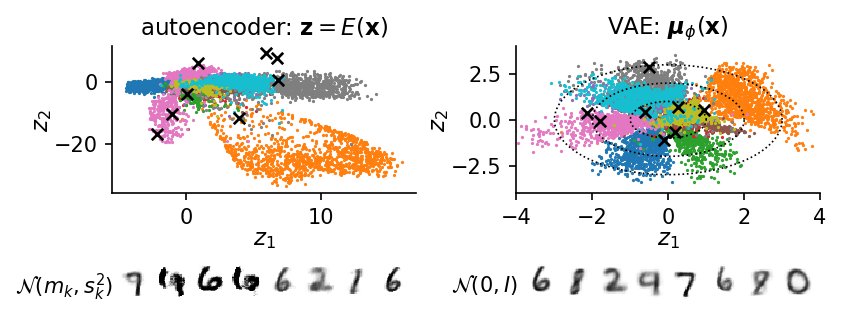

In [7]:
ae2, _ = fit("mnist_ae_d2", DenseAE(2, rngs=nnx.Rngs(0)), ae_loss, (Xtr_m,), epochs=8, seed=0, batch_size=256)
vae2, _ = fit("mnist_vae_d2", DenseVAE(784, 2, rngs=nnx.Rngs(2)), bvae_loss(1.0), (Xtr_m,), epochs=8, seed=2)
Z_ae = np.asarray(nnx.jit(lambda m, x: m.encode(to_unit(x)))(ae2, Xte_m))           # (10000, 2)
Z_vae = in_chunks(lambda x: enc_fn(vae2, to_unit(x))[0], Xte_m)                       # (10000, 2) means
k1, k2 = jax.random.split(jax.random.key(10))
z_ae = Z_ae.mean(0) + Z_ae.std(0) * np.asarray(jax.random.normal(k1, (8, 2)))
z_vae = np.asarray(jax.random.normal(k2, (8, 2)))
x_ae = np.asarray(nnx.jit(lambda m, z: m.decode(z))(ae2, jnp.asarray(z_ae, jnp.float32)))
x_vae = np.asarray(dec_fn(vae2, jnp.asarray(z_vae)))
nums["ae2_code_std"], nums["vae2_mu_std"] = Z_ae.std(0).tolist(), Z_vae.std(0).tolist()
print("standard deviation of the codes: autoencoder", np.round(Z_ae.std(0), 2), "| VAE means", np.round(Z_vae.std(0), 2))

cmap10 = plt.get_cmap("tab10")
with plt.rc_context(SLIDE):
    fig = plt.figure(figsize=(FULL, 2.0), layout="constrained")
    gs = fig.add_gridspec(2, 2, height_ratios=[4, 1])
    t = np.linspace(0, 2 * np.pi, 200)
    for col, (Z, zr, title, imgs, lab) in enumerate([(Z_ae, z_ae, "autoencoder: $\\mathbf{z}=E(\\mathbf{x})$", x_ae, "$\\mathcal{N}(m_k,s_k^2)$"),
                                                     (Z_vae, z_vae, "VAE: $\\boldsymbol{\\mu}_\\phi(\\mathbf{x})$", x_vae, "$\\mathcal{N}(0,I)$")]):
        ax = fig.add_subplot(gs[0, col])
        for dgt in range(10):
            m = yte == dgt
            ax.scatter(Z[m, 0], Z[m, 1], s=0.3, color=cmap10(dgt), rasterized=True)
        if col == 1:
            for r in (1, 2, 3): ax.plot(r * np.cos(t), r * np.sin(t), "k:", lw=0.8)
            ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
        ax.scatter(zr[:, 0], zr[:, 1], marker="x", s=30, color="k", lw=1.3)
        ax.set_title(title); ax.set_xlabel("$z_1$", labelpad=0); ax.set_ylabel("$z_2$", labelpad=0)
        show_rows([imgs], [lab], fig.add_subplot(gs[1, col]))
    save(fig, "ae_vs_vae"); plt.show()

The autoencoder chooses its own scale: its codes have standard deviations 3.84 and 7.61 along the two axes, the 1s (orange) form a long arm far from the other digits, and there are empty regions between the islands of codes. Several crosses drawn from the fitted Gaussian land in such regions, and two of the eight decoded images (the second and the fourth) are smeared blobs rather than digits. The VAE means have standard deviations 1.06 and 1.09 and fill the disc in which $\mathcal N(0,I)$ puts its probability, and all eight images decoded from $\mathcal N(0,I)$ are digits, somewhat blurred, as VAE images are (Section 1.4). In two dimensions the autoencoder is still lucky in about half of its draws; Lab 024 showed that in 16 dimensions almost no random latent vector of an autoencoder decodes to a digit.

### 1.4 Sampling a trained VAE

It is worth being precise about what "sampling a VAE" means, because a trained model can be used in two different ways, and the images shown in the rest of the notebook come from both. We now use a VAE with $d=10$ latent coordinates, trained for 8 epochs; it is the $\beta=1$ member of the family studied in Section 3.

*Reconstruction* starts from a data image: $\mathbf x\to\mathbf z\sim q_\phi(\mathbf z|\mathbf x)\to p_\theta(\mathbf x|\mathbf z)$. It tests how much of $\mathbf x$ survives the compression into $\mathbf z$, but it does not generate anything new.

*Generation* starts from the prior: $\mathbf z\sim p(\mathbf z)=\mathcal N(0,I)\to\mathbf x\sim p_\theta(\mathbf x|\mathbf z)$. This two-step procedure, first the latent variable, then the observed one given the latent, is called **ancestral sampling**, and it draws exactly from the model distribution
$$p_\theta(\mathbf x)=\int p(\mathbf z)\,p_\theta(\mathbf x|\mathbf z)\,d\mathbf z ,$$
the distribution the VAE was trained to fit to the data. Each $\mathbf z$ is a recipe for an image, and the decoder turns it into pixel probabilities.

A second distinction concerns the last step. The decoder output is a probability for every pixel, $\hat x_j=\sigma(G_\theta(\mathbf z))_j$, and a *sample* of $p_\theta(\mathbf x|\mathbf z)$ sets each pixel to 1 with probability $\hat x_j$, independently of all other pixels. What is usually shown, also in Lab 024 and in the rest of this notebook, is not this sample but the *mean* $\hat{\mathbf x}=\mathbb E[\mathbf x|\mathbf z]$, the image of the probabilities. The mean is smooth but blurry: where the decoder is unsure whether a stroke passes, it shows grey. The sample is sharp but noisy: the uncertainty becomes isolated wrong pixels, because the pixels are drawn independently and nothing correlates neighbouring pixels once $\mathbf z$ is fixed. The figure shows both, for reconstructions and for generation.

mnist_beta1: loaded from checkpoints/mnist_beta1.npz (trained for 8 epochs in 19 s)


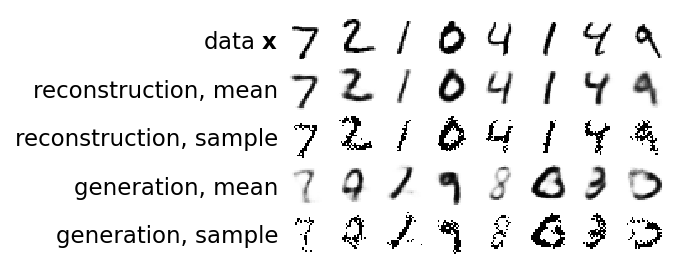

In [8]:
vae10, _ = fit("mnist_beta1", DenseVAE(784, D_LATENT, rngs=nnx.Rngs(1)), bvae_loss(1.0), (Xtr_m,), epochs=8, seed=1)
x8 = to_unit(Xte_m[:8])
mu8, lv8 = enc_fn(vae10, x8)
rec_mean = np.asarray(dec_fn(vae10, reparametrise(mu8, lv8, jax.random.key(3))))          # x -> z ~ q(z|x) -> mean
z_prior = jax.random.normal(jax.random.key(4), (8, D_LATENT))
gen_mean = np.asarray(dec_fn(vae10, z_prior))                                              # z ~ N(0, I) -> mean
bern = lambda p, key: np.asarray(jax.random.bernoulli(key, p)).astype(float)               # one sample of p(x|z)
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(FULL, 1.7), layout="constrained")
    show_rows([np.asarray(x8), rec_mean, bern(rec_mean, jax.random.key(5)), gen_mean, bern(gen_mean, jax.random.key(6))],
              ["data $\\mathbf{x}$", "reconstruction, mean", "reconstruction, sample", "generation, mean", "generation, sample"], ax,
              fontsize=11)
    save(fig, "sampling"); plt.show()

The reconstructions keep the identity and the style of each test digit, slightly blurred. The generated means are new digits, not copies of the data, of varying quality: some are clean (the 9, the 6, the 3), others lie between two digits, like the faint first one, between a 7 and a 1. The Bernoulli samples show what the decoder believes pixel by pixel: the strokes are there, but scattered black pixels appear wherever the mean is grey. This is why figures of VAEs, ours included, show the means.

### 1.5 Meaning of a single coordinate

Now that the latent vectors follow a known, well-filled distribution, we can explore the latent space systematically. A **latent traversal** is also a kind of sampling: we keep all coordinates of one code fixed and move a single coordinate $z_k$ along its axis, here from $-3$ to $3$ (three prior standard deviations), decoding at each step. Each row of the figure is one coordinate, for the five coordinates that carry the most information (the largest KL term, Section 3.4), all starting from the code $\boldsymbol\mu_\phi(\mathbf x)$ of the same test digit.

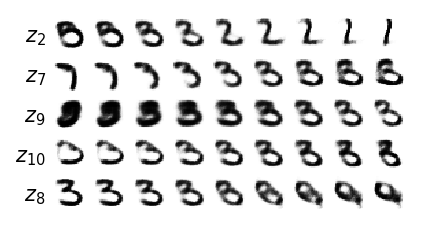

In [9]:
mu_te10, lv_te10 = in_chunks(lambda x: enc_fn(vae10, to_unit(x)), Xte_m)
kl_dims10 = np.asarray(kl_per_dim(mu_te10, lv_te10)).mean(0)
top5 = list(np.argsort(kl_dims10)[::-1][:5])
i_seed = int(np.flatnonzero(yte == 3)[0])
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(HALF, 1.75), layout="constrained")
    show_rows(traversal_rows(vae10, mu_te10[i_seed], top5), [f"$z_{{{k + 1}}}$" for k in top5], ax)
    save(fig, "traversal_beta1"); plt.show()

Every row changes the image continuously, but most rows change several things at once. $z_2$ turns the 3 first into a 2 and then into a 1 while the slant changes, $z_7$ passes from a 7 through the 3 to an 8, and $z_8$ closes the 3 into a loop like a 9. Only $z_9$ looks like a single property, the thickness of the stroke.

A traversal shows what the decoder does along one axis *around one particular code*; it does not show that the axis means the same thing everywhere, nor that the feature it changes is not also changed by other axes. Still, the picture is clear enough to state the goal of the rest of the notebook.

### 1.6 Disentangled representations

Imagine the process that produced a data set. To draw a sprite in dSprites, the generator picks a shape (square, ellipse, heart), a scale, an orientation and a position $(x,y)$, and renders the image. These five numbers are the **generative factors** of the image: they are few, they are independent of each other (every combination occurs), and together they determine the image completely. For a face the factors are not listed anywhere, but we can name candidates: the angle of the head (looking left or right), glasses or none, smile, hair colour and style, lighting, background. For a spin configuration in thermal equilibrium, the macroscopic quantities that physicists use to describe a phase, such as the magnetisation $m$ or the stripe order parameters, play this role, and the microscopic details are noise.

A latent representation $\mathbf z=(z_1,\dots,z_d)$ is called **disentangled** if each generative factor is carried by its own latent coordinate: changing one factor in the image changes one coordinate $z_k$ and leaves the others unchanged, and moving one $z_k$ in the decoder changes one property of the output. The traversals above are not of this kind. A disentangled code is worth having for three reasons. It is *controllable*: to put glasses on a face we move one coordinate. It is *interpretable*: the meaning of each coordinate can be read off by moving it, or by correlating it with known quantities. And it is *informative about the data*: if a network trained on spin snapshots devotes one coordinate to the magnetisation, it has rediscovered the order parameter without being told that it exists, which is the question of Section 6.

The cVAE of Labs 024 and 025 solves an easier problem: the factor of interest, the digit or the temperature, is given as a label, and the training separates it from the rest by construction. Here no labels are used during training; labels and known factors serve only to *evaluate* what the network has found. The next section shows how a single number in the loss pushes the VAE in this direction.

<hr/>
## 2. The β-weighted loss

### 2.1 From the evidence lower bound to the β-VAE objective

We recall the VAE of Lab 024. A prior $p(\mathbf z)=\mathcal N(0,I_d)$ over latent vectors $\mathbf z\in\mathbb R^d$, a decoder $p_\theta(\mathbf x|\mathbf z)$ (independent Bernoulli pixels with probabilities $\hat{\mathbf x}=\sigma(G_\theta(\mathbf z))$), and an encoder $q_\phi(\mathbf z|\mathbf x)=\mathcal N\big(\boldsymbol\mu_\phi(\mathbf x),\mathrm{diag}\,\boldsymbol\sigma_\phi^2(\mathbf x)\big)$. The quantity we would like to maximise is the log-likelihood $\log p_\theta(\mathbf x)=\log\int p_\theta(\mathbf x|\mathbf z)p(\mathbf z)\,d\mathbf z$, called the *evidence*; the integral over $\mathbf z$ cannot be computed. Lab 024 derived the **evidence lower bound (ELBO)**, a computable lower bound on the evidence,
$$\begin{aligned}\log p_\theta(\mathbf x)\;\ge\;\mathrm{ELBO}(\mathbf x)=\;&\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[\log p_\theta(\mathbf x|\mathbf z)\big]\\&-\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z)\big),\end{aligned}$$
where $\mathrm{KL}(q\|p)=\mathbb E_q[\log q-\log p]\ge0$ is the Kullback–Leibler divergence. The VAE minimises $-\mathrm{ELBO}$ averaged over the data.

The **β-VAE** [I. Higgins *et al.*, *β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework*, ICLR 2017, [OpenReview](https://openreview.net/forum?id=Sy2fzU9gl)] changes one number: the KL term is multiplied by $\beta\ge0$,
$$\begin{aligned}\mathcal L_\beta(\mathbf x)=\;&\underbrace{\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[-\log p_\theta(\mathbf x|\mathbf z)\big]}_{\text{reconstruction error}}\\&+\;\beta\,\underbrace{\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z)\big)}_{\text{distance of the code from the prior}}\end{aligned}$$
For $\beta=1$ this is the VAE loss, $-\mathrm{ELBO}$. The first term is the binary cross-entropy (BCE) of Lab 024: it is small when latent vectors drawn from the encoder's cloud $q_\phi(\mathbf z|\mathbf x)$ decode back to $\mathbf x$. The second term is the closed-form expression $\tfrac12\sum_k(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1)$; it is small when every cloud looks like the prior: centred at the origin, with unit width in every direction.

The two terms pull in opposite directions. To reconstruct $\mathbf x$ well, the encoder should place a narrow cloud at a position specific to $\mathbf x$; the KL term charges for every such deviation from $\mathcal N(0,1)$, coordinate by coordinate. Increasing $\beta$ makes information in the code more expensive:

For $\beta>1$ the encoder keeps only what pays most for the reconstruction. Coordinates that carry little are switched off ($q(z_k|\mathbf x)=\mathcal N(0,1)$ for every image, so $z_k$ carries nothing), the remaining clouds are wider, and the reconstructions become blurrier. Since the prior $\mathcal N(0,I)$ is a product of independent coordinates, the pressure towards the prior is also a pressure towards *independent* coordinates; we make this precise in Section 2.4. This is the regime in which Higgins *et al.* observed disentangling. For $\beta<1$ information is cheap: reconstructions are sharper, more coordinates are used, but the code drifts away from the prior and samples drawn from $\mathcal N(0,I)$ get worse. For $\beta\to0$ we are back to an autoencoder.

Higgins *et al.* motivate $\beta$ as a Lagrange multiplier. Suppose we want the best reconstruction under a budget $\varepsilon$ for the information in the code, $\max_{\theta,\phi}\mathbb E_q[\log p_\theta(\mathbf x|\mathbf z)]$ subject to $\mathrm{KL}(q_\phi\|p)<\varepsilon$. The Lagrangian of this problem is $\mathbb E_q[\log p_\theta(\mathbf x|\mathbf z)]-\beta\big(\mathrm{KL}(q_\phi\|p)-\varepsilon\big)$, and since $\beta\varepsilon$ does not depend on the parameters, maximising it is the same as minimising $\mathcal L_\beta$. A smaller budget $\varepsilon$ corresponds to a larger multiplier $\beta$.

A note on units, needed to compare $\beta$ values between data sets. Both terms are sums: the reconstruction error over the $D$ pixels of an image, the KL term over the $d$ latent coordinates. The same $\beta$ therefore means a different balance for $28\times28$ digits ($D=784$) and for $32\times32$ colour faces ($D=3072$). Higgins *et al.* quote a normalised value $\beta d/D$; we quote the raw $\beta$ and the sizes.

### 2.2 Rate and distortion

Averaged over the data distribution $p_{\rm data}(\mathbf x)$, the two terms of $\mathcal L_\beta$ have names borrowed from information theory [A. A. Alemi *et al.*, *Fixing a Broken ELBO*, ICML 2018, [PMLR 80, 159](https://proceedings.mlr.press/v80/alemi18a.html)]:
$$\begin{aligned}D&=\mathbb E_{p_{\rm data}(\mathbf x)}\,\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[-\log p_\theta(\mathbf x|\mathbf z)\big],\\R&=\mathbb E_{p_{\rm data}(\mathbf x)}\,\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z)\big),\end{aligned}$$
the **distortion** $D$ (here: the reconstruction BCE in nats per image) and the **rate** $R$ (the KL term in nats per image). The rate measures how much the code of an image differs from the prior, which is the price of sending the code through a channel whose receiver only knows the prior; Section 2.4 shows that it is an upper bound on the mutual information between images and codes. The loss is now a single line,
$$\mathcal L_\beta=D+\beta R,\qquad -\mathrm{ELBO}=D+R .$$

Every trained model is a point in the $(R,D)$ plane, and the points that a given architecture can reach lie above a curve $D^*(R)$, the smallest distortion achievable at rate $R$. This curve decreases (more information, better reconstructions) and, for the purpose of the argument, we take it convex. Minimising $D+\beta R$ over the reachable points selects the point of the curve where
$$\frac{d}{dR}\big(D^*(R)+\beta R\big)=0\quad\Longrightarrow\quad\frac{dD^*}{dR}=-\beta :$$
**$\beta$ is minus the slope of the rate–distortion curve at the selected point.** A large $\beta$ selects the flat, low-rate end of the curve; a small $\beta$ the steep, high-rate end. Alemi *et al.* emphasise a consequence: the ELBO alone, $D+R$, does not tell how a model splits its loss between rate and distortion, and models with very different latent codes can have almost the same ELBO. Section 3 traces this curve on MNIST.

### 2.3 $\beta$ as a temperature in a free energy

Lab 024 showed that $-\mathrm{ELBO}$ is a variational free energy. The same reading tells what $\beta$ does. Fix one image $\mathbf x$ and write the KL term as $\mathbb E_q[\log q]-\mathbb E_q[\log p(\mathbf z)]$. With the entropy $S[q]=-\mathbb E_q[\log q]$ the β-loss becomes
$$\begin{aligned}\mathcal L_\beta[q]&=\mathbb E_q\big[\underbrace{-\log p_\theta(\mathbf x|\mathbf z)-\beta\log p(\mathbf z)}_{E_\beta(\mathbf z)}\big]-\beta\,S[q]\\&=\langle E_\beta\rangle_q-\beta\,S[q].\end{aligned}$$
This has exactly the form $F[q]=\langle E\rangle_q-T\,S[q]$ of a variational free energy, with energy $E_\beta$ and **temperature $T=\beta$**. Its minimum over all distributions $q$ is the Boltzmann distribution of $E_\beta$ at temperature $\beta$,
$$\begin{aligned}q^*_\beta(\mathbf z)&=\frac{e^{-E_\beta(\mathbf z)/\beta}}{Z_\beta}=\frac{p_\theta(\mathbf x|\mathbf z)^{1/\beta}\,p(\mathbf z)}{Z_\beta},\\Z_\beta&=\int p_\theta(\mathbf x|\mathbf z)^{1/\beta}p(\mathbf z)\,d\mathbf z ,\end{aligned}$$
which follows from the Gibbs–Bogoliubov argument of Lab 024: $\mathcal L_\beta[q]=-\beta\log Z_\beta+\beta\,\mathrm{KL}(q\,\|\,q^*_\beta)$. For $\beta=1$ this is the posterior $p_\theta(\mathbf z|\mathbf x)$. For $\beta>1$, a high temperature, the likelihood enters with the power $1/\beta<1$, so the "tempered posterior" is broader and closer to the prior: the code forgets details of $\mathbf x$. For $\beta<1$, a low temperature, it concentrates around the latent vectors that explain $\mathbf x$ best. The entropy of the code is what $\beta$ weights, as the temperature weights the entropy in thermodynamics.

We check the formula on a model in which everything is Gaussian and can be computed in closed form: one latent variable $z\sim\mathcal N(0,1)$ and one observation $x\,|\,z\sim\mathcal N(az,s^2)$. Then $p(x|z)^{1/\beta}p(z)$ is a Gaussian in $z$ with precision $1+a^2/(\beta s^2)$ and mean $\frac{a x/(\beta s^2)}{1+a^2/(\beta s^2)}$. The next cell minimises $\mathcal L_\beta[q]$ over Gaussian $q=\mathcal N(m,v)$ by gradient descent, with both terms written as closed-form expressions in $m$ and $v$, and compares the minimiser with the tempered posterior for several $\beta$.

In [10]:
a_toy, s_toy, x_toy = 2.0, 0.5, 1.3          # x | z ~ N(a z, s^2), z ~ N(0, 1), one observed x

def loss_beta_gaussian(params, beta):
    '''L_beta[q] for q = N(m, v): E_q[-log p(x|z)] + beta * KL(q || N(0, 1)), both in closed form.'''
    m, log_v = params
    v = jnp.exp(log_v)
    rec = 0.5 * jnp.log(2 * jnp.pi * s_toy**2) + ((x_toy - a_toy * m) ** 2 + a_toy**2 * v) / (2 * s_toy**2)
    kl = 0.5 * (m**2 + v - log_v - 1)
    return rec + beta * kl

def minimise(beta, steps=3000, lr=0.05):
    '''Adam on (m, log v), all steps in one compiled lax.scan.'''
    tx = optax.adam(lr)
    def step(carry, _):
        params, st = carry
        up, st = tx.update(jax.grad(loss_beta_gaussian)(params, beta), st)
        return (optax.apply_updates(params, up), st), None
    params = (jnp.array(0.0), jnp.array(0.0))
    (params, _), _ = jax.jit(lambda c: jax.lax.scan(step, c, None, length=steps))((params, tx.init(params)))
    return float(params[0]), float(jnp.exp(params[1]))

print(" beta   mean: gradient descent / tempered posterior    variance: gradient descent / tempered posterior")
for beta in [0.25, 1.0, 4.0, 16.0]:
    prec = 1 + a_toy**2 / (beta * s_toy**2)
    m_exact, v_exact = (a_toy * x_toy / (beta * s_toy**2)) / prec, 1 / prec
    m_gd, v_gd = minimise(beta)
    print(f"{beta:5.2f}   {m_gd:8.4f} / {m_exact:8.4f}                       {v_gd:8.4f} / {v_exact:8.4f}")
    assert abs(m_gd - m_exact) < 1e-3 and abs(v_gd - v_exact) < 1e-3

 beta   mean: gradient descent / tempered posterior    variance: gradient descent / tempered posterior


 0.25     0.6400 /   0.6400                         0.0154 /   0.0154


 1.00     0.6118 /   0.6118                         0.0588 /   0.0588
 4.00     0.5200 /   0.5200                         0.2000 /   0.2000


16.00     0.3250 /   0.3250                         0.5000 /   0.5000


The minimiser agrees with the tempered posterior to all printed digits. As $\beta$ grows the optimal code moves towards the prior: its mean shrinks towards 0 and its variance grows towards 1, and at $\beta=16$ the code has almost forgotten the observation.

### 2.4 Decomposition of the rate

The rate $R$ is an average over images of a KL divergence between each image's cloud and the prior. Which part of it pushes the latent coordinates to be independent? To see this we look at all codes together. For a data set of $N$ images $\mathbf x_1,\dots,\mathbf x_N$, put the index $n$ of an image on equal footing with $\mathbf z$ and define two joint distributions over pairs $(n,\mathbf z)$,
$$q(n,\mathbf z)=\tfrac1N\,q(\mathbf z|\mathbf x_n),\qquad p(n,\mathbf z)=\tfrac1N\,p(\mathbf z).$$
Their marginals over $n$ are both uniform, $1/N$. The marginal of $q$ over $n$ is the **aggregate posterior**
$$q(\mathbf z)=\frac1N\sum_{n=1}^N q(\mathbf z|\mathbf x_n),$$
the distribution of codes over the whole data set: a mixture of $N$ Gaussian clouds. Its one-dimensional marginals are $q(z_j)$. The derivation needs only the definition of KL and the splitting of a logarithm.

The first step follows M. D. Hoffman and M. J. Johnson [*ELBO surgery: yet another way to carve up the variational evidence lower bound*, NIPS 2016 Workshop on Advances in Approximate Bayesian Inference, [PDF](https://web.archive.org/web/2019/http://approximateinference.org/accepted/HoffmanJohnson2016.pdf)]. The rate is
$$\begin{aligned}R&=\frac1N\sum_n\mathbb E_{q(\mathbf z|\mathbf x_n)}\Big[\log\frac{q(\mathbf z|\mathbf x_n)}{p(\mathbf z)}\Big]\\&=\mathbb E_{q(n,\mathbf z)}\Big[\log\frac{q(\mathbf z|n)}{p(\mathbf z)}\Big].\end{aligned}$$
Multiply and divide by $q(\mathbf z)$ inside the logarithm:
$$R=\mathbb E_{q(n,\mathbf z)}\Big[\log\frac{q(\mathbf z|n)}{q(\mathbf z)}\Big]+\mathbb E_{q(n,\mathbf z)}\Big[\log\frac{q(\mathbf z)}{p(\mathbf z)}\Big].$$
In the first term $q(\mathbf z|n)/q(\mathbf z)=q(n,\mathbf z)/\big(q(n)q(\mathbf z)\big)$ with $q(n)=1/N$, so this term is the **mutual information (MI)** $I_q(n;\mathbf z)$ between the index of an image and its code. The mutual information of two random variables $a$ and $b$ with joint distribution $P(a,b)$ and marginals $P(a)$, $P(b)$ is the KL divergence of the joint distribution from the product of the marginals, $I(a;b)=\mathrm{KL}\big(P(a,b)\,\|\,P(a)P(b)\big)=\mathbb E\big[\log\frac{P(a,b)}{P(a)P(b)}\big]\ge0$. It is zero if and only if $a$ and $b$ are independent, and it equals the reduction of uncertainty about $a$ obtained by learning $b$, $I(a;b)=H(a)-H(a|b)$, where $H(a)=-\mathbb E\log P(a)$ is the entropy (both in nats). In the second term the integrand does not depend on $n$, the average over $n$ leaves $\mathbb E_{q(\mathbf z)}$, and the term is $\mathrm{KL}\big(q(\mathbf z)\,\|\,p(\mathbf z)\big)$:
$$R=I_q(n;\mathbf z)+\mathrm{KL}\big(q(\mathbf z)\,\|\,p(\mathbf z)\big).$$

The second step follows R. T. Q. Chen, X. Li, R. Grosse and D. Duvenaud [*Isolating Sources of Disentanglement in Variational Autoencoders*, NeurIPS 2018, [arXiv:1802.04942](https://arxiv.org/abs/1802.04942)]. The prior factorises, $p(\mathbf z)=\prod_jp(z_j)$. Multiply and divide by $\prod_jq(z_j)$ inside the second logarithm:
$$\begin{aligned}\mathrm{KL}\big(q(\mathbf z)\,\|\,p(\mathbf z)\big)=\;&\mathbb E_{q(\mathbf z)}\Big[\log\frac{q(\mathbf z)}{\prod_jq(z_j)}\Big]\\&+\mathbb E_{q(\mathbf z)}\Big[\sum_j\log\frac{q(z_j)}{p(z_j)}\Big].\end{aligned}$$
The first term is the **total correlation** $\mathrm{TC}(\mathbf z)=\mathrm{KL}\big(q(\mathbf z)\,\|\,\prod_jq(z_j)\big)$. In the second, each summand depends only on $z_j$, so its average over $q(\mathbf z)$ is an average over the marginal $q(z_j)$. Altogether,
$$\begin{aligned}R=\;&\underbrace{I_q(n;\mathbf z)}_{\text{index-code mutual information}}+\underbrace{\mathrm{KL}\Big(q(\mathbf z)\,\Big\|\,\prod_jq(z_j)\Big)}_{\text{total correlation (TC)}}\\&+\underbrace{\sum_j\mathrm{KL}\big(q(z_j)\,\|\,p(z_j)\big)}_{\text{dimension-wise KL}}\end{aligned}$$

Each term has a clear meaning. The **index-code mutual information** says how well the code identifies the image it came from. It is what the decoder needs: if the clouds of different images overlap completely, $I_q=0$ and no reconstruction is possible. It cannot exceed $\log N$, since $I_q(n;\mathbf z)=H(n)-H(n|\mathbf z)\le H(n)=\log N$. Penalising it, as $\beta>1$ does, directly harms the reconstruction.
The **total correlation** is the KL divergence between the distribution of codes and the product of its marginals, so it is zero if and only if the coordinates $z_1,\dots,z_d$ are statistically independent over the data set, and positive otherwise. For a two-dimensional Gaussian with correlation coefficient $\rho$ it equals $-\frac12\log(1-\rho^2)$ (Exercise 3). The **dimension-wise KL** says how far each coordinate's distribution is from $\mathcal N(0,1)$.

The total correlation is the term that connects to disentangling. If the factors that generate the data are independent, as in dSprites, then a code in which each coordinate carries one factor has independent coordinates, $\mathrm{TC}=0$, whereas a code in which coordinates carry mixtures of factors generally has $\mathrm{TC}>0$ (a rotation of two independent non-Gaussian coordinates makes them dependent). A loss that penalises TC therefore favours codes aligned with independent factors. The β-VAE penalises TC, but only together with the other two terms, and its penalty on $I_q$ costs reconstruction quality. The **β-TCVAE** of Chen *et al.* keeps the weight 1 on $I_q$ and on the dimension-wise KL and puts the weight $\beta$ on TC alone,
$$\mathcal L_{\beta\text{-TC}}=D+I_q(n;\mathbf z)+\beta\,\mathrm{TC}(\mathbf z)+\sum_j\mathrm{KL}\big(q(z_j)\,\|\,p(z_j)\big).$$
The FactorVAE [H. Kim, A. Mnih, *Disentangling by Factorising*, ICML 2018, [PMLR 80, 2649](https://proceedings.mlr.press/v80/kim18b.html)] penalises the same TC term, estimated with an auxiliary classifier. We train a β-TCVAE on dSprites in Section 4.

Computing these terms requires $\log q(\mathbf z)$, a mixture over all $N$ images. For a set of $M$ images we can compute it exactly, $\log q(\mathbf z)=\operatorname{logsumexp}_m\log q(\mathbf z|\mathbf x_m)-\log M$, and the same for each $q(z_j)$; this is the aggregate posterior of those $M$ images. We draw one $\mathbf z$ from every cloud, average the logarithms, and obtain Monte Carlo estimates of the three terms. Their sum is then an estimate of $R$ for these $M$ images, which we can compare with the closed-form KL of each cloud averaged over the same images. The function below implements this; Section 3 applies it to trained models. During training, the β-TCVAE uses the minibatch instead of a fixed set of images, with the "minibatch weighted sampling" estimate of Chen *et al.*, $\log q(\mathbf z_i)\approx\operatorname{logsumexp}_{j\le B}\log q(\mathbf z_i|\mathbf x_j)-\log(NB)$ for a minibatch of $B$ images.

In [11]:
@jax.jit
def _decomposition_rows(z, mu, lv):
    '''For samples z (C, d) and all clouds (mu, lv) (M, d): log q(z|x_m) summed and per coordinate.'''
    lq = log_normal(z[:, None, :], mu[None], lv[None])                     # (C, M, d)
    M = mu.shape[0]
    log_qz = jax.scipy.special.logsumexp(lq.sum(-1), axis=1) - jnp.log(M)  # (C,)   log q(z)
    log_qzj = jax.scipy.special.logsumexp(lq, axis=1) - jnp.log(M)         # (C, d) log q(z_j)
    return log_qz, log_qzj

def kl_decomposition(mu, lv, key, n_samples=4, chunk=250):
    '''Rate of M images split into index-code MI, total correlation and dimension-wise KL (nats per image).
    mu, lv: (M, d) encoder outputs. q(z) is the aggregate posterior of these M images.'''
    mu, lv = jnp.asarray(mu), jnp.asarray(lv)
    M, d = mu.shape
    acc = {"mi": 0.0, "tc": 0.0, "dimkl": np.zeros(d)}
    for s in range(n_samples):
        z = reparametrise(mu, lv, jax.random.fold_in(key, s))               # one z per cloud, (M, d)
        for i in range(0, M, chunk):
            zi = z[i:i + chunk]
            log_qz, log_qzj = _decomposition_rows(zi, mu, lv)
            log_qz_x = log_normal(zi, mu[i:i + chunk], lv[i:i + chunk]).sum(-1)   # log q(z | x_n), own cloud
            log_pzj = log_normal(zi, 0.0, 0.0)
            acc["mi"] += float((log_qz_x - log_qz).sum())
            acc["tc"] += float((log_qz - log_qzj.sum(-1)).sum())
            acc["dimkl"] += np.asarray((log_qzj - log_pzj).sum(0))
    n = M * n_samples
    out = {"mi": acc["mi"] / n, "tc": acc["tc"] / n, "dimkl_per_dim": acc["dimkl"] / n}
    out["dimkl"] = float(out["dimkl_per_dim"].sum())
    out["sum"] = out["mi"] + out["tc"] + out["dimkl"]
    out["rate_closed_form"] = float(kl_per_dim(mu, lv).sum(-1).mean())
    out["log_M"] = float(np.log(M))
    return out

# check on clouds with a known answer: M identical clouds N(0, 1) in d = 3 -> every term is 0
_o = kl_decomposition(jnp.zeros((500, 3)), jnp.zeros((500, 3)), jax.random.key(0))
print({k: np.round(v, 4) for k, v in _o.items()})
assert abs(_o["mi"]) < 1e-5 and abs(_o["tc"]) < 1e-5 and abs(_o["rate_closed_form"]) < 1e-6

{'mi': np.float64(0.0), 'tc': np.float64(0.0), 'dimkl_per_dim': array([-0., -0., -0.]), 'dimkl': np.float64(-0.0), 'sum': np.float64(0.0), 'rate_closed_form': np.float64(0.0), 'log_M': np.float64(6.2146)}


For clouds that all equal the prior, every term vanishes, as it must: the codes carry no information about the image ($I_q=0$), the aggregate is $\mathcal N(0,I)$ with independent coordinates ($\mathrm{TC}=0$), and each marginal is the prior.

### 2.5 Limits of unsupervised disentangling

Nothing in $\mathcal L_\beta$ refers to the factors we would like to find, so it is fair to ask whether minimising it can find them at all. The answer, stated precisely by F. Locatello *et al.* [*Challenging Common Assumptions in the Unsupervised Learning of Disentangled Representations*, ICML 2019, [PMLR 97, 4114](https://proceedings.mlr.press/v97/locatello19a.html)], is no, not without further assumptions. The simplest case of their argument is already in Lab 024: if $\mathbf z\sim\mathcal N(0,I)$, then for any rotation matrix $R$ also $R\mathbf z\sim\mathcal N(0,I)$. A model with decoder $G(\mathbf z)$ and a model with decoder $G(R^\top\mathbf z)$ generate exactly the same distribution of images, have the same prior and the same total correlation of the prior, yet if the coordinates of the first model are disentangled, those of the second are mixtures of factors. Locatello *et al.* show that for any factorised prior there are infinitely many such reparametrisations, so the data alone cannot prefer the disentangled one.

In practice β-VAEs do often find meaningful axes, and the reason lies in the assumptions built into the model rather than in the objective. The most important is the *diagonal* encoder covariance $\mathrm{diag}\,\boldsymbol\sigma^2$: a rotation of the latent space turns a diagonal covariance into a non-diagonal one, which the encoder cannot represent, so the model is not rotation invariant and prefers some axes. The data set, the architecture, $\beta$ and even the random seed decide which axes; in the large study of Locatello *et al.* the random seed and the hyperparameters mattered more than the choice of the model, and good disentanglement scores could not be selected without access to the true factors.

The contrast with the cVAE is now clear. A cVAE receives the factor as a label, which is supervision: the condition $\mathbf c$ is guaranteed to control the requested property, and the latent $\mathbf z$ is pushed to carry the rest. A β-VAE receives no labels; whatever factors it finds, we have to identify afterwards, by looking (traversals) or by measuring against known quantities (Sections 4 and 6). The two approaches answer different questions: the cVAE "generate this", the β-VAE "what varies in these data?".

<hr/>
## 3. The loss at work on MNIST

MNIST is familiar ground, so we can concentrate on what $\beta$ changes. We train the dense VAE of Section 1 with $d=10$ five times, with $\beta\in\{0.5,1,2,4,8\}$, and look at the rate and the distortion, at reconstructions and samples, at the distribution of the codes, at how many coordinates stay in use, at the three parts of the rate, and finally at traversals.

### 3.1 A sweep over β

Each model is trained for 8 epochs with Adam (learning rate $10^{-3}$, minibatches of 128) from the same initialisation and the same seed, so that the five models differ only in $\beta$; the $\beta=1$ model is the one of Section 1.4 and is loaded from its checkpoint. The printed numbers are per image, in nats: the loss $\mathcal L_\beta=D+\beta R$, the distortion $D$ (the BCE) and the rate $R$ (the KL term). On 8 CPU cores one model takes about 17 s. After training, $D$ and $R$ are measured on the 10 000 test images, with one sample $\mathbf z\sim q_\phi(\mathbf z|\mathbf x)$ per image for $D$ and the closed form for $R$, together with the average KL of each coordinate, $\overline{\mathrm{KL}}_k$, and the number of *active* coordinates, those with $\overline{\mathrm{KL}}_k>0.1$ nats (Section 3.4).

In [12]:
BETAS = [0.5, 1.0, 2.0, 4.0, 8.0]
EPOCHS_MNIST = 8
mnist = {}
for beta in BETAS:
    model, hist = fit(f"mnist_beta{beta:g}", DenseVAE(784, D_LATENT, rngs=nnx.Rngs(1)), bvae_loss(beta),
                      (Xtr_m,), epochs=EPOCHS_MNIST, seed=1)
    mnist[beta] = {"model": model, "hist": hist}
nums["mnist_train_seconds_per_model"] = float(np.mean([mnist[b]["hist"]["seconds"] for b in BETAS]))

for beta in BETAS:
    D, R, kl = in_chunks(lambda x: rate_distortion(mnist[beta]["model"], x, jax.random.key(0)), Xte_m)
    mnist[beta].update(D=float(D.mean()), R=float(R.mean()), kl_dims=kl.mean(0))
    mnist[beta]["active"] = int((mnist[beta]["kl_dims"] > 0.1).sum())
    print(f"beta = {beta:3g}:  test D = {mnist[beta]['D']:6.1f}  R = {mnist[beta]['R']:5.1f}  "
          f"-ELBO = D + R = {mnist[beta]['D'] + mnist[beta]['R']:6.1f} nats;  active coordinates: {mnist[beta]['active']}")
nums["mnist"] = {f"{b:g}": {"D": mnist[b]["D"], "R": mnist[b]["R"], "neg_elbo": mnist[b]["D"] + mnist[b]["R"],
                            "active": mnist[b]["active"], "kl_dims_sorted": sorted(mnist[b]["kl_dims"].tolist(), reverse=True)}
                 for b in BETAS}

mnist_beta0.5: loaded from checkpoints/mnist_beta0.5.npz (trained for 8 epochs in 17 s)
mnist_beta1: loaded from checkpoints/mnist_beta1.npz (trained for 8 epochs in 19 s)
mnist_beta2: loaded from checkpoints/mnist_beta2.npz (trained for 8 epochs in 17 s)
mnist_beta4: loaded from checkpoints/mnist_beta4.npz (trained for 8 epochs in 17 s)


mnist_beta8: loaded from checkpoints/mnist_beta8.npz (trained for 8 epochs in 17 s)


beta = 0.5:  test D =   85.2  R =  22.9  -ELBO = D + R =  108.2 nats;  active coordinates: 10


beta =   1:  test D =   88.7  R =  18.4  -ELBO = D + R =  107.1 nats;  active coordinates: 10


beta =   2:  test D =   95.9  R =  13.5  -ELBO = D + R =  109.4 nats;  active coordinates: 10
beta =   4:  test D =  111.5  R =   8.7  -ELBO = D + R =  120.2 nats;  active coordinates: 8


beta =   8:  test D =  138.5  R =   4.5  -ELBO = D + R =  143.0 nats;  active coordinates: 5


### 3.2 The rate–distortion curve

The five models are five points in the $(R,D)$ plane. Through each point we draw the line $D+\beta R=\text{const}$, the set of points with the same β-loss: according to Section 2.2 the model of a given $\beta$ should sit where such a line of slope $-\beta$ touches the curve of achievable points from below. The right panel shows the per-image $-\mathrm{ELBO}=D+R$ of each model, the quantity that a plain VAE minimises.

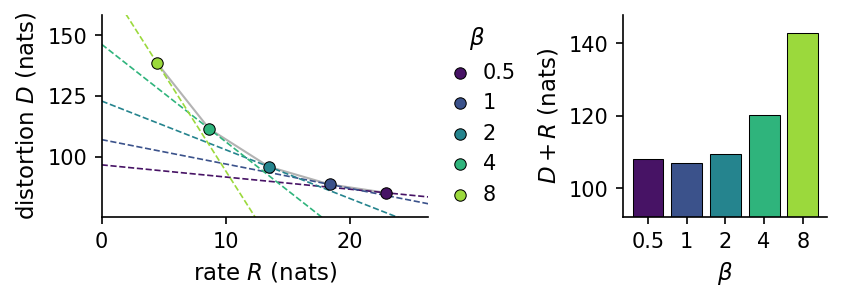

In [13]:
Rs = np.array([mnist[b]["R"] for b in BETAS]); Ds = np.array([mnist[b]["D"] for b in BETAS])
cols = plt.get_cmap("viridis")(np.linspace(0.05, 0.85, len(BETAS)))
with plt.rc_context(SLIDE):
    fig, axs = plt.subplots(1, 2, figsize=(FULL, 1.9), layout="constrained", gridspec_kw=dict(width_ratios=[1.6, 1]))
    ax = axs[0]
    ax.plot(Rs, Ds, "-", color="0.7", lw=1, zorder=1)
    rr = np.linspace(0, Rs.max() * 1.15, 50)
    for b, R_, D_, c in zip(BETAS, Rs, Ds, cols):
        ax.plot(rr, D_ - b * (rr - R_), "--", color=c, lw=0.8)          # the line D + beta R = const through the point
        ax.scatter([R_], [D_], color=c, s=30, zorder=3, edgecolor="k", lw=0.5, label=f"{b:g}")
    ax.set_ylim(Ds.min() - 10, Ds.max() + 20); ax.set_xlim(0, Rs.max() * 1.15)
    ax.set_xlabel("rate $R$ (nats)"); ax.set_ylabel("distortion $D$ (nats)")
    ax.legend(title="$\\beta$", loc="upper left", bbox_to_anchor=(1.0, 1.0), handletextpad=0.1, borderaxespad=0.1)
    axs[1].bar(range(len(BETAS)), Ds + Rs, color=cols, edgecolor="k", lw=0.5)
    axs[1].set_xticks(range(len(BETAS))); axs[1].set_xticklabels([f"{b:g}" for b in BETAS])
    axs[1].set_xlabel("$\\beta$"); axs[1].set_ylabel("$D + R$ (nats)")
    axs[1].set_ylim((Ds + Rs).min() - 15, (Ds + Rs).max() + 5)
    save(fig, "mnist_rd"); plt.show()

Increasing $\beta$ from 0.5 to 8 lowers the rate from 22.9 to 4.5 nats and raises the distortion from 85.2 to 138.5 nats: the five models lie on a decreasing, convex curve, and each dashed line passes close to the curve near its own model, as the slope argument of Section 2.2 predicts. The ELBO is best for $\beta=1$, with $-\mathrm{ELBO}=107.1$ nats, as it must be, since $\beta=1$ is the model trained on the ELBO itself. Yet the models with $\beta=0.5$ and $\beta=2$ are within 1.1 and 2.3 nats of it, although their codes carry 4.5 nats more and 4.9 nats less: the ELBO alone barely distinguishes models whose latent codes differ substantially, which is the point made by Alemi *et al.*

### 3.3 How β changes reconstructions, samples and the distribution of codes

The rate is the amount of information about the image that survives in the code, so a lower rate must show up in the pictures, both in reconstructions and in generated samples. In the next figure the left block shows eight test digits (top row) and their reconstructions $\sigma(G_\theta(\boldsymbol\mu_\phi(\mathbf x)))$ by each model; the right block shows, for each model, the decoder means of eight samples decoded from the *same* eight random vectors $\mathbf z\sim\mathcal N(0,I)$.

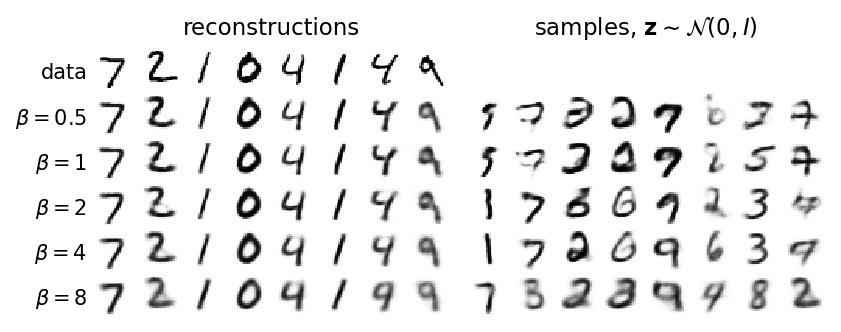

In [14]:
x8 = to_unit(Xte_m[:8])
z8 = jax.random.normal(jax.random.key(5), (8, D_LATENT))
rec_rows = [np.asarray(x8)] + [np.asarray(dec_fn(mnist[b]["model"], enc_fn(mnist[b]["model"], x8)[0])) for b in BETAS]
smp_rows = [np.zeros((8, 784))] + [np.asarray(dec_fn(mnist[b]["model"], z8)) for b in BETAS]
with plt.rc_context(SLIDE):
    fig, axs = plt.subplots(1, 2, figsize=(FULL, 2.1), layout="constrained")
    show_rows(rec_rows, ["data"] + [f"$\\beta={b:g}$" for b in BETAS], axs[0]); axs[0].set_title("reconstructions")
    show_rows(smp_rows, [""] * 6, axs[1]); axs[1].set_title("samples, $\\mathbf{z}\\sim\\mathcal{N}(0,I)$")
    save(fig, "mnist_recon_samples"); plt.show()

The reconstructions lose detail as $\beta$ grows: for $\beta=8$ the 4 of the seventh column is reconstructed as a 9 and the 2 becomes a thick, blurred shape. The samples change in two ways. They become blurrier, because the decoder of a low-rate model has to produce an average of all images whose codes overlap. And they change identity: the same $\mathbf z$ decodes to different digits for different $\beta$, because each model has organised its latent space differently. Samples from $\beta=0.5$ and $\beta=1$ include malformed or faint shapes (third and sixth columns); with $\beta=2$ and $\beta=4$ most samples are clean digits, and with $\beta=8$ they are blurred again.

Samples are good when the decoder has learned to produce digits wherever the prior puts its probability, that is, when the codes of the training images fill $\mathcal N(0,I)$. The distribution of codes over the whole data set is the *aggregate posterior* $q(\mathbf z)=\frac1N\sum_nq_\phi(\mathbf z|\mathbf x_n)$ of Section 2.4. Lab 024 described the latent space as a map: an autoencoder sticks one pin per image into the map and leaves an empty sea between the pins, a VAE replaces each pin by a cloud and the KL term pulls all clouds onto one standard disc, $\mathcal N(0,I)$, so that a dart thrown at the disc (a sample of the prior) lands on land. The β-VAE version of the picture is that a larger $\beta$ pushes the clouds harder onto the disc: each cloud becomes wider and closer to the prior, and only the directions that carry the most information keep clouds that are narrow and well separated. To see this, we plot the encoder means $\boldsymbol\mu_\phi(\mathbf x)$ of the test digits in the plane of the two most active coordinates, coloured by digit, for $\beta=1$, $4$ and $8$, together with the circles of radius 1, 2 and 3 of the prior; for 40 of the digits we also draw the cloud itself as an ellipse with half-axes $\sigma_k$, i.e. the region $\boldsymbol\mu\pm\boldsymbol\sigma$ of $q_\phi(\mathbf z|\mathbf x)$ in that plane.

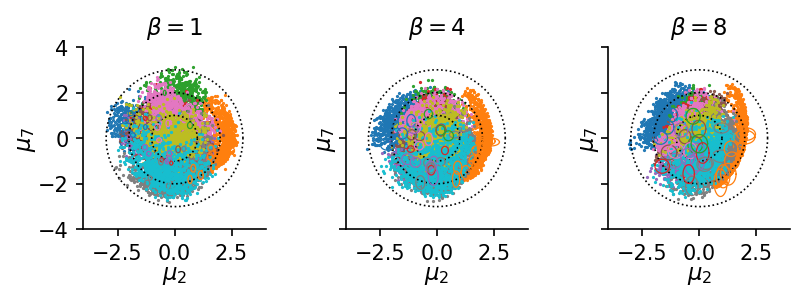

standard deviation of the two plotted mean coordinates: {'1': [1.05, 1.09], '4': [0.98, 1.01], '8': [0.93, 0.93]}


In [15]:
with plt.rc_context(SLIDE):
    fig, axs = plt.subplots(1, 3, figsize=(FULL, 1.9), layout="constrained", sharey=True)
    t = np.linspace(0, 2 * np.pi, 200)
    for ax, b in zip(axs, [1.0, 4.0, 8.0]):
        mu = in_chunks(lambda x: enc_fn(mnist[b]["model"], to_unit(x))[0], Xte_m)
        k1_, k2_ = np.argsort(mnist[b]["kl_dims"])[::-1][:2]
        for dgt in range(10):
            m = yte == dgt
            ax.scatter(mu[m, k1_], mu[m, k2_], s=0.3, color=cmap10(dgt), rasterized=True)
        for r in (1, 2, 3): ax.plot(r * np.cos(t), r * np.sin(t), "k:", lw=0.8)
        lv = in_chunks(lambda x: enc_fn(mnist[b]["model"], to_unit(x))[1], Xte_m[:40])
        for i in range(40):                                              # clouds: ellipses mu +- sigma in this plane
            sx, sy = np.exp(0.5 * lv[i, k1_]), np.exp(0.5 * lv[i, k2_])
            ax.plot(mu[i, k1_] + sx * np.cos(t), mu[i, k2_] + sy * np.sin(t), color=cmap10(yte[i]), lw=0.6)
        ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal")
        ax.set_title(f"$\\beta={b:g}$"); ax.set_xlabel(f"$\\mu_{{{k1_ + 1}}}$", labelpad=0)
        ax.set_ylabel(f"$\\mu_{{{k2_ + 1}}}$", labelpad=0)
        nums.setdefault("mnist_mu_std_top2", {})[f"{b:g}"] = mu[:, [k1_, k2_]].std(0).tolist()
    save(fig, "mnist_aggregate"); plt.show()
print("standard deviation of the two plotted mean coordinates:", {k: np.round(v, 2).tolist() for k, v in nums["mnist_mu_std_top2"].items()})

For $\beta=1$ the clouds are tiny compared with the disc: each image occupies a small, well-separated region, and the codes of different digits fill the disc like a mosaic. For $\beta=8$ the clouds are much wider and overlap, the means are squeezed towards the centre (standard deviation 0.93 in both plotted coordinates, against 1.05 and 1.09 for $\beta=1$), and the details that distinguished nearby images are lost, which is the blur of the previous figure. In the map picture, a larger $\beta$ pushes the clouds harder onto the disc.

### 3.4 Latent coordinates switching off

The rate is a sum over latent coordinates, $R=\sum_k\overline{\mathrm{KL}}_k$, with
$$\overline{\mathrm{KL}}_k=\Big\langle\tfrac12\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big)\Big\rangle_{\mathbf x}$$
averaged over the test images, so we can see *where* the information sits. As in Lab 024, a coordinate with $\overline{\mathrm{KL}}_k<0.1$ nats is called inactive: its cloud is the prior for every image, so it carries no information and the decoder ignores it. For each $\beta$ the figure shows the ten values of $\overline{\mathrm{KL}}_k$ sorted in decreasing order, on a logarithmic scale.

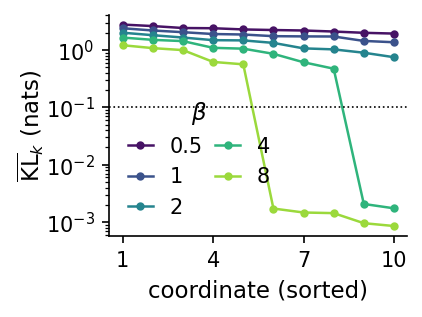

In [16]:
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(HALF, 2.0), layout="constrained")
    for b, c in zip(BETAS, cols):
        ax.plot(np.arange(1, D_LATENT + 1), np.sort(mnist[b]["kl_dims"])[::-1], "o-", color=c, ms=3, lw=1.2, label=f"{b:g}")
    ax.axhline(0.1, color="k", ls=":", lw=0.8)
    ax.set_yscale("log"); ax.set_xlabel("coordinate (sorted)"); ax.set_ylabel("$\\overline{\\mathrm{KL}}_k$ (nats)", labelpad=0)
    ax.set_xticks([1, 4, 7, 10]); ax.legend(title="$\\beta$", ncol=2, loc="lower left", columnspacing=0.6, handlelength=1.2)
    save(fig, "mnist_kl_dims"); plt.show()

For $\beta\le2$ all ten coordinates are active, with $\overline{\mathrm{KL}}_k$ decreasing smoothly. For $\beta=4$ two coordinates switch off and for $\beta=8$ five, with a drop of more than two orders of magnitude, to about $10^{-3}$ nats: these coordinates are exactly the prior for every image. The β-weight does not shrink all coordinates equally; it removes the least useful ones and keeps a few informative ones, which is the first ingredient of a disentangled code.

### 3.5 The three parts of the rate

Section 2.4 split the rate into the index-code mutual information $I_q(n;\mathbf z)$, the total correlation and the dimension-wise KL. We now estimate the three parts for each model on $M=2000$ test images, with the aggregate posterior of these images and four samples of $\mathbf z$ per image. The sum of the three Monte Carlo estimates must reproduce the closed-form rate of the same images, which tests the implementation, and the mutual information cannot exceed $\log M=7.60$ nats.

beta = 0.5:  I =  7.59  TC = 14.50  dim-KL =  0.38  sum =  22.48   closed-form rate =  22.47   (log M = 7.60)


beta =   1:  I =  7.55  TC = 10.22  dim-KL =  0.26  sum =  18.03   closed-form rate =  18.02   (log M = 7.60)


beta =   2:  I =  7.38  TC =  5.66  dim-KL =  0.17  sum =  13.20   closed-form rate =  13.19   (log M = 7.60)


beta =   4:  I =  6.53  TC =  1.69  dim-KL =  0.19  sum =   8.40   closed-form rate =   8.39   (log M = 7.60)


beta =   8:  I =  3.86  TC =  0.26  dim-KL =  0.11  sum =   4.23   closed-form rate =   4.22   (log M = 7.60)


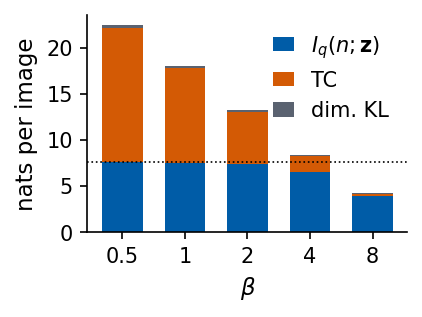

In [17]:
M_DEC = 2000
decomp = {}
for b in BETAS:
    mu, lv = enc_fn(mnist[b]["model"], to_unit(Xte_m[:M_DEC]))
    decomp[b] = kl_decomposition(mu, lv, jax.random.key(7))
    o = decomp[b]
    print(f"beta = {b:3g}:  I = {o['mi']:5.2f}  TC = {o['tc']:5.2f}  dim-KL = {o['dimkl']:5.2f}  "
          f"sum = {o['sum']:6.2f}   closed-form rate = {o['rate_closed_form']:6.2f}   (log M = {o['log_M']:.2f})")
    assert abs(o["sum"] - o["rate_closed_form"]) < 0.02 * o["rate_closed_form"] + 0.05
    assert o["mi"] <= o["log_M"] + 1e-6
nums["mnist_decomposition"] = {f"{b:g}": {k: decomp[b][k] for k in ["mi", "tc", "dimkl", "rate_closed_form"]} for b in BETAS}

with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(HALF, 2.0), layout="constrained")
    bottom = np.zeros(len(BETAS))
    for key, lab, c in [("mi", "$I_q(n;\\mathbf{z})$", UJBlue), ("tc", "TC", DSOrange), ("dimkl", "dim. KL", UJGray)]:
        v = np.array([decomp[b][key] for b in BETAS])
        ax.bar(range(len(BETAS)), v, bottom=bottom, color=c, label=lab, width=0.65); bottom += v
    ax.axhline(np.log(M_DEC), color="k", ls=":", lw=0.8)
    ax.set_xticks(range(len(BETAS))); ax.set_xticklabels([f"{b:g}" for b in BETAS]); ax.set_xlabel("$\\beta$")
    ax.set_ylabel("nats per image"); ax.legend(loc="upper right", handlelength=1.0)
    save(fig, "mnist_decomposition"); plt.show()

In all five models the three Monte Carlo estimates add up to the closed-form rate within 0.01 nats. The parts behave differently. The index-code mutual information stays close to its maximum $\log M=7.60$ for $\beta\le2$ (7.59, 7.55, 7.38 nats) and only then decreases (6.53 for $\beta=4$, 3.86 for $\beta=8$): the codes of different images overlap only when $\beta$ is large, which is when reconstructions deteriorate. The total correlation falls fastest, from 14.50 nats at $\beta=0.5$ and 10.22 at $\beta=1$ to 1.69 at $\beta=4$ and 0.26 at $\beta=8$: the coordinates of the code become nearly independent. The dimension-wise KL is small throughout (below 0.4 nats), so each coordinate on its own is close to $\mathcal N(0,1)$ in every model; what distinguishes the models is the dependence between coordinates.

### 3.6 Traversals of the MNIST codes

We return to the question of Section 1.5 and compare the traversals of the model with $\beta=1$ (the one shown there) with those of the model with $\beta=4$. As before, each row varies one coordinate from $-3$ to $3$ around the code of the same test digit, for the active coordinates with the largest $\overline{\mathrm{KL}}_k$ (at most five).

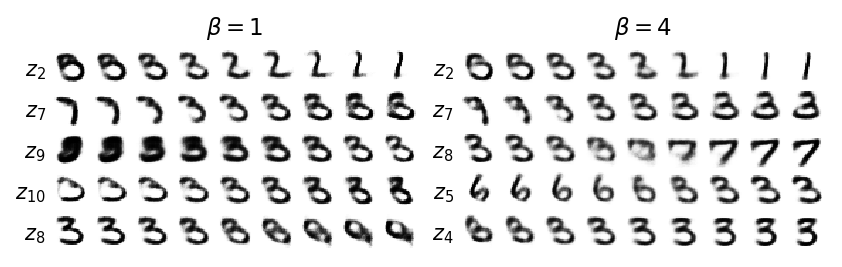

In [18]:
with plt.rc_context(SLIDE):
    fig, axs = plt.subplots(1, 2, figsize=(FULL, 1.75), layout="constrained")
    for ax, b in zip(axs, [1.0, 4.0]):
        m = mnist[b]["model"]
        dims = [k for k in np.argsort(mnist[b]["kl_dims"])[::-1][:5] if mnist[b]["kl_dims"][k] > 0.1]
        mu0 = enc_fn(m, to_unit(Xte_m[i_seed:i_seed + 1]))[0][0]
        show_rows(traversal_rows(m, mu0, dims), [f"$z_{{{k + 1}}}$" for k in dims], ax)
        ax.set_title(f"$\\beta={b:g}$")
    save(fig, "mnist_traversal"); plt.show()

Both models change the digit continuously along every axis, and both change its identity: for $\beta=4$, $z_2$ turns a 6 into a 3 and then a 1, $z_8$ turns the 3 into a 7, and $z_5$ a 6 into a 3, while $z_4$ mainly changes the width and the thickness of the stroke. The coordinates of the $\beta=4$ model are fewer and individually somewhat cleaner, but none of them is "the digit", and slant, width and thickness still appear together with identity changes.

The reason why identity does not separate is structural. The identity of a digit is a *discrete* factor with ten values, and the latent space is a *continuous* Gaussian: there is no single coordinate along which "3" turns into "8" without passing through shapes in between, so identity ends up spread over several coordinates and regions of the latent space. This is precisely the situation in which the cVAE helps: it receives the digit as a one-hot label and leaves only the continuous style to $\mathbf z$. Whether the remaining coordinates are disentangled we cannot tell on MNIST, because nobody has listed the true factors of handwriting. The next data set has them.

<hr/>
## 4. Measuring disentanglement on dSprites

### 4.1 Data with known factors

dSprites [L. Matthey, I. Higgins, D. Hassabis, A. Lerchner, *dSprites: Disentanglement testing Sprites dataset* (2017), [github.com/deepmind/dsprites-dataset](https://github.com/deepmind/dsprites-dataset)] contains $64\times64$ binary images of a single white sprite, generated from five independent factors: shape (square, ellipse, heart; 3 values), scale (6 values in $[0.5,1]$), orientation (40 values in $[0,2\pi]$), and position $x$ and $y$ (32 values each in $[0,1]$). Every combination occurs exactly once, $3\cdot6\cdot40\cdot32\cdot32=737\,280$ images, and the file stores the factor values of every image. This is what makes dSprites a test bed: we know the right answer.

To fit the CPU budget we use a random subset of $75\,000$ images for training and $10\,000$ other images for evaluation, and average each $2\times2$ block of pixels, which gives $32\times32$ images with grey values at the edges of the sprite; the positions remain resolved because a half-pixel shift changes the grey values. One remark on orientation: a square looks the same after a quarter turn and an ellipse after a half turn, so the orientation factor is ambiguous for these shapes, and no code can carry it perfectly.

dSprites: (737280, 64, 64) | values per factor: [3, 6, 40, 32, 32]


training (75000, 1024) evaluation (10000, 1024)


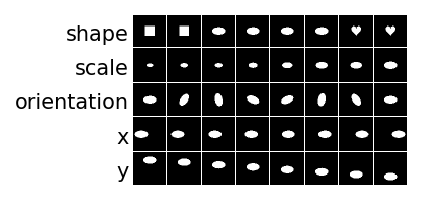

In [19]:
DS_DIR = f"{DATA}/dsprites"
DS_FILE = f"{DS_DIR}/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
if not os.path.exists(DS_FILE):
    os.makedirs(DS_DIR, exist_ok=True)
    urllib.request.urlretrieve("https://github.com/deepmind/dsprites-dataset/raw/master/" + os.path.basename(DS_FILE), DS_FILE)
ds = np.load(DS_FILE, allow_pickle=False)                     # the pickled 'metadata' entry is not needed
imgs64, fclass = ds["imgs"], ds["latents_classes"][:, 1:]    # (737280, 64, 64) uint8 in {0, 1}; (737280, 5) factor indices
FACTORS = ["shape", "scale", "orientation", "x", "y"]
print("dSprites:", imgs64.shape, "| values per factor:", [int(fclass[:, k].max()) + 1 for k in range(5)])

rng = np.random.default_rng(0)
idx = rng.permutation(len(imgs64))
idx_tr, idx_ev = np.sort(idx[:75_000]), np.sort(idx[75_000:85_000])
def to32(ims):
    '''(n, 64, 64) {0,1} -> (n, 32, 32) uint8: mean of each 2x2 block, scaled to 0..255.'''
    return (ims.reshape(-1, 32, 2, 32, 2).mean((2, 4)) * 255).round().astype(np.uint8)
Xds_tr, Xds_ev = jnp.asarray(to32(imgs64[idx_tr]).reshape(-1, 1024)), jnp.asarray(to32(imgs64[idx_ev]).reshape(-1, 1024))
F_ev = fclass[idx_ev]                                         # (10000, 5) true factors of the evaluation images
print("training", Xds_tr.shape, "evaluation", Xds_ev.shape)

# one row per factor: change that factor only, starting from the same sprite
base_cls = np.array([0, 1, 5, 0, 16, 16])                     # color, shape, scale, orientation, x, y (class indices)
strides = np.array([3 * 6 * 40 * 32 * 32, 6 * 40 * 32 * 32, 40 * 32 * 32, 32 * 32, 32, 1])   # row-major order of the file
rows = []
for k, n_val in zip(range(1, 6), [3, 6, 40, 32, 32]):
    vals = np.linspace(0, n_val - 1, 8).round().astype(int)
    cls = np.repeat(base_cls[None], 8, 0); cls[:, k] = vals
    rows.append(to32(imgs64[cls @ strides]) / 255.0)
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(HALF, 1.7), layout="constrained")
    show_rows(rows, FACTORS, ax, shape=(32, 32), cmap="gray")
    save(fig, "dsprites_data"); plt.show()
assert np.all(fclass[base_cls @ strides] == base_cls[1:])

### 4.2 The mutual information gap (MIG)

To measure how disentangled a code is, we ask, for every true factor $v_k$, how much information about it each latent coordinate carries, and whether one coordinate carries much more than all others. The **mutual information gap (MIG)** of Chen *et al.* (Section 2.4) turns this into one number. With the mutual information $I(z_j;v_k)$ between latent coordinate $j$ and factor $k$, and the entropy $H(v_k)$ of the factor,
$$\mathrm{MIG}=\frac1K\sum_{k=1}^K\frac{I(z_{j^{(k)}_1};v_k)-I(z_{j^{(k)}_2};v_k)}{H(v_k)},$$
where $j^{(k)}_1$ and $j^{(k)}_2$ are the coordinates with the largest and second-largest mutual information with $v_k$. Each term lies between 0 and 1. It is 1 when one coordinate determines the factor completely and no other coordinate knows anything about it; it is small when the information about the factor is shared by two coordinates, as for a rotated code, or when no coordinate carries it. Dividing by $H(v_k)$ makes factors with different numbers of values comparable.

Mutual information of continuous variables is hard to estimate, so we discretise. The latent coordinate is the encoder mean $\mu_j(\mathbf x)$ of each evaluation image, cut into 20 equal-width bins between its minimum and maximum; the factors are already discrete. Then
$$I(a;b)=\sum_{a,b}P(a,b)\log\frac{P(a,b)}{P(a)P(b)},\qquad H(b)=-\sum_bP(b)\log P(b),$$
with the probabilities $P$ given by the counts in the joint histogram. Two checks on codes whose answer we know come first. A code made of the five true factors themselves, padded with five coordinates of pure noise to $d=10$, should give MIG $=1$ when the bins resolve every value; with 20 bins, positions and orientations that share a bin lower it. A code made of random numbers gives MIG close to 0, and a code in which the $x$ and $y$ coordinates are rotated by 45°, $z_x=(x+y)/\sqrt2$, $z_y=(x-y)/\sqrt2$, loses the contribution of both position factors.

In [20]:
def discretise(Z, bins=20):
    '''Each column of Z (n, d) cut into `bins` equal-width bins between its min and max -> integer codes (n, d).'''
    lo, hi = Z.min(0), Z.max(0)
    return np.clip(((Z - lo) / np.where(hi > lo, hi - lo, 1) * bins).astype(int), 0, bins - 1)

def mutual_info(a, b):
    '''Mutual information (nats) of two integer arrays of equal length, from their joint histogram.'''
    joint = np.zeros((a.max() + 1, b.max() + 1))
    np.add.at(joint, (a, b), 1)
    P = joint / joint.sum()
    Pa, Pb = P.sum(1, keepdims=True), P.sum(0, keepdims=True)
    nz = P > 0
    return float((P[nz] * np.log(P[nz] / (Pa @ Pb)[nz])).sum())

def entropy(b):
    p = np.bincount(b) / len(b); p = p[p > 0]
    return float(-(p * np.log(p)).sum())

def mig(Z, F, bins=20):
    '''MIG of a code Z (n, d) for discrete factors F (n, K); returns (MIG, gap per factor (K,), normalised MI matrix (d, K)).'''
    Zd = discretise(np.asarray(Z, float), bins)
    H = np.array([entropy(F[:, k]) for k in range(F.shape[1])])
    MI = np.array([[mutual_info(Zd[:, j], F[:, k]) for k in range(F.shape[1])] for j in range(Z.shape[1])]) / H
    top = np.sort(MI, axis=0)[::-1]
    gaps = top[0] - top[1]
    return float(gaps.mean()), gaps, MI

Ftrue = F_ev.astype(float)
noise = np.random.default_rng(1).normal(size=(len(F_ev), 5))
rot = Ftrue.copy(); rot[:, 3], rot[:, 4] = (Ftrue[:, 3] + Ftrue[:, 4]) / np.sqrt(2), (Ftrue[:, 3] - Ftrue[:, 4]) / np.sqrt(2)
checks = {"true factors, 40 bins": mig(np.c_[Ftrue, noise], F_ev, bins=40)[0],
          "true factors, 20 bins": mig(np.c_[Ftrue, noise], F_ev)[0],
          "random code": mig(np.random.default_rng(2).normal(size=(len(F_ev), 10)), F_ev)[0],
          "x, y rotated by 45 degrees": mig(np.c_[rot, noise], F_ev)[0]}
for k, v in checks.items():
    print(f"MIG of a code made of {k:28s}: {v:.3f}")
assert checks["true factors, 40 bins"] > 0.95 and checks["random code"] < 0.05
nums["mig_checks"] = checks

MIG of a code made of true factors, 40 bins       : 0.987
MIG of a code made of true factors, 20 bins       : 0.896
MIG of a code made of random code                 : 0.000
MIG of a code made of x, y rotated by 45 degrees  : 0.559


The true factors give MIG $=0.987$ with 40 bins, which resolve every value. The small deficit from 1 is a property of the estimator: a mutual information computed from a histogram of 10 000 samples is biased upwards, so the noise coordinates appear to know a few hundredths of a nat about each factor, and this is subtracted in the gap. With 20 bins the value drops to 0.896, because neighbouring positions and orientations now share a bin. A random code gives 0.000, and rotating $x$ and $y$ by 45° lowers the MIG to 0.559: the two position factors, two of five, no longer have a coordinate of their own, exactly the effect of the rotation discussed in Section 2.5.

### 4.3 Four models on dSprites

We train four models with the dense network of Section 1 adapted to $32\times32=1024$ inputs ($1024\to256\to128\to d=10$ and back): a VAE ($\beta=1$), two β-VAEs ($\beta=4$ and $\beta=16$), and a β-TCVAE with weight $\beta_{\rm TC}=6$ on the total correlation alone, estimated on each minibatch as described in Section 2.4. Each model is trained for 15 epochs, about 35 to 55 s on 8 CPU cores. The β-TCVAE loss needs, for every sample $\mathbf z_i$ of the minibatch, the density of all $B$ clouds of the minibatch at $\mathbf z_i$: an array of shape $(B,B,d)$.

In [21]:
N_DS = Xds_tr.shape[0]

def tcvae_loss(beta_tc, N=N_DS):
    '''beta-TCVAE: D + I + beta_tc * TC + dim-KL, with minibatch weighted sampling for log q(z) and log q(z_j).'''
    def loss_fn(model, batch, key):
        x = to_unit(batch[0]); B = x.shape[0]
        mu, lv = model.encode(x)
        z = reparametrise(mu, lv, key)                                        # (B, d)
        D = optax.sigmoid_binary_cross_entropy(model.decode(z), x).sum(-1).mean()
        lq = log_normal(z[:, None, :], mu[None], lv[None])                    # (B, B, d): log q(z_i,j | x_m)
        log_qz_x = log_normal(z, mu, lv).sum(-1)                              # (B,)   log q(z_i | x_i)
        log_qz = jax.scipy.special.logsumexp(lq.sum(-1), axis=1) - jnp.log(N * B)            # (B,)
        log_qz_prod = (jax.scipy.special.logsumexp(lq, axis=1) - jnp.log(N * B)).sum(-1)    # (B,)
        log_pz = log_normal(z, 0.0, 0.0).sum(-1)
        mi, tc, dkl = (log_qz_x - log_qz).mean(), (log_qz - log_qz_prod).mean(), (log_qz_prod - log_pz).mean()
        loss = D + mi + beta_tc * tc + dkl
        return loss, {"loss": loss, "D": D, "R": kl_per_dim(mu, lv).sum(-1).mean(), "TC": tc}
    return loss_fn

EPOCHS_DS = 15
DS_MODELS = {"VAE, $\\beta=1$": ("ds_beta1", bvae_loss(1.0)), "$\\beta=4$": ("ds_beta4", bvae_loss(4.0)),
             "$\\beta=16$": ("ds_beta16", bvae_loss(16.0)), "$\\beta$-TCVAE": ("ds_tcvae6", tcvae_loss(6.0))}
dsm = {}
for label, (name, loss) in DS_MODELS.items():
    model, hist = fit(name, DenseVAE(1024, 10, hidden=(256, 128), rngs=nnx.Rngs(3)), loss, (Xds_tr,), epochs=EPOCHS_DS, seed=3)
    D, R, kl = in_chunks(lambda x: rate_distortion(model, x, jax.random.key(0)), Xds_ev)
    mu_ev = in_chunks(lambda x: enc_fn(model, to_unit(x))[0], Xds_ev)
    m_, gaps, MI = mig(mu_ev, F_ev)
    dsm[label] = dict(name=name, model=model, hist=hist, D=float(D.mean()), R=float(R.mean()), kl_dims=kl.mean(0),
                      mu=mu_ev, mig=m_, gaps=gaps, MI=MI)
    print(f"{label:18s} D = {D.mean():6.1f}  R = {R.mean():5.1f} nats   active = {(kl.mean(0) > 0.1).sum():2d}   MIG = {m_:.3f}   "
          "gap per factor: " + ", ".join(f"{f} {g:.2f}" for f, g in zip(FACTORS, gaps)))
nums["dsprites"] = {v["name"]: {"D": v["D"], "R": v["R"], "active": int((v["kl_dims"] > 0.1).sum()), "MIG": v["mig"],
                                "gaps": dict(zip(FACTORS, map(float, v["gaps"]))), "train_seconds": v["hist"]["seconds"]}
                    for v in dsm.values()}

ds_beta1: loaded from checkpoints/ds_beta1.npz (trained for 15 epochs in 37 s)


VAE, $\beta=1$     D =   24.9  R =  11.3 nats   active =  6   MIG = 0.036   gap per factor: shape 0.06, scale 0.06, orientation 0.00, x 0.02, y 0.04
ds_beta4: loaded from checkpoints/ds_beta4.npz (trained for 15 epochs in 35 s)


$\beta=4$          D =   35.9  R =   6.2 nats   active =  5   MIG = 0.097   gap per factor: shape 0.09, scale 0.33, orientation 0.00, x 0.00, y 0.06
ds_beta16: loaded from checkpoints/ds_beta16.npz (trained for 15 epochs in 43 s)


$\beta=16$         D =   64.5  R =   2.6 nats   active =  3   MIG = 0.222   gap per factor: shape 0.03, scale 0.14, orientation 0.00, x 0.48, y 0.46
ds_tcvae6: loaded from checkpoints/ds_tcvae6.npz (trained for 15 epochs in 54 s)


$\beta$-TCVAE      D =   36.1  R =   6.2 nats   active =  4   MIG = 0.164   gap per factor: shape 0.22, scale 0.51, orientation 0.00, x 0.08, y 0.01


### 4.4 Mutual information between coordinates and factors

The MIG compresses a whole matrix into one number. The matrix itself is more instructive: for each model, the figure shows the normalised mutual information $I(z_j;v_k)/H(v_k)$ for every latent coordinate $j$ (rows, sorted by $\overline{\mathrm{KL}}_j$, inactive coordinates greyed) and every factor $k$ (columns). A disentangled code has one bright entry per column, in different rows.

VAE, $\beta=1$ | rows: coordinates sorted by KL; columns: ['shape', 'scale', 'orientation', 'x', 'y']
   z_3  KL  2.27  0.01  0.01  0.01  0.11  0.13
   z_7  KL  2.07  0.04  0.01  0.02  0.06  0.17
   z_10 KL  1.98  0.05  0.17  0.01  0.07  0.02
   z_9  KL  1.98  0.04  0.11  0.02  0.08  0.02
   z_4  KL  1.94  0.03  0.01  0.01  0.08  0.04
   z_1  KL  1.08  0.11  0.01  0.02  0.02  0.03
   z_5  KL  0.00  0.03  0.01  0.01  0.01  0.01
   z_2  KL  0.00  0.02  0.01  0.01  0.02  0.02
   z_6  KL  0.00  0.02  0.01  0.01  0.02  0.02
   z_8  KL  0.00  0.01  0.01  0.01  0.03  0.03
$\beta=4$ | rows: coordinates sorted by KL; columns: ['shape', 'scale', 'orientation', 'x', 'y']
   z_7  KL  1.78  0.01  0.01  0.01  0.08  0.19
   z_9  KL  1.52  0.02  0.01  0.01  0.16  0.06
   z_4  KL  1.39  0.01  0.01  0.01  0.16  0.06
   z_10 KL  1.01  0.11  0.40  0.01  0.01  0.02
   z_1  KL  0.53  0.02  0.03  0.01  0.07  0.12
   z_6  KL  0.00  0.02  0.07  0.01  0.06  0.04
   z_5  KL  0.00  0.00  0.01  0.01  0.03  0.05
  

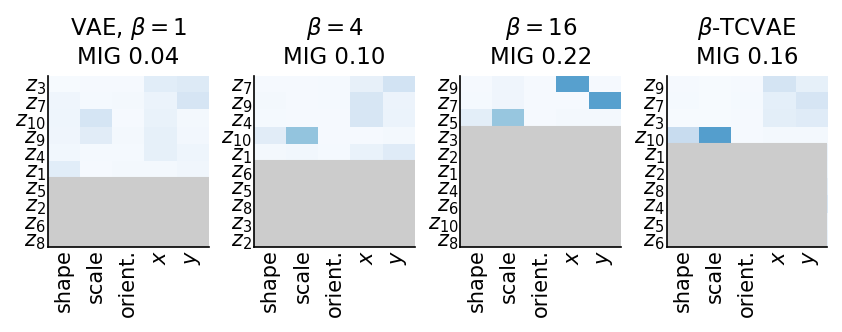

In [22]:
for label, v in dsm.items():                                   # the full matrices, printed
    print(label, "| rows: coordinates sorted by KL; columns:", FACTORS)
    for j in np.argsort(v["kl_dims"])[::-1]:
        print(f"   z_{j + 1:<2d} KL {v['kl_dims'][j]:5.2f}  " + "  ".join(f"{x:4.2f}" for x in v["MI"][j]))
with plt.rc_context(SLIDE):
    fig, axs = plt.subplots(1, 4, figsize=(FULL, 2.1), layout="constrained")
    for ax, (label, v) in zip(axs, dsm.items()):
        order = np.argsort(v["kl_dims"])[::-1]
        M_ = v["MI"][order].copy()
        ax.imshow(M_, cmap="Blues", vmin=0, vmax=1, aspect="auto")
        for r, j in enumerate(order):
            if v["kl_dims"][j] < 0.1:                                       # inactive coordinate: grey row
                ax.add_patch(Rectangle((-0.5, r - 0.5), 5, 1, color="0.8", zorder=2))
        ax.set_xticks(range(5)); ax.set_xticklabels(["shape", "scale", "orient.", "$x$", "$y$"], rotation=90)
        ax.set_yticks(range(10)); ax.set_yticklabels([f"$z_{{{j + 1}}}$" for j in order])
        ax.tick_params(length=0, pad=1)
        ax.set_title(f"{label}\nMIG {v['mig']:.2f}")
    save(fig, "dsprites_mi"); plt.show()

The VAE ($\beta=1$, MIG 0.036) spreads every factor over several coordinates: its six active coordinates each carry a little information about $x$, $y$ or scale and none dominates. Increasing $\beta$ helps: $\beta=4$ gives MIG 0.097, mainly through one coordinate that carries the scale (normalised MI 0.40), and $\beta=16$ gives the highest value, 0.222, with three active coordinates: one for $x$ and one for $y$ (0.56 each, with gaps 0.48 and 0.46) and one for the scale (0.39). The β-TCVAE (MIG 0.164) isolates the scale best (gap 0.51) and partly the shape (gap 0.22), with a much smaller distortion than $\beta=16$ (36.1 against 64.5 nats), but it keeps $x$ and $y$ mixed over three coordinates. No model learns the orientation, which, as noted above, is ambiguous for two of the three shapes, and no model separates the shape cleanly. These values are lower than those reported in the literature for long training runs; our models see each image 15 times, about $9\times10^3$ updates, on a CPU budget of under a minute per model.

### 4.5 Traversals on dSprites

Traversals now have a known answer. For the VAE and for the model with the largest MIG, each row varies one active coordinate from $-2.5$ to $2.5$ around the code of one sprite, and the row label gives the factor with which that coordinate shares the most information.

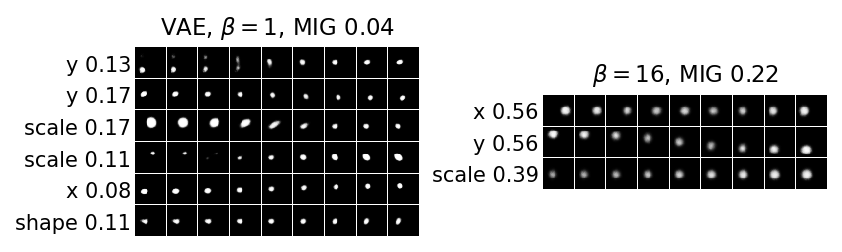

In [23]:
best = max(dsm, key=lambda k: dsm[k]["mig"])
nums["dsprites_best"] = dsm[best]["name"]
seed_img = Xds_ev[3:4]
with plt.rc_context(SLIDE):
    fig, axs = plt.subplots(1, 2, figsize=(FULL, 1.9), layout="constrained")
    for ax, label in zip(axs, ["VAE, $\\beta=1$", best]):
        v = dsm[label]
        dims = list(np.argsort(v["kl_dims"])[::-1][:max(2, int((v["kl_dims"] > 0.1).sum()))][:6])
        mu0 = enc_fn(v["model"], to_unit(seed_img))[0][0]
        rows = traversal_rows(v["model"], mu0, dims, vals=np.linspace(-2.5, 2.5, 9))
        labs = [f"{FACTORS[int(np.argmax(v['MI'][j]))].replace('orientation', 'orient.')} {v['MI'][j].max():.2f}" for j in dims]
        show_rows(rows, labs, ax, shape=(32, 32), cmap="gray")
        ax.set_title(f"{label}, MIG {v['mig']:.2f}")
    save(fig, "dsprites_traversal"); plt.show()

The traversals of the $\beta=16$ model show what a disentangled coordinate looks like: one row moves the sprite horizontally, one vertically, one changes its size, and nothing else changes. The rows of the VAE mix effects: the sprite moves and changes size along the same axis, a row labelled "scale" also deforms the shape, and some rows produce two faint sprites at once, a decoding that belongs to no image of the data set.

<hr/>
## 5. Faces: CelebA

### 5.1 Published results

Faces are the classic showcase of disentangling, for two reasons: we recognise immediately whether a change of the image is "one thing" (the head turns) or several (the head turns and the person becomes someone else), and there is a large labelled data set, CelebA (CelebFaces Attributes) [Z. Liu, P. Luo, X. Wang, X. Tang, *Deep Learning Face Attributes in the Wild*, ICCV 2015, [doi:10.1109/ICCV.2015.425](https://doi.org/10.1109/ICCV.2015.425)]: 202 599 aligned photographs of 10 177 celebrities, each annotated with 40 binary attributes such as `Eyeglasses`, `Male`, `Smiling`, `Wearing_Hat`.

Two published figures set the standard and are shown on the lecture slides. Figure 1 of Higgins *et al.* (ICLR 2017) compares latent traversals of a β-VAE with $\beta=250$, of a VAE and of InfoGAN on CelebA at $64\times64$ pixels: in the β-VAE single coordinates turn the head (azimuth), change the smile, or change the hair, while in the VAE the azimuth coordinate also changes the expression, the glasses and the gender. The paper also notes that the β-VAE did not isolate the presence of sunglasses. The second figure, with the famous arithmetic "man with glasses − man without glasses + woman without glasses = woman with glasses" and a "turn" vector that rotates faces from looking left to looking right, comes from a different kind of generative model: a generative adversarial network (GAN), the deep convolutional GAN of A. Radford, L. Metz, S. Chintala [*Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks*, [arXiv:1511.06434](https://arxiv.org/abs/1511.06434)], trained on faces collected by the authors from the web, not on CelebA. GANs are not part of this course; the figure is shown because it introduced latent arithmetic, which works in any model with a well-organised latent space, and we repeat it with our β-VAE below.

### 5.2 A small CelebA

The official CelebA download is a Google-Drive archive that `torchvision` can fetch only with an extra package (`gdown`). We therefore use a public mirror on the Hugging Face hub, [`flwrlabs/celeba`](https://huggingface.co/datasets/flwrlabs/celeba), which stores the original aligned images together with the 40 attributes and the identity of each celebrity in the official training/validation/test split. We take the first four of its 19 training files, 34 268 images; within these files the images are ordered by identity, so the subset contains about a fifth of the celebrities of the training split. Every image ($178\times218$ pixels) is cropped to the central $140\times140$ square, shifted 15 pixels down onto the face, and reduced to $32\times32$ pixels; the result is stored once in `data/celeba/celeba32.npz` (100 MB). Faces at $32\times32$ are small, and a VAE trained on them on a CPU will produce blurry images: blur is the expected price of a Gaussian latent code with a limited rate, and it grows with $\beta$, as Section 3.4 showed.

CelebA subset: training (20000, 32, 32, 3) test (2000, 32, 32, 3)
  fraction with Eyeglasses  : 0.058
  fraction with Male        : 0.390
  fraction with Smiling     : 0.481
  fraction with Wearing_Hat : 0.053
  fraction with Blond_Hair  : 0.166


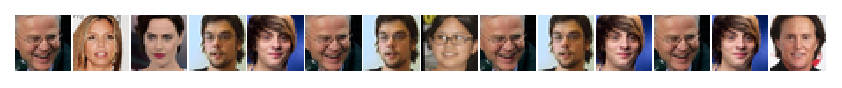

In [24]:
CELEBA_FILE = f"{DATA}/celeba/celeba32.npz"
CELEBA_MIRROR = "https://huggingface.co/datasets/flwrlabs/celeba/resolve/main/img_align%2Bidentity%2Battr"

def build_celeba32(out, n_files=4):
    '''Download n_files training files of the CelebA mirror (parquet: PNG image + 40 attributes per row),
    crop the central 140 x 140 square (15 px below the centre), resize to 32 x 32, store images and attributes.'''
    import pyarrow.parquet as pq
    from PIL import Image
    raw = os.path.join(os.path.dirname(out), "raw")
    os.makedirs(raw, exist_ok=True)
    imgs, attrs, names = [], [], None
    for i in range(n_files):
        f = f"{raw}/train-{i:05d}-of-00019.parquet"
        if not os.path.exists(f):
            urllib.request.urlretrieve(f"{CELEBA_MIRROR}/train-{i:05d}-of-00019.parquet", f)
        t = pq.read_table(f)
        names = names or [c for c in t.column_names if c not in ("image", "celeb_id")]
        for d in t.column("image").to_pylist():
            im = Image.open(io.BytesIO(d["bytes"])).convert("RGB")
            w, h = im.size; l, tp = (w - 140) // 2, (h - 140) // 2 + 15
            imgs.append(np.asarray(im.crop((l, tp, l + 140, tp + 140)).resize((32, 32), Image.LANCZOS), np.uint8))
        attrs.append(np.stack([np.asarray(t.column(n).to_pylist(), bool) for n in names], 1))
    np.savez_compressed(out, images=np.stack(imgs), attrs=np.concatenate(attrs), attr_names=np.array(names))

if not os.path.exists(CELEBA_FILE):
    build_celeba32(CELEBA_FILE)
cz = np.load(CELEBA_FILE)
X_cel, A_cel, ATTR = cz["images"], cz["attrs"], [str(a) for a in cz["attr_names"]]   # (34268, 32, 32, 3) uint8, (34268, 40) bool
perm = np.random.default_rng(4).permutation(len(X_cel))
i_cte, i_ctr = perm[:2000], perm[2000:22000]                   # 2000 test faces, 20 000 training faces
Xc_tr, Xc_te = jnp.asarray(X_cel[i_ctr]), jnp.asarray(X_cel[i_cte])
Ac_tr, Ac_te = A_cel[i_ctr], A_cel[i_cte]
print("CelebA subset: training", Xc_tr.shape, "test", Xc_te.shape)
for a in ["Eyeglasses", "Male", "Smiling", "Wearing_Hat", "Blond_Hair"]:
    print(f"  fraction with {a:12s}: {A_cel[:, ATTR.index(a)].mean():.3f}")

sel = [np.flatnonzero(Ac_te[:, ATTR.index(a)])[:3] for a in ["Eyeglasses", "Male", "Smiling"]]
sel = np.r_[np.arange(5), np.concatenate(sel)]                 # five random test faces, then three each with the attributes
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(FULL, 0.6), layout="constrained")
    show_rows([np.asarray(Xc_te[sel]) / 255.0], [""], ax, shape=(32, 32, 3))
    save(fig, "celeba_data"); plt.show()

### 5.3 A convolutional β-VAE

Dense layers would treat the $32\times32\times3=3072$ numbers of a colour image as an unordered list. A convolutional network uses the fact that neighbouring pixels belong together (Lab 024 used one as a classifier). The encoder applies three $4\times4$ convolutions with stride 2, each halving the image size, $32\to16\to8\to4$, with 32, 64 and 64 channels, then a dense layer of 256 units and the two heads $\boldsymbol\mu,\log\boldsymbol\sigma^2\in\mathbb R^{32}$. The decoder mirrors it: a dense layer maps $\mathbf z$ to $4\times4\times64$ numbers, and three blocks of "double the image size by repeating each pixel, then a $3\times3$ convolution" return to $32\times32\times3$ logits, one Bernoulli probability per colour value. For a minibatch of $B$ images the shapes are
$(B,32,32,3)\to(B,16,16,32)\to(B,8,8,64)\to(B,4,4,64)\to(B,1024)\to(B,256)\to(B,32)$ for $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, and
$(B,32)\to(B,256)\to(B,1024)\to(B,4,4,64)\to(B,8,8,64)\to(B,16,16,32)\to(B,32,32,3)$ in the decoder.

parameters of the convolutional VAE: 706723


                                       ConvVAE Summary                                       
┏━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path   ┃ type    ┃ inputs              ┃ outputs             ┃ Param                      ┃
┡━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encode │ ConvVAE │ float32[2,32,32,3]  │ - float32[2,32]     │ 706,723 (2.8 MB)           │
│        │         │                     │ - float32[2,32]     │                            │
├────────┼─────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│ c1     │ Conv    │ float32[2,32,32,3]  │ float32[2,16,16,32] │ bias: float32[32]          │
│        │         │                     │                     │ kernel: float32[4,4,3,32]  │
│        │         │                     │                     │                            │
│        │         │                     │                     │ 1,568 (6.3 KB)             │
├────────┼─────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│ c2     │ Conv    │ float32[2,16,16,32] │ float32[2,8,8,64]   │ bias: float32[64]          │
│        │         │                     │                     │ kernel: float32[4,4,32,64] │
│        │         │                     │                     │                            │
│        │         │                     │                     │ 32,832 (131.3 KB)          │
├────────┼─────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│ c3     │ Conv    │ float32[2,8,8,64]   │ float32[2,4,4,64]   │ bias: float32[64]          │
│        │         │                     │                     │ kernel: float32[4,4,64,64] │
│        │         │                     │                     │                            │
│        │         │                     │                     │ 65,600 (262.4 KB)          │
├────────┼─────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│ fc     │ Linear  │ float32[2,1024]     │ float32[2,256]      │ bias: float32[256]         │
│        │         │                     │                     │ kernel: float32[1024,256]  │
│        │         │                     │                     │                            │
│        │         │                     │                     │ 262,400 (1.0 MB)           │
├────────┼─────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│ mu     │ Linear  │ float32[2,256]      │ float32[2,32]       │ bias: float32[32]          │
│        │         │                     │                     │ kernel: float32[256,32]    │
│        │         │                     │                     │                            │
│        │         │                     │                     │ 8,224 (32.9 KB)            │
├────────┼─────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│ logvar │ Linear  │ float32[2,256]      │ float32[2,32]       │ bias: float32[32]          │
│        │         │                     │                     │ kernel: float32[256,32]    │
│        │         │                     │                     │                            │
│        │         │                     │                     │ 8,224 (32.9 KB)            │
├────────┼─────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│        │         │                     │               Total │ 706,723 (2.8 MB)           │
└────────┴─────────┴─────────────────────┴─────────────────────┴────────────────────────────┘
                                                                                             
                             Total Parameters: 706,723 (2.8 MB)                              

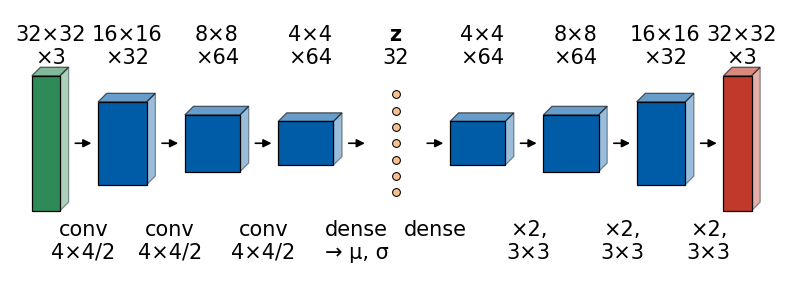

In [25]:
def upsample2(h):
    '''(B, H, W, C) -> (B, 2H, 2W, C): every pixel repeated in a 2 x 2 block.'''
    return jnp.repeat(jnp.repeat(h, 2, axis=1), 2, axis=2)

class ConvVAE(nnx.Module):
    '''Convolutional VAE for 32 x 32 x 3 images, Bernoulli pixels.
    encoder: conv 4x4/2 (32) -> conv 4x4/2 (64) -> conv 4x4/2 (64) -> dense 256 -> mu, logvar (d each)
    decoder: dense 256 -> dense 4*4*64 -> [upsample x2, conv 3x3] x 3 -> logits (B, 32, 32, 3)'''
    def __init__(self, d, *, rngs):
        self.c1 = nnx.Conv(3, 32, (4, 4), strides=2, rngs=rngs)
        self.c2 = nnx.Conv(32, 64, (4, 4), strides=2, rngs=rngs)
        self.c3 = nnx.Conv(64, 64, (4, 4), strides=2, rngs=rngs)
        self.fc = nnx.Linear(4 * 4 * 64, 256, rngs=rngs)
        self.mu, self.logvar = nnx.Linear(256, d, rngs=rngs), nnx.Linear(256, d, rngs=rngs)
        self.g1, self.g2 = nnx.Linear(d, 256, rngs=rngs), nnx.Linear(256, 4 * 4 * 64, rngs=rngs)
        self.d1 = nnx.Conv(64, 64, (3, 3), rngs=rngs)
        self.d2 = nnx.Conv(64, 32, (3, 3), rngs=rngs)
        self.d3 = nnx.Conv(32, 3, (3, 3), rngs=rngs)
    def encode(self, x):                                             # x: (B, 32, 32, 3) in [0, 1]
        h = nnx.relu(self.c1(x))                                     # (B, 16, 16, 32)
        h = nnx.relu(self.c2(h))                                     # (B, 8, 8, 64)
        h = nnx.relu(self.c3(h))                                     # (B, 4, 4, 64)
        h = nnx.relu(self.fc(h.reshape(h.shape[0], -1)))            # (B, 256)
        return self.mu(h), self.logvar(h)                            # (B, d) each
    def decode(self, z):                                             # z: (B, d)
        h = nnx.relu(self.g2(nnx.relu(self.g1(z)))).reshape(-1, 4, 4, 64)
        h = nnx.relu(self.d1(upsample2(h)))                          # (B, 8, 8, 64)
        h = nnx.relu(self.d2(upsample2(h)))                          # (B, 16, 16, 32)
        return self.d3(upsample2(h))                                 # (B, 32, 32, 3) logits

D_CEL = 32
_c = ConvVAE(D_CEL, rngs=nnx.Rngs(0))
_mu, _ = _c.encode(to_unit(Xc_tr[:4]))
assert _mu.shape == (4, D_CEL) and _c.decode(_mu).shape == (4, 32, 32, 3)
print("parameters of the convolutional VAE:", n_params(_c))
print(nnx.tabulate(_c, to_unit(Xc_tr[:2]), method="encode", depth=1))

with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(FULL, 1.8), layout="constrained")
    draw_conv_vae([(32, 3, ""), (16, 32, "conv\n4×4/2"), (8, 64, "conv\n4×4/2"), (4, 64, "conv\n4×4/2")], D_CEL,
                  [(4, 64, "dense"), (8, 64, "×2,\n3×3"), (16, 32, "×2,\n3×3"), (32, 3, "×2,\n3×3")], ax)
    save(fig, "arch_conv"); plt.show()

The drawing shows the encoder narrowing the image into ever smaller but deeper stacks of feature maps, down to the 32 numbers of $\mathbf z$, and the decoder widening them back; the table lists the same layers with their parameter shapes. We train one model with $\beta=3$ for 10 epochs on 20 000 training faces, which takes about 37 minutes on 8 CPU cores. The architecture follows the one Higgins *et al.* used for CelebA (their Table 1: $4\times4$ convolutions with stride 2 and 32 or 64 channels, a dense layer of 256 units, $d=32$), scaled down to $32\times32$ images. Their model, for $64\times64\times3$ images, used $\beta=250$ with a Gaussian decoder, whose reconstruction term is measured on a different scale than our BCE, so the two values of $\beta$ cannot be compared directly; we chose $\beta$ such that the faces remain recognisable while several coordinates switch off.

celeba_beta3: loaded from checkpoints/celeba_beta3.npz (trained for 10 epochs in 2235 s)


test: D = 1721.5  R = 15.8 nats per image;  active coordinates: 18 of 32
KL per coordinate, sorted: [2.08 1.65 1.63 1.52 1.44 1.36 1.12 0.86 0.82 0.8  0.69 0.21 0.2  0.18
 0.14 0.14 0.12 0.11 0.1  0.09 0.09 0.06 0.06 0.05 0.05 0.04 0.04 0.03
 0.03 0.02 0.02 0.02]


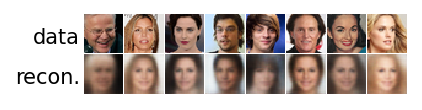

In [26]:
BETA_CEL, EPOCHS_CEL = 3, 10
cel, hist_cel = fit(f"celeba_beta{BETA_CEL:g}", ConvVAE(D_CEL, rngs=nnx.Rngs(5)), bvae_loss(BETA_CEL), (Xc_tr,),
                    epochs=EPOCHS_CEL, seed=5, log_every=2)
D, R, kl = in_chunks(lambda x: rate_distortion(cel, x, jax.random.key(0)), Xc_te, chunk=500)
kl_cel = kl.mean(0)
order_cel = np.argsort(kl_cel)[::-1]
nums["celeba"] = {"beta": BETA_CEL, "D": float(D.mean()), "R": float(R.mean()), "active": int((kl_cel > 0.1).sum()),
                  "train_minutes": hist_cel["seconds"] / 60, "kl_dims_sorted": kl_cel[order_cel].tolist()}
print(f"test: D = {D.mean():.1f}  R = {R.mean():.1f} nats per image;  active coordinates: {(kl_cel > 0.1).sum()} of {D_CEL}")
print("KL per coordinate, sorted:", np.round(kl_cel[order_cel], 2))

mu_ctr = in_chunks(lambda x: enc_fn(cel, to_unit(x))[0], Xc_tr, chunk=1000)        # (32268, d) codes of the training faces
mu_cte = in_chunks(lambda x: enc_fn(cel, to_unit(x))[0], Xc_te, chunk=1000)
rec = np.asarray(dec_fn(cel, jnp.asarray(mu_cte[:10])))
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(HALF, 0.8), layout="constrained")
    show_rows([np.asarray(Xc_te[:8]) / 255.0, rec[:8]], ["data", "recon."], ax, shape=(32, 32, 3))
    save(fig, "celeba_recon"); plt.show()

The model uses 18 of its 32 coordinates ($\overline{\mathrm{KL}}_k>0.1$ nats) and has a rate of 15.8 nats per face. The reconstructions keep the pose, the skin and hair colour, the background and the overall shape of the face, but not the details: eyes, mouths and glasses are smeared. A rate of 15.8 nats is a small budget for a $32\times32$ colour image, and blur is the visible consequence (Section 3.3).

### 5.4 Latent traversals of faces

To find out what each coordinate does, we use two tools together. The first is the traversal: decode the code of a test face with one coordinate moved from $-3$ to $3$. The second is a label we did not use in training: for each coordinate $k$ we compute the Pearson correlation coefficient between $\mu_k(\mathbf x)$ and each of the 40 binary attributes $a(\mathbf x)\in\{0,1\}$ over the training faces, $\rho(\mu_k,a)=\frac{\langle\mu_ka\rangle-\langle\mu_k\rangle\langle a\rangle}{\sqrt{\mathrm{Var}\,\mu_k\,\mathrm{Var}\,a}}\in[-1,1]$ ($\langle\cdot\rangle$ is the average over the faces), which is $\pm1$ for an exact linear relation and 0 when there is no linear relation at all, and write the attribute with the largest $|\rho|$ next to the row. A large correlation says that the coordinate tracks the attribute; it does not say that it tracks nothing else.

z_10: KL =  2.08 nats   strongest attribute Blond_Hair           rho = -0.26
z_32: KL =  1.65 nats   strongest attribute Attractive           rho = +0.09
z_25: KL =  1.63 nats   strongest attribute Blond_Hair           rho = +0.24
z_12: KL =  1.52 nats   strongest attribute Black_Hair           rho = -0.19
z_23: KL =  1.44 nats   strongest attribute Blond_Hair           rho = +0.22
z_19: KL =  1.36 nats   strongest attribute Wearing_Lipstick     rho = -0.35
z_14: KL =  1.12 nats   strongest attribute Wearing_Lipstick     rho = +0.23
z_ 2: KL =  0.86 nats   strongest attribute Bangs                rho = +0.25
z_22: KL =  0.82 nats   strongest attribute Pale_Skin            rho = +0.12
z_24: KL =  0.80 nats   strongest attribute Young                rho = +0.06
z_20: KL =  0.69 nats   strongest attribute Blond_Hair           rho = -0.18
z_29: KL =  0.21 nats   strongest attribute Bangs                rho = -0.20


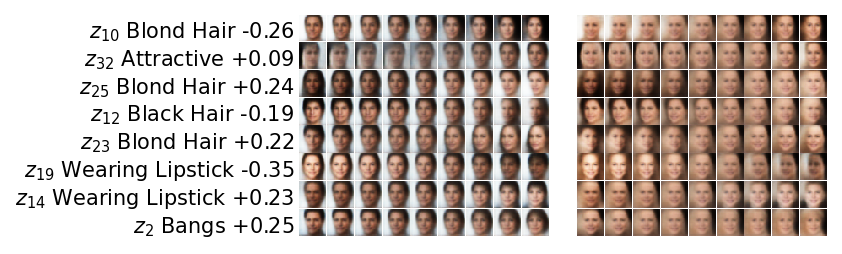

In [27]:
Ac_f = Ac_tr.astype(float)
rho_attr = np.corrcoef(np.c_[mu_ctr, Ac_f].T)[:D_CEL, D_CEL:]                          # (d, 40)
active_cel = [k for k in order_cel if kl_cel[k] > 0.1]
for k in active_cel[:12]:
    a = int(np.argmax(np.abs(rho_attr[k])))
    print(f"z_{k + 1:2d}: KL = {kl_cel[k]:5.2f} nats   strongest attribute {ATTR[a]:20s} rho = {rho_attr[k, a]:+.2f}")
nums["celeba_top_attr"] = {f"z{k + 1}": [ATTR[int(np.argmax(np.abs(rho_attr[k])))], float(rho_attr[k, np.argmax(np.abs(rho_attr[k]))]),
                                         float(kl_cel[k])] for k in active_cel[:12]}

dims = (active_cel + [k for k in order_cel if k not in active_cel])[:8]   # active coordinates first
seeds = [3, 11]
# each row: 9 steps of z_k for the first face, a white gap, 9 steps for the second face
both = [traversal_rows(cel, mu_cte[s], dims, vals=np.linspace(-3, 3, 9)) for s in seeds]
rows = [np.concatenate([a.reshape(-1, 32, 32, 3), np.ones((1, 32, 32, 3)), b.reshape(-1, 32, 32, 3)]) for a, b in zip(*both)]
labs = [f"$z_{{{k + 1}}}$ {ATTR[int(np.argmax(np.abs(rho_attr[k])))].replace('_', ' ')} {rho_attr[k, np.argmax(np.abs(rho_attr[k]))]:+.2f}" for k in dims]
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(FULL, 2.1), layout="constrained")
    show_rows(rows, labs, ax, shape=(32, 32, 3))
    save(fig, "celeba_traversal"); plt.show()

The coordinates with the largest KL change global properties of the image, each continuously and mostly one at a time. $z_{10}$ darkens the background, $z_{32}$ moves the illumination from one side of the face to the other, $z_{25}$ changes skin and hair from dark to light, $z_{23}$ turns a short-haired male face into a female face with long hair, $z_{19}$ goes from a bright, smiling face to a darker, neutral one, and $z_2$ changes the length of the hair and the fringe. None of the eight coordinates turns the head cleanly to the left or right as in the published figure, and the correlations with the attributes are weak (the largest $|\rho|$ is 0.35, `Wearing_Lipstick` for $z_{19}$): the labels of CelebA describe local details, while the coordinates of a low-rate model describe global appearance. The attribute names next to the rows are therefore the best match among 40 labels, not names of the coordinates.

### 5.5 Arithmetic with attributes

The attribute labels allow a second, more direct way to move a face in a chosen direction. For a binary attribute $a$ we average the codes of all training faces that have it and of all that do not, and take the difference,
$$\mathbf v_a=\big\langle\boldsymbol\mu_\phi(\mathbf x)\big\rangle_{a=1}-\big\langle\boldsymbol\mu_\phi(\mathbf x)\big\rangle_{a=0}.$$
Adding $\alpha\,\mathbf v_a$ to the code of a face without the attribute and decoding should add the attribute, more strongly for larger $\alpha$. The labels are used only after training, to find the direction; the model itself never saw them. We do this for three attributes: `Eyeglasses`, `Male` and `Smiling`. Each block of the figure shows five test faces without the attribute (rows) for $\alpha=0,0.5,1,1.5,2$ (columns); $\alpha=0$ is the plain reconstruction.

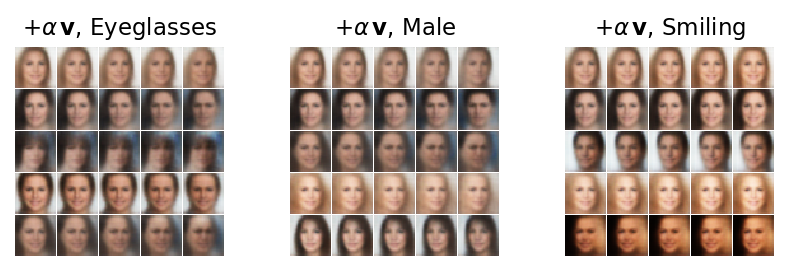

{'Eyeglasses': 0.97, 'Male': 0.97, 'Smiling': 0.79} (lengths of the attribute vectors)


In [28]:
def attr_vector(a):
    j = ATTR.index(a)
    return mu_ctr[Ac_tr[:, j]].mean(0) - mu_ctr[~Ac_tr[:, j]].mean(0)

alphas = np.array([0, 0.5, 1.0, 1.5, 2.0])
vecs = {}
with plt.rc_context(SLIDE):
    fig, axs = plt.subplots(1, 3, figsize=(FULL, 1.7), layout="constrained")
    for ax, a in zip(axs, ["Eyeglasses", "Male", "Smiling"]):
        vecs[a] = attr_vector(a)
        without = np.flatnonzero(~Ac_te[:, ATTR.index(a)])[:5]
        rows = [np.asarray(dec_fn(cel, jnp.asarray(mu_cte[i][None] + alphas[:, None] * vecs[a][None]))) for i in without]
        show_rows([r.reshape(-1, 32, 32, 3) for r in rows], [""] * 5, ax, shape=(32, 32, 3))
        ax.set_title(f"$+\\alpha\\,\\mathbf{{v}}$, {a}")
        nums[f"celeba_vec_norm_{a}"] = float(np.linalg.norm(vecs[a]))
    save(fig, "celeba_attribute_arithmetic"); plt.show()
print({a: round(float(np.linalg.norm(v)), 2) for a, v in vecs.items()}, "(lengths of the attribute vectors)")

The directions exist but are weak. With increasing $\alpha$ the `Eyeglasses` vector darkens the region around the eyes (most visible in the fourth and fifth rows, where a dark band appears at $\alpha=2$), the `Male` vector darkens and broadens the faces and shortens the hair, and the `Smiling` vector brightens the lower half of the face; none of them adds a sharp pair of glasses or a clear smile. The vectors have lengths 0.97, 0.97 and 0.79, comparable to one standard deviation of a single coordinate, and at $32\times32$ pixels a pair of glasses is a detail that a code of 15.8 nats largely cannot afford.

The same vectors reproduce the published equation. We average the codes of three groups of training faces, men with glasses, men without glasses and women without glasses, decode each average, and decode the combination $\bar{\boldsymbol\mu}_{\text{man, glasses}}-\bar{\boldsymbol\mu}_{\text{man}}+\bar{\boldsymbol\mu}_{\text{woman}}$. The second row does the same arithmetic with the average *images* instead of codes.

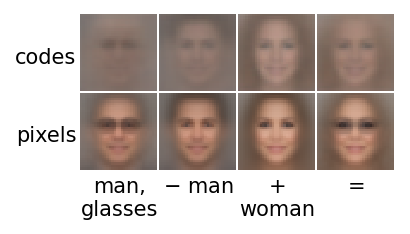

group sizes: {'man with glasses': 871, 'man without glasses': 6977, 'woman without glasses': 11899}


In [29]:
jm, jg = ATTR.index("Male"), ATTR.index("Eyeglasses")
groups = {"man with glasses": Ac_tr[:, jm] & Ac_tr[:, jg], "man without glasses": Ac_tr[:, jm] & ~Ac_tr[:, jg],
          "woman without glasses": ~Ac_tr[:, jm] & ~Ac_tr[:, jg]}
mbar = {k: mu_ctr[v].mean(0) for k, v in groups.items()}
xbar = {k: np.asarray(Xc_tr)[v].mean(0) / 255.0 for k, v in groups.items()}
z_eq = mbar["man with glasses"] - mbar["man without glasses"] + mbar["woman without glasses"]
lat = np.asarray(dec_fn(cel, jnp.asarray(np.stack(list(mbar.values()) + [z_eq]))))
pix = list(xbar.values()); pix.append(np.clip(pix[0] - pix[1] + pix[2], 0, 1))
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(HALF, 1.45), layout="constrained")
    show_rows([lat.reshape(-1, 32, 32, 3), np.stack(pix)], ["codes", "pixels"], ax, shape=(32, 32, 3))
    ax.set_xticks([16 + 33 * i for i in range(4)])
    ax.set_xticklabels(["man,\nglasses", "$-$ man", "+\nwoman", "="])
    save(fig, "celeba_glasses_equation"); plt.show()
print("group sizes:", {k: int(v.sum()) for k, v in groups.items()})
nums["celeba_group_sizes"] = {k: int(v.sum()) for k, v in groups.items()}

The decoded average codes are very blurred average faces: the average of thousands of codes lies near the centre of the latent space, where the decoder produces the "mean face". Their combination is again a mean face, now with a faint dark band at the eyes. The pixel arithmetic, in contrast, produces a recognisable woman with glasses. This is the opposite of what Radford *et al.* found, and the reason is instructive: CelebA images are *aligned*, so the eyes of all faces are at the same pixels and averaging pixels is meaningful, whereas the faces of Radford *et al.* were not aligned and pixel averages overlapped incoherently. Latent arithmetic pays off when the data vary in ways that pixels cannot average, and when the latent code is rich enough to carry the attribute; our small, blurred model is at the edge of both.

<hr/>
## 6. Interpreting the latent space of spin models

### 6.1 From generating to understanding

In Labs 024 and 025 the VAE was a generator, judged by the quality of what it draws. Here we use the β-VAE for something else: to learn about the physical system from which the data come. The network receives only spin snapshots, no temperature, no phase, no Hamiltonian, and compresses each snapshot into a few latent numbers that the β-term pushes to be independent. If the compression is good, these numbers must describe the most important ways in which snapshots differ from each other, and for a system in thermal equilibrium those are the macroscopic quantities. The question is whether we can *read* them.

The course has met this question twice. In Lecture 4 class activation maps showed *where* in an image a classifier looks, a way to interpret a trained network. In Lecture 5 the first principal component of Ising snapshots turned out to be the magnetisation, $z_1\propto m$ [L. Wang, Phys. Rev. B **94**, 195105 (2016), [doi:10.1103/PhysRevB.94.195105](https://doi.org/10.1103/PhysRevB.94.195105)], and S. J. Wetzel found that the latent variable of a VAE trained on Ising snapshots correlates with the magnetisation [Phys. Rev. E **96**, 022140 (2017), [doi:10.1103/PhysRevE.96.022140](https://doi.org/10.1103/PhysRevE.96.022140)]. R. Iten, T. Metger, H. Wilming, L. del Rio and R. Renner used a related architecture with a β-weighted latent layer (the β-VAE cost function of this lab) to recover the spring constant and the damping factor of a damped pendulum from time series of its position alone [*Discovering Physical Concepts with Neural Networks*, Phys. Rev. Lett. **124**, 010508 (2020), [doi:10.1103/PhysRevLett.124.010508](https://doi.org/10.1103/PhysRevLett.124.010508)].

The procedure we follow has four steps, and the definitions are the same for both models:

1. train a β-VAE on snapshots only, with a small latent dimension $d=8$;
2. keep the **active** coordinates, those whose average KL over held-out snapshots exceeds $0.1$ nats, $\overline{\mathrm{KL}}_k>0.1$; the others carry no information;
3. **probe** each active coordinate: compute the encoder mean $\mu_k(\mathbf s)$ for every held-out snapshot $\mathbf s$, and its Pearson correlation coefficient with each observable $O(\mathbf s)$ computed from the spins,
$$\rho_{kO}=\frac{\langle\mu_kO\rangle-\langle\mu_k\rangle\langle O\rangle}{\sqrt{\mathrm{Var}\,\mu_k\;\mathrm{Var}\,O}}\in[-1,1],$$
where $\langle\cdot\rangle$ is the average over held-out snapshots of all temperatures;
4. collect the coefficients in a table (coordinates × observables) and look at scatter plots of $\mu_k$ against the observable with the largest $|\rho_{kO}|$.

The observables, as in Lab 025, are the magnetisation $m=\frac1N\sum_is_i$ and its modulus $|m|$, the energy per spin $e=H/N$, the temperature $T$ at which the snapshot was simulated, and, for the $J_1$–$J_2$ model, the two stripe order parameters $m_x=\frac1N\sum_{x,y}(-1)^xs_{x,y}$ and $m_y=\frac1N\sum_{x,y}(-1)^ys_{x,y}$ (spins alternating along $x$ or along $y$), their moduli, $m_{\rm str}=\sqrt{m_x^2+m_y^2}$ and the coupling ratio $g=J_2/J_1$. Pearson's coefficient detects *linear* relations: a coordinate that encodes $m$ gives $|\rho|\approx1$ with $m$, while a coordinate that is a symmetric function of $m$ (for example $\mu_k\approx m^2$) gives $\rho\approx0$ with $m$ and must be found with $|m|$.

### 6.2 The 2D Ising model

We use the 9472 snapshots of Lab 025 and Lecture 5: $L=30$, 256 Swendsen–Wang configurations at each of 37 temperatures in $[1.5,3.5]$. A random 80% of them train the network (bits $b_i=(s_i+1)/2$, Bernoulli decoder, dense $900\to512\to256\to d=8$ and back); the remaining 20% are held out for probing. We train two models, $\beta=1$ and $\beta=4$, for 40 epochs each.

In [30]:
def unpack_spins(packed, L):
    '''Packed bits (..., L, ceil(L/8)) uint8 -> spins (..., L, L) int8 with values -1, +1.'''
    return np.unpackbits(packed, axis=-1, count=L).astype(np.int8) * 2 - 1

di = np.load(f"{DATA}/ising_L30.npz")
L_I = int(di["L"]); o = np.argsort(di["T"]); T_I = di["T"][o]
S_I = unpack_spins(di["configs"], L_I)[o]                                   # (37, 256, 30, 30)
nT, nS = S_I.shape[:2]
s = S_I.reshape(-1, L_I, L_I).astype(np.float32)                            # (9472, 30, 30)
obs_I = {"m": s.mean((1, 2)), "|m|": np.abs(s.mean((1, 2))),
         "e": -(s * np.roll(s, 1, 1) + s * np.roll(s, 1, 2)).mean((1, 2)),  # each bond once, J = 1
         "T": np.repeat(T_I, nS)}
X_I = ((S_I.reshape(-1, L_I * L_I) > 0) * 255).astype(np.uint8)        # bits as 0 / 255, read by to_unit
pI = np.random.default_rng(6).permutation(len(X_I)); itr_I, ite_I = pI[:int(0.8 * len(pI))], pI[int(0.8 * len(pI)):]
print("Ising:", S_I.shape, "| training", len(itr_I), "held out", len(ite_I))
assert np.isclose(obs_I["e"].min(), -2, atol=0.1)                           # the lowest-T snapshots are close to the ground state

def probe(model, X, O, thr=0.1):
    '''Encoder means of the held-out snapshots, KL per coordinate, active coordinates (sorted by KL), and the
    Pearson coefficient rho[k, l] of mu_k with observable l.'''
    mu, lv = in_chunks(lambda x: enc_fn(model, to_unit(x)), jnp.asarray(X))
    kl = np.asarray(kl_per_dim(mu, lv)).mean(0)
    act = [k for k in np.argsort(kl)[::-1] if kl[k] > thr]
    if len(act) < 2:                                                  # keep at least two coordinates for the plots
        act = list(np.argsort(kl)[::-1][:2])
    Om = np.stack(list(O.values()), 1)
    rho = np.corrcoef(np.c_[mu, Om].T)[:mu.shape[1], mu.shape[1]:]
    return {"mu": mu, "kl": kl, "active": act, "rho": rho, "names": list(O)}

ising = {}
for beta in [1.0, 4.0]:
    model, hist = fit(f"ising_beta{beta:g}", DenseVAE(L_I * L_I, 8, hidden=(512, 256), rngs=nnx.Rngs(7)),
                      bvae_loss(beta), (jnp.asarray(X_I[itr_I]),), epochs=40, seed=7, log_every=10)
    P = probe(model, X_I[ite_I], {k: v[ite_I] for k, v in obs_I.items()})
    ising[beta] = dict(model=model, hist=hist, **P)
    print(f"beta = {beta:g}: active coordinates {[k + 1 for k in P['active']]}, KL = {np.round(P['kl'][P['active']], 2)}")
    for k in P["active"]:
        print(f"   z_{k + 1}: " + "  ".join(f"rho(mu, {n}) = {r:+.2f}" for n, r in zip(P["names"], P["rho"][k])))

Ising: (37, 256, 30, 30) | training 7577 held out 1895


ising_beta1: loaded from checkpoints/ising_beta1.npz (trained for 40 epochs in 12 s)


beta = 1: active coordinates [np.int64(7), np.int64(3), np.int64(4), np.int64(1), np.int64(8), np.int64(5), np.int64(2), np.int64(6)], KL = [3.04 1.64 1.53 1.51 1.5  1.47 1.47 1.4 ]
   z_7: rho(mu, m) = +0.99  rho(mu, |m|) = -0.08  rho(mu, e) = +0.10  rho(mu, T) = +0.11
   z_3: rho(mu, m) = -0.02  rho(mu, |m|) = -0.03  rho(mu, e) = +0.03  rho(mu, T) = +0.02
   z_4: rho(mu, m) = -0.07  rho(mu, |m|) = -0.02  rho(mu, e) = +0.02  rho(mu, T) = +0.02
   z_1: rho(mu, m) = -0.09  rho(mu, |m|) = +0.16  rho(mu, e) = -0.15  rho(mu, T) = -0.13
   z_8: rho(mu, m) = +0.00  rho(mu, |m|) = +0.03  rho(mu, e) = -0.03  rho(mu, T) = -0.04
   z_5: rho(mu, m) = +0.06  rho(mu, |m|) = +0.02  rho(mu, e) = -0.03  rho(mu, T) = -0.02
   z_2: rho(mu, m) = -0.00  rho(mu, |m|) = -0.04  rho(mu, e) = +0.02  rho(mu, T) = +0.01
   z_6: rho(mu, m) = +0.07  rho(mu, |m|) = +0.05  rho(mu, e) = -0.05  rho(mu, T) = -0.04
ising_beta4: loaded from checkpoints/ising_beta4.npz (trained for 40 epochs in 12 s)
beta = 4: active coor

One coordinate is the magnetisation. In both models the coordinate with the largest KL ($z_7$, 3.04 nats for $\beta=1$ and 2.23 nats for $\beta=4$) has $\rho=+0.99$ with $m$, and no other coordinate exceeds $|\rho|=0.16$ with any observable. The difference between the two models lies in the remaining coordinates: for $\beta=1$ all eight are active (each 1.4 to 1.6 nats besides $z_7$) and none of them correlates with $m$, $|m|$, $e$ or $T$: they encode microscopic details of individual snapshots. For $\beta=4$ only three of them remain, with about 0.5 nats each: the larger weight of the KL term removes most of the code that does not describe macroscopic properties.

The scatter plots make the table concrete. On the left, every held-out snapshot is a point in the plane of the two most active coordinates, coloured by its temperature; in the middle and on the right, the coordinate with the largest $|\rho|$ with $m$ and the coordinate with the largest $|\rho|$ with $e$ are plotted against these observables.

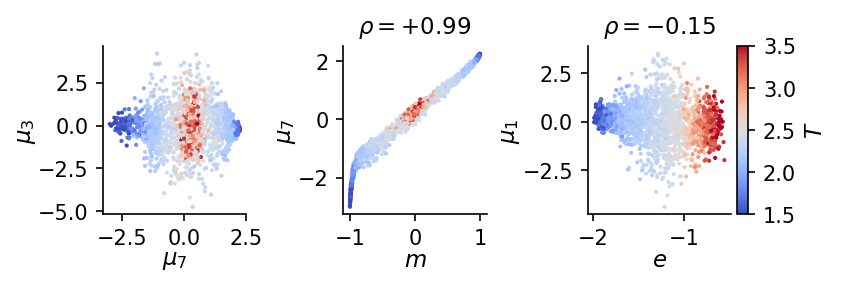

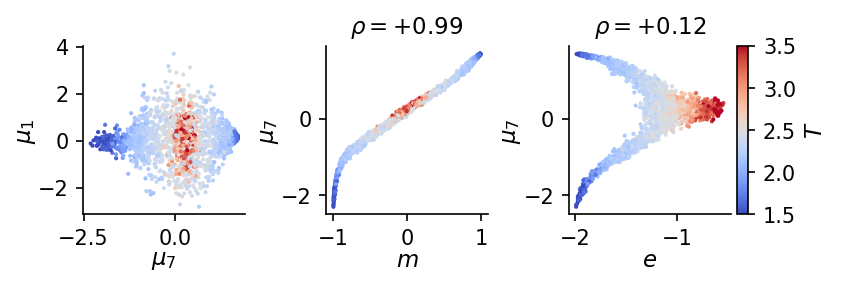

In [31]:
def ising_scatter(P, beta, name=None):
    '''Left: held-out snapshots in the plane of the two most active coordinates; middle, right: the coordinate with the
    largest |rho| with m, with e, against that observable. Colour: temperature.'''
    T_te = obs_I["T"][ite_I]
    with plt.rc_context(SLIDE):
        fig, axs = plt.subplots(1, 3, figsize=(FULL, 1.8), layout="constrained")
        a, b = P["active"][:2]
        sc = axs[0].scatter(P["mu"][:, a], P["mu"][:, b], c=T_te, s=1, cmap="coolwarm", rasterized=True)
        axs[0].set_xlabel(f"$\\mu_{{{a + 1}}}$", labelpad=0); axs[0].set_ylabel(f"$\\mu_{{{b + 1}}}$", labelpad=0)
        for ax, obs in zip(axs[1:], ["m", "e"]):
            l = P["names"].index(obs)
            k = max(P["active"], key=lambda k: abs(P["rho"][k, l]))
            ax.scatter(obs_I[obs][ite_I], P["mu"][:, k], c=T_te, s=1, cmap="coolwarm", rasterized=True)
            ax.set_xlabel(f"${obs}$", labelpad=0); ax.set_ylabel(f"$\\mu_{{{k + 1}}}$", labelpad=0)
            ax.set_title(f"$\\rho = {P['rho'][k, l]:+.2f}$")
        fig.colorbar(sc, ax=axs, label="$T$", pad=0.01, aspect=15)
        if name: save(fig, name)
        plt.show()

for beta in [1.0, 4.0]:
    ising_scatter(ising[beta], beta, name=f"ising_probe_beta{beta:g}")
nums["ising"] = {f"{b:g}": {"active": [int(k) + 1 for k in ising[b]["active"]], "kl_active": ising[b]["kl"][ising[b]["active"]].tolist(),
                            "rho": {f"z{k + 1}": dict(zip(ising[b]["names"], map(float, ising[b]["rho"][k]))) for k in ising[b]["active"]}}
                 for b in ising}

The scatter plots show *how* the coordinate encodes the magnetisation. $\mu_7$ is a smooth, monotonic function of $m$, close to linear in the middle and saturating at $m=\pm1$. Against the energy it forms two branches, one for each sign of $m$, which meet at the high-temperature end ($e\approx-0.7$, red): the two ordered phases, $m>0$ and $m<0$, are mapped to the two ends of the axis and the disordered phase to its centre. This also explains why $\rho(\mu_7,e)$ is only $+0.12$: the energy is related to $|\mu_7|$, not to $\mu_7$, a symmetric relation that a linear correlation cannot detect (Exercise 6 finds $\rho(|\mu_7|,e)=-0.88$ for $\beta=4$). The first panel shows the same structure in the latent plane: low-temperature snapshots (blue) sit at the two ends of the $\mu_7$ axis, high-temperature ones (red) in the middle, spread along $\mu_1$.

### 6.3 The $J_1$–$J_2$ model

The frustrated $J_1$–$J_2$ model of Lab 025, $H=-J_1\sum_{\langle ij\rangle}s_is_j+J_2\sum_{\langle\langle ij\rangle\rangle}s_is_j$ with $g=J_2/J_1$, has three phases: a ferromagnet for $g<1/2$ at low $T$, a stripe phase for $g>1/2$ at low $T$, and a paramagnet at high $T$. The stripe phase has four ground states: stripes along $x$ or along $y$, each with two signs. A disentangled code would need separate coordinates for the magnetisation and for each stripe direction. From the $81\times79$ grid of $(g,T)$ points with 100 snapshots each we take 12 snapshots per point, 10 for training and 2 held out, which gives 63 990 training and 12 798 held-out snapshots of $32\times32$ spins. Two models, $\beta=1$ and $\beta=4$, are trained for 8 epochs each.

In [32]:
dj = np.load(f"{DATA}/j1j2_L32.npz")
L_J = int(dj["L"]); g_J = dj["g"]; oT = np.argsort(dj["T"]); T_J = dj["T"][oT]
S_J = unpack_spins(dj["configs"][:, :, :12], L_J)[:, oT]                   # (81, 79, 12, 32, 32)
nG, nTJ = S_J.shape[:2]
GG, TT = np.meshgrid(g_J, T_J, indexing="ij")

def j1j2_obs(S, G, T):
    '''Per-snapshot observables of S (n, L, L) with couplings G (n,) and temperatures T (n,).'''
    s = S.astype(np.float32)
    px = np.where(np.arange(S.shape[-1]) % 2 == 0, 1.0, -1.0)
    nn = sum(np.roll(s, sh, ax) for sh in (1, -1) for ax in (1, 2))                              # 4 nearest neighbours
    nnn = sum(np.roll(np.roll(s, sy, 1), sx, 2) for sy in (1, -1) for sx in (1, -1))              # 4 diagonal neighbours
    m, mx, my = s.mean((1, 2)), (s * px[None, None, :]).mean((1, 2)), (s * px[None, :, None]).mean((1, 2))
    return {"m": m, "|m|": np.abs(m), "m_x": mx, "m_y": my, "|m_x|": np.abs(mx), "|m_y|": np.abs(my),
            "m_str": np.sqrt(mx**2 + my**2), "e": -0.5 * (s * (nn - G[:, None, None] * nnn)).mean((1, 2)),
            "c_nn": (s * nn).mean((1, 2)) / 4, "c_nnn": (s * nnn).mean((1, 2)) / 4, "g": G, "T": T}

S_flat = S_J.reshape(-1, L_J, L_J)                                         # order: g, T, snapshot
G_flat, T_flat = np.repeat(GG.ravel(), 12), np.repeat(TT.ravel(), 12)
obs_J = j1j2_obs(S_flat, G_flat, T_flat)
X_J = ((S_flat.reshape(len(S_flat), -1) > 0) * 255).astype(np.uint8)
snap = np.tile(np.arange(12), nG * nTJ)
itr_J, ite_J = np.flatnonzero(snap < 10), np.flatnonzero(snap >= 10)
print("J1-J2:", S_J.shape, "| g in", [g_J[0], g_J[-1]], "T in", [round(T_J[0], 2), round(T_J[-1], 2)],
      "| training", len(itr_J), "held out", len(ite_J))
# ground states at the largest g: stripes have m_str = 1 and e = -2g (Lab 025)
stripe = np.broadcast_to(np.where(np.arange(L_J) % 2 == 0, 1, -1).astype(np.int8), (L_J, L_J))[None]
o_chk = j1j2_obs(stripe, np.array([g_J[-1]]), np.array([1.0]))
assert np.isclose(o_chk["m_str"][0], 1) and np.isclose(o_chk["e"][0], -2 * g_J[-1])

PROBE_J = ["m", "|m|", "m_x", "m_y", "|m_x|", "|m_y|", "m_str", "e", "g", "T"]
j1j2 = {}
for beta in [1.0, 4.0]:
    model, hist = fit(f"j1j2_beta{beta:g}", DenseVAE(L_J * L_J, 8, hidden=(512, 256), rngs=nnx.Rngs(8)),
                      bvae_loss(beta), (jnp.asarray(X_J[itr_J]),), epochs=8, seed=8, log_every=4)
    P = probe(model, X_J[ite_J], {k: obs_J[k][ite_J] for k in PROBE_J})
    j1j2[beta] = dict(model=model, hist=hist, **P)
    print(f"beta = {beta:g}: active coordinates {[k + 1 for k in P['active']]}, KL = {np.round(P['kl'][P['active']], 2)}")

J1-J2: (81, 79, 12, 32, 32) | g in [np.float64(0.0), np.float64(1.0)] T in [np.float64(0.1), np.float64(4.0)] | training 63990 held out 12798


j1j2_beta1: loaded from checkpoints/j1j2_beta1.npz (trained for 8 epochs in 23 s)


beta = 1: active coordinates [np.int64(7), np.int64(5), np.int64(6)], KL = [1.96 1.48 1.02]
j1j2_beta4: loaded from checkpoints/j1j2_beta4.npz (trained for 8 epochs in 19 s)


beta = 4: active coordinates [np.int64(8), np.int64(7), np.int64(5)], KL = [1.71 0.53 0.48]


The cell prints the full tables of correlation coefficients for both models and draws the one for $\beta=4$ as a picture: rows are the active coordinates, columns the observables, the colour is $\rho_{kO}$ (red positive, blue negative), and coefficients with $|\rho_{kO}|\ge0.3$ are written in the cells.

beta = 1:       m    |m|    m_x    m_y  |m_x|  |m_y|  m_str      e      g      T
   z_7:       -0.86  -0.01  -0.18  +0.32  +0.15  +0.26  +0.31  -0.24  +0.12  -0.23
   z_5:       +0.39  +0.00  -0.58  +0.67  -0.25  +0.16  -0.07  +0.04  -0.01  +0.06
   z_6:       -0.04  -0.07  +0.67  +0.45  +0.21  +0.21  +0.32  -0.19  +0.13  -0.17
beta = 4:       m    |m|    m_x    m_y  |m_x|  |m_y|  m_str      e      g      T
   z_8:       +0.80  +0.04  -0.09  -0.14  -0.38  -0.37  -0.57  +0.40  -0.25  +0.37
   z_7:       +0.12  +0.04  -0.97  -0.13  -0.30  -0.03  -0.26  +0.16  -0.10  +0.15
   z_5:       +0.06  -0.07  -0.12  +0.98  +0.02  +0.24  +0.19  -0.09  +0.10  -0.07


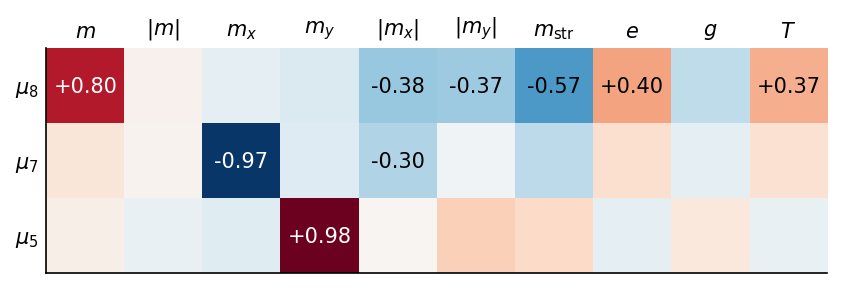

In [33]:
for beta in [1.0, 4.0]:                                          # the full tables, printed
    P = j1j2[beta]
    print(f"beta = {beta:g}:  " + " ".join(f"{n:>6s}" for n in PROBE_J))
    for k in P["active"]:
        print(f"   z_{k + 1}:      " + " ".join(f"{r:+6.2f}" for r in P["rho"][k]))
P = j1j2[4.0]
R_ = P["rho"][P["active"]]
labels_J = ["$m$", "$|m|$", "$m_x$", "$m_y$", "$|m_x|$", "$|m_y|$", "$m_{\\rm str}$", "$e$", "$g$", "$T$"]
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(FULL, 0.42 * len(P["active"]) + 0.55), layout="constrained")
    ax.imshow(R_, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    for i in range(R_.shape[0]):
        for j in range(R_.shape[1]):
            if abs(R_[i, j]) >= 0.3:
                ax.text(j, i, f"{R_[i, j]:+.2f}", ha="center", va="center", fontsize=10, color="white" if abs(R_[i, j]) > 0.7 else "k")
    ax.set_xticks(range(len(PROBE_J))); ax.set_xticklabels(labels_J); ax.xaxis.tick_top()
    ax.set_yticks(range(len(P["active"]))); ax.set_yticklabels([f"$\\mu_{{{k + 1}}}$" for k in P["active"]])
    ax.tick_params(length=0)
    save(fig, "j1j2_correlations"); plt.show()
nums["j1j2"] = {f"{b:g}": {"active": [int(k) + 1 for k in j1j2[b]["active"]], "kl_active": j1j2[b]["kl"][j1j2[b]["active"]].tolist(),
                           "rho": {f"z{k + 1}": dict(zip(PROBE_J, map(float, j1j2[b]["rho"][k]))) for k in j1j2[b]["active"]}}
                for b in j1j2}

The $\beta=4$ model has three active coordinates, and each of them is one order parameter: $z_7$ has $\rho=-0.97$ with the stripe amplitude $m_x$, $z_5$ has $\rho=+0.98$ with $m_y$, and $z_8$ has $\rho=+0.80$ with the magnetisation $m$. The network, which never saw $g$, $T$ or the Hamiltonian, has found the three order parameters of the phase diagram, with the signs that distinguish the degenerate ground states. The $\beta=1$ model (printed table) also has three active coordinates, but mixed ones: $z_7$ follows $m$ ($\rho=-0.86$) while $z_5$ and $z_6$ are combinations of $m_x$ and $m_y$ ($\rho=-0.58,+0.67$ and $+0.67,+0.45$), a rotated version of the stripe plane. This is the effect of $\beta$ described in Section 2.4, seen on a physical system: the stronger pressure towards independent coordinates has aligned the axes with independent order parameters.

Where in the phase diagram is each coordinate used? For every grid point $(g,T)$ we average $|\mu_k|$ over its 12 snapshots and draw the result as a map, next to the maps of $\langle|m|\rangle$ and $\langle m_{\rm str}\rangle$. The modulus is needed because the two signs of the magnetisation, or of a stripe pattern, are equally likely, so the plain average $\langle\mu_k\rangle$ of a coordinate that follows $m$ would be close to zero everywhere.

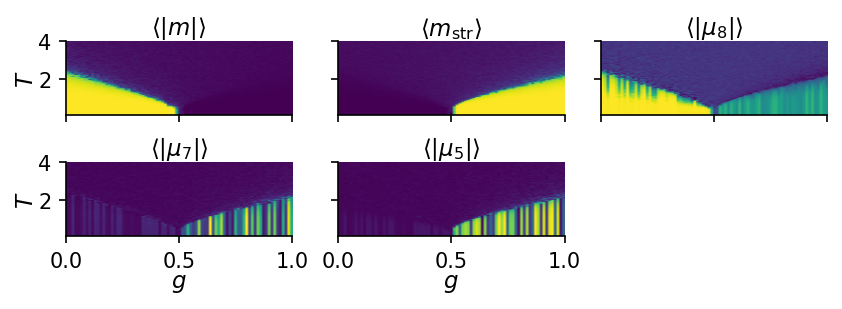

In [34]:
BETA_MAP = 4.0
P = j1j2[BETA_MAP]
mu_all = in_chunks(lambda x: enc_fn(P["model"], to_unit(x))[0], jnp.asarray(X_J))          # (76788, 8)
maps = {f"$\\langle|\\mu_{{{k + 1}}}|\\rangle$": np.abs(mu_all[:, k]).reshape(nG, nTJ, 12).mean(-1) for k in P["active"][:5]}
ref = {"$\\langle|m|\\rangle$": obs_J["|m|"].reshape(nG, nTJ, 12).mean(-1), "$\\langle m_{\\rm str}\\rangle$": obs_J["m_str"].reshape(nG, nTJ, 12).mean(-1)}
panels = {**ref, **maps}
with plt.rc_context(SLIDE):
    ncol = int(np.ceil(len(panels) / 2))
    fig, axs = plt.subplots(2, ncol, figsize=(FULL, 1.95), layout="constrained", sharex=True, sharey=True)
    for ax in axs.ravel()[len(panels):]: ax.axis("off")
    for ax, (t, Mp) in zip(axs.ravel(), panels.items()):
        ax.imshow(Mp.T, origin="lower", aspect="auto", extent=[g_J[0], g_J[-1], T_J[0], T_J[-1]], cmap="viridis")
        ax.set_title(t, pad=2)
    for ax in axs[-1]: ax.set_xlabel("$g$", labelpad=0)
    for ax in axs[:, 0]: ax.set_ylabel("$T$", labelpad=0)
    save(fig, "j1j2_maps"); plt.show()

The maps confirm the reading. $\langle|\mu_8|\rangle$ is large in the ferromagnetic region ($g<1/2$, low $T$), where $\langle|m|\rangle$ is large, and moderate in part of the stripe phase, the residual mixing seen in its correlation $-0.57$ with $m_{\rm str}$. $\langle|\mu_7|\rangle$ and $\langle|\mu_5|\rangle$ are non-zero only in the stripe phase, and there in complementary vertical bands: at a given $g$ all low-temperature snapshots in our data set have stripes along the same direction, so for some values of $g$ the $m_x$ coordinate is used and for others the $m_y$ coordinate. Together the maps reproduce the phase boundaries of $\langle|m|\rangle$ and $\langle m_{\rm str}\rangle$ without any label.

### 6.4 The role of β

Does the β-pressure towards independent coordinates make the probes cleaner? For each observable we take the largest $|\rho_{kO}|$ over the active coordinates and the gap to the second largest, $|\rho|_{(1)}-|\rho|_{(2)}$, the same idea as the MIG of Section 4 with correlations in place of mutual information. A large gap means that one coordinate, and only one, follows the observable.

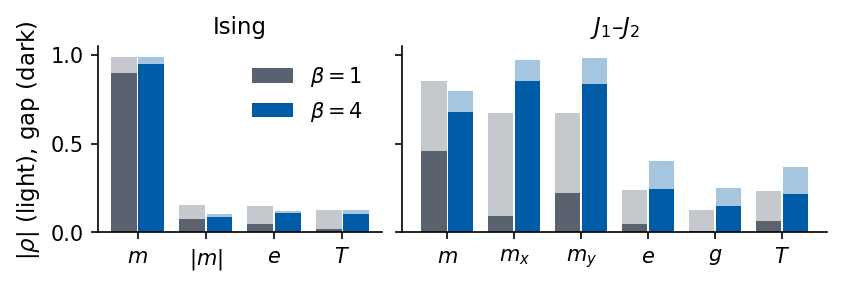

Ising beta = 1: m: |rho| 0.99, gap 0.90  |m|: |rho| 0.16, gap 0.08  e: |rho| 0.15, gap 0.05  T: |rho| 0.13, gap 0.02
Ising beta = 4: m: |rho| 0.99, gap 0.95  |m|: |rho| 0.10, gap 0.09  e: |rho| 0.12, gap 0.11  T: |rho| 0.13, gap 0.10
J1-J2 beta = 1: m: |rho| 0.86, gap 0.46  m_x: |rho| 0.67, gap 0.09  m_y: |rho| 0.67, gap 0.22  e: |rho| 0.24, gap 0.05  g: |rho| 0.13, gap 0.01  T: |rho| 0.23, gap 0.06
J1-J2 beta = 4: m: |rho| 0.80, gap 0.68  m_x: |rho| 0.97, gap 0.85  m_y: |rho| 0.98, gap 0.84  e: |rho| 0.40, gap 0.25  g: |rho| 0.25, gap 0.15  T: |rho| 0.37, gap 0.22


In [35]:
def rho_gap(P, names):
    out = {}
    for n in names:
        r = np.sort(np.abs(P["rho"][P["active"], P["names"].index(n)]))[::-1]
        out[n] = (float(r[0]), float(r[0] - (r[1] if len(r) > 1 else 0.0)))
    return out

gapI = {b: rho_gap(ising[b], ["m", "|m|", "e", "T"]) for b in ising}
gapJ = {b: rho_gap(j1j2[b], ["m", "m_x", "m_y", "e", "g", "T"]) for b in j1j2}
with plt.rc_context(SLIDE):
    fig, axs = plt.subplots(1, 2, figsize=(FULL, 1.8), layout="constrained", sharey=True, gridspec_kw=dict(width_ratios=[4, 6]))
    for ax, gaps, title in [(axs[0], gapI, "Ising"), (axs[1], gapJ, "$J_1$–$J_2$")]:
        names = list(gaps[1.0])
        x = np.arange(len(names))
        for off, b, c in [(-0.2, 1.0, UJGray), (0.2, 4.0, UJBlue)]:
            ax.bar(x + off, [gaps[b][n][0] for n in names], 0.38, color=c, alpha=0.35)
            ax.bar(x + off, [gaps[b][n][1] for n in names], 0.38, color=c, label=f"$\\beta={b:g}$")
        ax.set_xticks(x); ax.set_xticklabels([f"${n}$" for n in names]); ax.set_ylim(0, 1.05); ax.set_title(title)
    axs[0].set_ylabel("$|\\rho|$ (light), gap (dark)")
    axs[0].legend(loc="upper right")
    save(fig, "beta_probe"); plt.show()
for nm, gaps in [("Ising", gapI), ("J1-J2", gapJ)]:
    for b in gaps:
        print(nm, f"beta = {b:g}:", "  ".join(f"{n}: |rho| {v[0]:.2f}, gap {v[1]:.2f}" for n, v in gaps[b].items()))
nums["rho_gap_ising"] = {f"{b:g}": gapI[b] for b in gapI}
nums["rho_gap_j1j2"] = {f"{b:g}": gapJ[b] for b in gapJ}

For the Ising model both values of $\beta$ give the same picture, a single magnetisation coordinate ($|\rho|=0.99$, gap 0.90 for $\beta=1$ and 0.95 for $\beta=4$), because one coordinate suffices to describe the only order parameter. For the $J_1$–$J_2$ model $\beta$ matters: the gap for $m_x$ grows from 0.09 to 0.85 and for $m_y$ from 0.22 to 0.84, and for $m$ from 0.46 to 0.68. With $\beta=4$ each order parameter has its own coordinate; with $\beta=1$ the stripe order is shared between two coordinates. The energy, $g$ and $T$ are matched by no coordinate linearly ($|\rho|\le0.40$), consistent with the fact that they are related to the order parameters through their moduli.

### 6.5 From a check to a discovery tool

For the two models above we knew the order parameters in advance, so the probes are a check: the network, trained without any physical label, finds the quantities physicists use. For a model whose phases are *not* understood the same procedure becomes a discovery tool. A coordinate that is active, and whose average $\langle|\mu_k|\rangle$ changes sharply across some range of a parameter, is a candidate order parameter. The next step is to express it in terms of the spins, for example by fitting $\mu_k$ with a small library of simple functions of the configuration. We try this on the $J_1$–$J_2$ coordinates as if we did not know the answer: a least-squares fit of $\mu_k$ by a linear combination of eight candidate features, the magnetisation $m$, the two stripe amplitudes $m_x,m_y$, their moduli $|m|,|m_x|,|m_y|$ and the nearest- and next-nearest-neighbour correlations $c_{\rm nn}=\frac1{4N}\sum_is_i\sum_{j\in\mathrm{nn}(i)}s_j$ and $c_{\rm nnn}$ (all standardised to zero mean and unit variance), with the coefficient of determination
$$R^2=1-\frac{\sum_{\mathbf s}\big(\mu_k(\mathbf s)-\hat\mu_k(\mathbf s)\big)^2}{\sum_{\mathbf s}\big(\mu_k(\mathbf s)-\langle\mu_k\rangle\big)^2}$$
measuring how much of the coordinate the features explain. The feature with the largest coefficient names the coordinate.

In [36]:
FEATS = ["m", "m_x", "m_y", "|m|", "|m_x|", "|m_y|", "c_nn", "c_nnn"]
F = np.stack([obs_J[f][ite_J] for f in FEATS], 1)
F = (F - F.mean(0)) / F.std(0)
A_ = np.c_[np.ones(len(F)), F]
fits = {}
P = j1j2[BETA_MAP]
for k in P["active"]:
    y = P["mu"][:, k]
    coef, *_ = np.linalg.lstsq(A_, y, rcond=None)
    r2 = 1 - ((y - A_ @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    top = np.argsort(np.abs(coef[1:]))[::-1][:2]
    fits[f"z{k + 1}"] = {"R2": float(r2), "top": [(FEATS[t], float(coef[1 + t])) for t in top]}
    print(f"z_{k + 1}: R^2 = {r2:.3f};  largest coefficients: " + ", ".join(f"{FEATS[t]} {coef[1 + t]:+.2f}" for t in top))
nums["j1j2_fits"] = fits

z_8: R^2 = 0.982;  largest coefficients: m +0.78, |m_x| -0.45
z_7: R^2 = 0.992;  largest coefficients: m_x -0.68, |m_x| -0.09
z_5: R^2 = 0.989;  largest coefficients: m_y +0.58, m_x -0.08


All three coordinates are explained almost completely by the eight features, with $R^2=0.982$, 0.992 and 0.989. The largest coefficient names each of them: $m$ for $z_8$ (with a smaller negative contribution of $|m_x|$, the mixing seen in the maps), $m_x$ for $z_7$ and $m_y$ for $z_5$. On a model whose phases were not known, this is the step that turns an unnamed latent coordinate into a candidate formula in terms of the spins.

### 6.6 Limits of probing

The probes deserve the same caution as any correlation. A large $|\rho|$ with a known quantity *confirms* that a coordinate follows it but does not *explain* the coordinate: it may follow a mixture of quantities that are themselves correlated, as the magnetisation and the energy are across the Ising transition. The sign and the scale of a coordinate are arbitrary, and a coordinate may be a nonlinear function of an observable that a linear probe misses. Which coordinates appear, and how cleanly they separate the quantities, depends on the model, the data, the architecture and $\beta$, which is the practical face of the result of Locatello *et al.* (Section 2.5). And finally, a probe only finds what we probe for: a coordinate that matches none of our observables is either noise or a quantity we have not thought of, and only further work, such as the fits above, can tell which.

<hr/>
## 7. Discovering factors and conditioning on them

We can now compare the two ways of controlling a generative model that Lecture 6 has met.

| | conditional VAE (Labs 024, 025) | β-VAE (this lab) |
|---|---|---|
| training data | pairs $(\mathbf x,\mathbf c)$: images with labels | images $\mathbf x$ only |
| loss | $D+R$ with $\mathbf c$ given to encoder and decoder | $D+\beta R$ |
| the factor of interest | chosen by us, given as $\mathbf c$ | found by the network, identified afterwards |
| guarantee | $\mathbf c$ controls what it labels | none in general (Locatello *et al.*) |
| what $\mathbf z$ carries | everything except $\mathbf c$ | everything, ideally one factor per coordinate |
| typical use | generate on demand | explore the data, find factors, interpret |

The difference is also a difference in how the models are *sampled*. A trained β-VAE is sampled by ancestral sampling, $\mathbf z\sim\mathcal N(0,I)$, then the decoder (Section 1.4); to control a property we must first find the coordinate or the direction that carries it (Sections 3.6, 5.4, 5.5). A trained cVAE is sampled with the condition chosen by us: $\mathbf c$ fixed and $\mathbf z\sim\mathcal N(0,I)$ drawn, which gives many variants of the requested digit, or the same $\mathbf z$ decoded with different $\mathbf c$, which keeps the style and changes the digit. The figure from Lab 024 shows both at once: each row is one condition $\mathbf c=0,\dots,9$, each column one random $\mathbf z$, the same in every row.

![cVAE of Lab 024: rows are the conditions c = 0, ..., 9, columns are random z, the same in every row](../beamer/figures/gen_cvae_mnist.png)

The two are not alternatives but complements. A cVAE is the right tool when the factor is known and labelled: the digit, the temperature of a Monte Carlo run, the point $(g,T)$ of a phase diagram. A β-VAE is the right tool when we do not yet know what varies in the data, and its findings can then be turned into labels for a conditional model. In physics, where the parameters of a simulation are always known, both appear naturally: conditioning on $(g,T)$ to generate, and an unconditioned β-VAE to ask which collective variables the configurations contain.

<hr/>
## 8. Exercises

The exercises are graded by difficulty: (★) a short calculation or a few lines of code, (★★) a derivation or a small experiment, (★★★) an experiment that needs a new training run. A solution follows each exercise in a separate cell; try first.

### Exercise 1 (★)

Show that the KL divergence between two one-dimensional Gaussians is
$$\begin{aligned}\mathrm{KL}\big(\mathcal N(\mu_1,\sigma_1^2)\,\|\,\mathcal N(\mu_2,\sigma_2^2)\big)&=\log\frac{\sigma_2}{\sigma_1}\\&\quad+\frac{\sigma_1^2+(\mu_1-\mu_2)^2}{2\sigma_2^2}-\frac12 ,\end{aligned}$$
check that it reduces to the formula of Lab 024 for $\mu_2=0$, $\sigma_2=1$, and verify it numerically by Monte Carlo for one choice of parameters.

#### Solution of Exercise 1

With $\log\mathcal N(z;\mu,\sigma^2)=-\frac12\log(2\pi\sigma^2)-\frac{(z-\mu)^2}{2\sigma^2}$,
$$\begin{aligned}\mathrm{KL}=\mathbb E_{z\sim\mathcal N(\mu_1,\sigma_1^2)}\Big[&\log\frac{\sigma_2}{\sigma_1}-\frac{(z-\mu_1)^2}{2\sigma_1^2}\\&+\frac{(z-\mu_2)^2}{2\sigma_2^2}\Big].\end{aligned}$$
Under $q$, $\mathbb E[(z-\mu_1)^2]=\sigma_1^2$ and $\mathbb E[(z-\mu_2)^2]=\sigma_1^2+(\mu_1-\mu_2)^2$, which gives the formula. For $\mu_2=0$, $\sigma_2=1$ it becomes $-\log\sigma_1+\frac12(\sigma_1^2+\mu_1^2)-\frac12=\frac12(\mu_1^2+\sigma_1^2-\ln\sigma_1^2-1)$, the expression used throughout. The cell compares the formula with a Monte Carlo average over $10^6$ samples.

In [37]:
def kl_gauss(m1, s1, m2, s2):
    return np.log(s2 / s1) + (s1**2 + (m1 - m2)**2) / (2 * s2**2) - 0.5
m1, s1, m2, s2 = 0.4, 0.7, -0.5, 1.6
zz = m1 + s1 * np.random.default_rng(0).normal(size=1_000_000)
mc = np.mean(np.asarray(log_normal(zz, m1, np.log(s1**2)) - log_normal(zz, m2, np.log(s2**2))))
print(f"closed form {kl_gauss(m1, s1, m2, s2):.4f}   Monte Carlo {mc:.4f}")

closed form 0.5806   Monte Carlo 0.5803


### Exercise 2 (★)

Show that the index-code mutual information obeys $0\le I_q(n;\mathbf z)\le\log N$, and describe the encoders for which each bound is reached. Compare with the MNIST numbers of Section 3.6.

#### Solution of Exercise 2

Write $I_q(n;\mathbf z)=H(n)-H(n|\mathbf z)$ with the entropies of the discrete index. $H(n)=\log N$ because $q(n)=1/N$, and $0\le H(n|\mathbf z)\le H(n)$ because a conditional entropy of a discrete variable is non-negative and conditioning cannot increase entropy. The upper bound is reached when the code determines the index, $H(n|\mathbf z)=0$: the clouds of different images do not overlap. The lower bound is reached when all clouds are the same, so that $\mathbf z$ says nothing about $n$; this is posterior collapse. In Section 3.6 the models with small $\beta$ come close to $\log M=7.60$, the models with large $\beta$ stay well below it.

### Exercise 3 (★★)

(a) Show that the total correlation of a two-dimensional Gaussian with unit variances and correlation coefficient $\rho$ is $-\frac12\log(1-\rho^2)$. (b) Take two *independent* coordinates uniformly distributed on $[-1,1]$ and rotate them by 45°. Show that the rotated coordinates are uncorrelated but have a positive total correlation, and estimate it with a two-dimensional histogram. (c) Explain why (b) matters for disentangling, in contrast with Section 2.5.

#### Solution of Exercise 3

(a) For a Gaussian $\mathcal N(0,\Sigma)$ with marginals $\mathcal N(0,1)$, $\mathrm{TC}=\mathbb E[\log q(\mathbf z)-\log q(z_1)-\log q(z_2)]=-\frac12\log\det\Sigma+\frac12\mathbb E[z_1^2+z_2^2-\mathbf z^\top\Sigma^{-1}\mathbf z]=-\frac12\log(1-\rho^2)$, because $\mathbb E[\mathbf z^\top\Sigma^{-1}\mathbf z]=\mathrm{tr}(\Sigma^{-1}\Sigma)=2$ and $\det\Sigma=1-\rho^2$. (b) Rotating independent coordinates with equal variances leaves the covariance matrix proportional to the identity, so the correlation is zero; but the rotated square is a diamond, and knowing $z_1$ restricts the range of $z_2$, so the coordinates are dependent and $\mathrm{TC}>0$. The cell estimates it with a histogram as the mutual information of the two coordinates (for two variables TC is their mutual information). (c) For Gaussian coordinates a rotation keeps $\mathrm{TC}=0$, which is why the Gaussian prior alone cannot fix the axes (Section 2.5). For non-Gaussian factors, like the uniform positions of dSprites, a rotated code has $\mathrm{TC}>0$, so penalising TC prefers the unrotated, disentangled axes. This is one of the reasons why TC penalties help when the true factors are not Gaussian.

In [38]:
rng = np.random.default_rng(0)
u = rng.uniform(-1, 1, size=(400_000, 2))
w = u @ (np.array([[1, -1], [1, 1]]) / np.sqrt(2)).T                    # rotation by 45 degrees
def tc_hist(z, bins=40):
    return mutual_info(discretise(z[:, :1], bins)[:, 0], discretise(z[:, 1:], bins)[:, 0])
print(f"correlation after rotation: {np.corrcoef(w.T)[0, 1]:+.4f}")
print(f"TC (histogram, nats): independent {tc_hist(u):.3f}, rotated {tc_hist(w):.3f}")
for r_ in [0.5, 0.9]:
    g2 = rng.multivariate_normal([0, 0], [[1, r_], [r_, 1]], size=400_000)
    print(f"Gaussian, rho = {r_}: TC histogram {tc_hist(g2):.3f}, formula {-0.5 * np.log(1 - r_**2):.3f}")

correlation after rotation: -0.0002


TC (histogram, nats): independent 0.002, rotated 0.277
Gaussian, rho = 0.5: TC histogram 0.143, formula 0.144


Gaussian, rho = 0.9: TC histogram 0.814, formula 0.830


### Exercise 4 (★★)

Repeat the derivation of Section 2.4 for a conditional VAE, in which the encoder is $q(\mathbf z|\mathbf x,\mathbf c)$ and the prior $p(\mathbf z)$ does not depend on $\mathbf c$. Which mutual information appears now, and what does a penalty on it do to the information about $\mathbf c$ in $\mathbf z$?

#### Solution of Exercise 4

With $q(n,\mathbf z)=\frac1Nq(\mathbf z|\mathbf x_n,\mathbf c_n)$ and the same steps, the rate splits into $I_q(n;\mathbf z)+\mathrm{TC}+\sum_j\mathrm{KL}(q(z_j)\|p(z_j))$, where $n$ now indexes pairs $(\mathbf x_n,\mathbf c_n)$. Since the decoder receives $\mathbf c$ directly, information about $\mathbf c$ in $\mathbf z$ is useless for the reconstruction but still costs rate, through $I_q(n;\mathbf z)\ge I_q(\mathbf c;\mathbf z)$ (the label is a function of the index). Minimising the rate therefore removes the label from the code, which is the separation of identity and style seen in the latent plane of the cVAE in Lab 024. A larger $\beta$ strengthens this pressure.

### Exercise 5 (★★)

The MIG depends on the discretisation. Recompute it for the four dSprites models with 10, 20 and 40 bins. Does the ranking of the models change?

#### Solution of Exercise 5

The cell recomputes the MIG for the three bin numbers. The absolute values change, because coarse bins merge neighbouring positions and fine bins make the histogram estimate noisier, so a MIG value is meaningful only together with its estimator; the ranking is what we compare.

In [39]:
for label, v in dsm.items():
    print(f"{label:32s}" + "  ".join(f"bins {b}: {mig(v['mu'], F_ev, bins=b)[0]:.3f}" for b in [10, 20, 40]))

VAE, $\beta=1$                  bins 10: 0.034  bins 20: 0.036  bins 40: 0.036


$\beta=4$                       bins 10: 0.093  bins 20: 0.097  bins 40: 0.100


$\beta=16$                      bins 10: 0.189  bins 20: 0.222  bins 40: 0.241


$\beta$-TCVAE                   bins 10: 0.139  bins 20: 0.164  bins 40: 0.176


### Exercise 6 (★★)

Pearson's coefficient misses symmetric relations. For the Ising models, correlate $|\mu_k|$ (instead of $\mu_k$) with $|m|$, $e$ and $T$. Which coordinates gain, and why?

#### Solution of Exercise 6

A coordinate that follows the signed magnetisation has $\mu_k\approx\pm c|m|$ depending on the sign of $m$, so $\mu_k$ is uncorrelated with $|m|$ while $|\mu_k|$ is strongly correlated with it, and therefore also with $e$ and $T$, which are related to $|m|$ through the phase transition. Coordinates that are already symmetric gain nothing.

In [40]:
for beta in [1.0, 4.0]:
    P = ising[beta]
    O = np.stack([obs_I[n][ite_I] for n in ["|m|", "e", "T"]], 1)
    for k in P["active"]:
        r = np.corrcoef(np.c_[np.abs(P["mu"][:, k]), O].T)[0, 1:]
        print(f"beta = {beta:g}, z_{k + 1}: rho(|mu|, |m|) = {r[0]:+.2f}   rho(|mu|, e) = {r[1]:+.2f}   rho(|mu|, T) = {r[2]:+.2f}")

beta = 1, z_7: rho(|mu|, |m|) = +0.93   rho(|mu|, e) = -0.89   rho(|mu|, T) = -0.79
beta = 1, z_3: rho(|mu|, |m|) = -0.30   rho(|mu|, e) = +0.20   rho(|mu|, T) = +0.13
beta = 1, z_4: rho(|mu|, |m|) = -0.32   rho(|mu|, e) = +0.21   rho(|mu|, T) = +0.13
beta = 1, z_1: rho(|mu|, |m|) = -0.31   rho(|mu|, e) = +0.21   rho(|mu|, T) = +0.14
beta = 1, z_8: rho(|mu|, |m|) = -0.34   rho(|mu|, e) = +0.24   rho(|mu|, T) = +0.14
beta = 1, z_5: rho(|mu|, |m|) = -0.30   rho(|mu|, e) = +0.21   rho(|mu|, T) = +0.13
beta = 1, z_2: rho(|mu|, |m|) = -0.32   rho(|mu|, e) = +0.24   rho(|mu|, T) = +0.15
beta = 1, z_6: rho(|mu|, |m|) = -0.27   rho(|mu|, e) = +0.19   rho(|mu|, T) = +0.11
beta = 4, z_7: rho(|mu|, |m|) = +0.92   rho(|mu|, e) = -0.88   rho(|mu|, T) = -0.78
beta = 4, z_1: rho(|mu|, |m|) = -0.32   rho(|mu|, e) = +0.21   rho(|mu|, T) = +0.12
beta = 4, z_4: rho(|mu|, |m|) = -0.32   rho(|mu|, e) = +0.22   rho(|mu|, T) = +0.12
beta = 4, z_8: rho(|mu|, |m|) = -0.35   rho(|mu|, e) = +0.25   rho(|mu|, T) 

### Exercise 7 (★★★)

Train a β-TCVAE with $\beta_{\rm TC}=6$ on MNIST (same network and epochs as Section 3) and compare its rate, distortion, total correlation and traversals with the β-VAE with $\beta=4$. Which costs less reconstruction quality?

#### Solution of Exercise 7

The cell trains the model (as long as one model of Section 3) and evaluates it as in Sections 3.2 and 3.5. The losses printed during training contain the minibatch estimate of the total correlation, around 100 nats: the minibatch-weighted estimate of $\log q(\mathbf z)$ uses only $B=128$ of the $N=60\,000$ clouds and carries a large offset of order $(d-1)\log(NB)$, so its value is not the total correlation; its gradient is what the training uses. The estimate on 2000 test digits with their full aggregate posterior is the meaningful number: 0.97 nats for the β-TCVAE against 1.69 nats for the β-VAE with $\beta=4$, at a slightly smaller rate (7.7 against 8.7 nats) and a larger distortion (117.4 against 111.5 nats). In this short training run the β-TCVAE therefore does not buy its lower total correlation more cheaply than the β-VAE does; whether its traversals are more disentangled can only be judged by eye on MNIST, which is the point of Section 3.6.

mnist_tcvae6: loaded from checkpoints/mnist_tcvae6.npz (trained for 8 epochs in 18 s)


beta-TCVAE (6): D = 117.4  R = 7.7  I = 6.08  TC = 0.97  dim-KL = 0.40
beta-VAE  (4): D = 111.5  R = 8.7  I = 6.53  TC = 1.69  dim-KL = 0.19


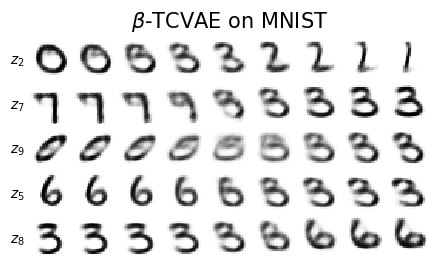

In [41]:
tc_mnist, _ = fit("mnist_tcvae6", DenseVAE(784, D_LATENT, rngs=nnx.Rngs(1)), tcvae_loss(6.0, N=60000), (Xtr_m,), epochs=EPOCHS_MNIST, seed=1)
D, R, kl = in_chunks(lambda x: rate_distortion(tc_mnist, x, jax.random.key(0)), Xte_m)
mu, lv = enc_fn(tc_mnist, to_unit(Xte_m[:M_DEC]))
o = kl_decomposition(mu, lv, jax.random.key(7))
print(f"beta-TCVAE (6): D = {D.mean():.1f}  R = {R.mean():.1f}  I = {o['mi']:.2f}  TC = {o['tc']:.2f}  dim-KL = {o['dimkl']:.2f}")
print(f"beta-VAE  (4): D = {mnist[4.0]['D']:.1f}  R = {mnist[4.0]['R']:.1f}  I = {decomp[4.0]['mi']:.2f}  TC = {decomp[4.0]['tc']:.2f}  dim-KL = {decomp[4.0]['dimkl']:.2f}")
dims = list(np.argsort(kl.mean(0))[::-1][:5])
fig, ax = plt.subplots(figsize=(5.2, 3.2))
show_rows(traversal_rows(tc_mnist, enc_fn(tc_mnist, to_unit(Xte_m[i_seed:i_seed + 1]))[0][0], dims), [f"$z_{{{k + 1}}}$" for k in dims], ax)
ax.set_title("$\\beta$-TCVAE on MNIST"); plt.show()

<hr/>
## Summary

A β-VAE minimises $\mathcal L_\beta=D+\beta R$: the distortion $D$ (reconstruction error) plus $\beta$ times the rate $R$ (the KL divergence of each image's code from the prior, in nats). For $\beta=1$ this is minus the evidence lower bound of the VAE. The weight $\beta$ is minus the slope of the rate–distortion curve at the selected model, and, in the free-energy reading of Lab 024, a temperature that weights the entropy of the code: the optimal code is the posterior tempered by $1/\beta$. The rate splits exactly into the index-code mutual information, the total correlation of the latent coordinates and the dimension-wise KL; the total correlation is the part that measures dependence between coordinates, and the β-TCVAE penalises it alone.

On MNIST the loss behaves as the theory says: as $\beta$ grows from 0.5 to 8, the rate falls from 22.9 to 4.5 nats, the distortion rises from 85.2 to 138.5 nats, reconstructions and samples blur, up to five of ten coordinates switch off, and the total correlation falls from 14.50 to 0.26 nats, while traversals still mix style with digit identity, a discrete factor that a continuous Gaussian code cannot isolate. On dSprites, where the factors are known, the mutual information gap measures disentangling: it grows from 0.036 for the VAE to 0.097 for $\beta=4$ and 0.222 for $\beta=16$, whose three active coordinates are $x$, $y$ and scale, while the β-TCVAE (0.164) isolates the scale at a much lower distortion, and no model learns the orientation. On CelebA a β-VAE with $\beta=3$ on $32\times32$ faces finds coordinates for background, illumination, skin and hair colour and hair length, weakly related to the 40 attributes, and the glasses, male and smile directions exist but are faint; the published models, larger and trained longer, isolate pose and smile. On spin snapshots the β-VAE becomes an interpretability tool: trained without labels on Ising snapshots, one coordinate is the magnetisation ($\rho=0.99$), and on $J_1$–$J_2$ snapshots the $\beta=4$ model devotes one coordinate each to $m$, $m_x$ and $m_y$ ($|\rho|=0.80$, 0.97, 0.98), whereas with $\beta=1$ the stripe order parameters are mixed; a linear fit by simple functions of the spins then names each coordinate with $R^2\ge0.98$.

None of this is guaranteed. A rotation of the latent space leaves the data distribution unchanged, so disentangling depends on the assumptions built into the model, the data and the seed (Locatello *et al.*), and every coordinate found has to be identified afterwards against known quantities. Conditioning, as in the cVAE, is the supervised alternative: it guarantees control of a labelled factor but cannot discover new ones.

References (in the order of first use): I. Higgins *et al.*, ICLR 2017, [OpenReview](https://openreview.net/forum?id=Sy2fzU9gl); A. A. Alemi *et al.*, ICML 2018, [PMLR 80, 159](https://proceedings.mlr.press/v80/alemi18a.html); M. D. Hoffman, M. J. Johnson, NIPS 2016 Workshop on Advances in Approximate Bayesian Inference, [PDF](https://web.archive.org/web/2019/http://approximateinference.org/accepted/HoffmanJohnson2016.pdf); R. T. Q. Chen, X. Li, R. Grosse, D. Duvenaud, NeurIPS 2018, [arXiv:1802.04942](https://arxiv.org/abs/1802.04942); H. Kim, A. Mnih, ICML 2018, [PMLR 80, 2649](https://proceedings.mlr.press/v80/kim18b.html); F. Locatello *et al.*, ICML 2019, [PMLR 97, 4114](https://proceedings.mlr.press/v97/locatello19a.html); L. Matthey, I. Higgins, D. Hassabis, A. Lerchner, dSprites (2017), [GitHub](https://github.com/deepmind/dsprites-dataset); Z. Liu, P. Luo, X. Wang, X. Tang, ICCV 2015, [doi:10.1109/ICCV.2015.425](https://doi.org/10.1109/ICCV.2015.425); A. Radford, L. Metz, S. Chintala, [arXiv:1511.06434](https://arxiv.org/abs/1511.06434); L. Wang, Phys. Rev. B **94**, 195105 (2016); S. J. Wetzel, Phys. Rev. E **96**, 022140 (2017); R. Iten, T. Metger, H. Wilming, L. del Rio, R. Renner, Phys. Rev. Lett. **124**, 010508 (2020). For a gentle review of the β-VAE and its capacity-controlled variant see C. P. Burgess *et al.*, *Understanding disentangling in β-VAE*, [arXiv:1804.03599](https://arxiv.org/abs/1804.03599).

The last cell stores the numbers quoted on the Lecture 6 slides.

In [42]:
nums["runtime_s"] = round(time.time() - t_start, 1)
with open(f"{OUT}/numbers_lab026.json", "w") as fh:
    json.dump(nums, fh, indent=1, default=float)

mn, dsn = nums["mnist"], nums["dsprites"]
ib, jb = nums["ising"], nums["j1j2"]
macros = {f"bvaeR{k.replace('.', 'p')}": f"{v['R']:.1f}" for k, v in mn.items()}
macros.update({f"bvaeD{k.replace('.', 'p')}": f"{v['D']:.1f}" for k, v in mn.items()})
macros.update({f"bvaeAct{k.replace('.', 'p')}": f"{v['active']}" for k, v in mn.items()})
macros.update({f"bvaeTC{k.replace('.', 'p')}": f"{v['tc']:.2f}" for k, v in nums["mnist_decomposition"].items()})
macros.update({f"bvaeMI{k.replace('.', 'p')}": f"{v['mi']:.2f}" for k, v in nums["mnist_decomposition"].items()})
macros.update({f"migds{k.replace('ds_', '')}": f"{v['MIG']:.2f}" for k, v in dsn.items()})
macros.update({f"dsR{k.replace('ds_', '')}": f"{v['R']:.1f}" for k, v in dsn.items()})
macros.update({f"dsD{k.replace('ds_', '')}": f"{v['D']:.1f}" for k, v in dsn.items()})
macros.update({"celbeta": f"{nums['celeba']['beta']:g}", "celR": f"{nums['celeba']['R']:.1f}", "celD": f"{nums['celeba']['D']:.0f}",
               "celact": f"{nums['celeba']['active']}", "celmin": f"{nums['celeba']['train_minutes']:.0f}",
               "migtrue": f"{nums['mig_checks']['true factors, 20 bins']:.2f}", "migrot": f"{nums['mig_checks']['x, y rotated by 45 degrees']:.2f}",
               "migrand": f"{nums['mig_checks']['random code']:.2f}"})
with open("../beamer/sections/nb_numbers_lab026.tex", "w") as fh:
    for k, v in macros.items():
        fh.write(f"\\setnbnum{{{k}}}{{{v}}}\n")
print(open("../beamer/sections/nb_numbers_lab026.tex").read())
print(f"total runtime {nums['runtime_s'] / 60:.1f} min")

\setnbnum{bvaeR0p5}{22.9}
\setnbnum{bvaeR1}{18.4}
\setnbnum{bvaeR2}{13.5}
\setnbnum{bvaeR4}{8.7}
\setnbnum{bvaeR8}{4.5}
\setnbnum{bvaeD0p5}{85.2}
\setnbnum{bvaeD1}{88.7}
\setnbnum{bvaeD2}{95.9}
\setnbnum{bvaeD4}{111.5}
\setnbnum{bvaeD8}{138.5}
\setnbnum{bvaeAct0p5}{10}
\setnbnum{bvaeAct1}{10}
\setnbnum{bvaeAct2}{10}
\setnbnum{bvaeAct4}{8}
\setnbnum{bvaeAct8}{5}
\setnbnum{bvaeTC0p5}{14.50}
\setnbnum{bvaeTC1}{10.22}
\setnbnum{bvaeTC2}{5.66}
\setnbnum{bvaeTC4}{1.69}
\setnbnum{bvaeTC8}{0.26}
\setnbnum{bvaeMI0p5}{7.59}
\setnbnum{bvaeMI1}{7.55}
\setnbnum{bvaeMI2}{7.38}
\setnbnum{bvaeMI4}{6.53}
\setnbnum{bvaeMI8}{3.86}
\setnbnum{migdsbeta1}{0.04}
\setnbnum{migdsbeta4}{0.10}
\setnbnum{migdsbeta16}{0.22}
\setnbnum{migdstcvae6}{0.16}
\setnbnum{dsRbeta1}{11.3}
\setnbnum{dsRbeta4}{6.2}
\setnbnum{dsRbeta16}{2.6}
\setnbnum{dsRtcvae6}{6.2}
\setnbnum{dsDbeta1}{24.9}
\setnbnum{dsDbeta4}{35.9}
\setnbnum{dsDbeta16}{64.5}
\setnbnum{dsDtcvae6}{36.1}
\setnbnum{celbeta}{3}
\setnbnum{celR}{15.8}
\setnbnum{cel